In [ ]:

from google.colab import files
import os

DATA_DIR = "/content/CICIDS2017"

os.makedirs(DATA_DIR, exist_ok=True)

print("Select all 8 CICIDS2017 CSV files.")

uploaded = files.upload()

for filename, content in uploaded.items():

    destination = os.path.join(DATA_DIR, filename)

    with open(destination, "wb") as f:
        f.write(content)

print("\n" + "=" * 60)
print("UPLOAD COMPLETED")
print("=" * 60)

print("Total uploaded files:", len(uploaded))

print("\nUploaded filenames:")

for filename in sorted(os.listdir(DATA_DIR)):
    print(filename)


Select all 8 CICIDS2017 CSV files.


Saving MachineLearningCSV.zip to MachineLearningCSV.zip

UPLOAD COMPLETED
Total uploaded files: 1

Uploaded filenames:
MachineLearningCSV.zip


In [ ]:

from google.colab import files
import os

DATA_DIR = "/content/CICIDS2017"

os.makedirs(DATA_DIR, exist_ok=True)

print("Select all 8 CICIDS2017 CSV files.")

uploaded = files.upload()

for filename, content in uploaded.items():

    destination = os.path.join(DATA_DIR, filename)

    with open(destination, "wb") as f:
        f.write(content)

print("\n" + "=" * 60)
print("UPLOAD COMPLETED")
print("=" * 60)

print("Total uploaded files:", len(uploaded))

print("\nUploaded filenames:")

for filename in sorted(os.listdir(DATA_DIR)):
    print(filename)

from google.colab import files
import os

DATA_DIR = "/content/CICIDS2017"

os.makedirs(DATA_DIR, exist_ok=True)

print("Select all 8 CICIDS2017 CSV files.")

uploaded = files.upload()

for filename, content in uploaded.items():

    destination = os.path.join(DATA_DIR, filename)

    with open(destination, "wb") as f:
        f.write(content)

print("\n" + "=" * 60)
print("UPLOAD COMPLETED")
print("=" * 60)

print("Total uploaded files:", len(uploaded))

print("\nUploaded filenames:")

for filename in sorted(os.listdir(DATA_DIR)):
    print(filename)

from google.colab import files
import os

DATA_DIR = "/content/CICIDS2017"

os.makedirs(DATA_DIR, exist_ok=True)

print("Select all 8 CICIDS2017 CSV files.")

uploaded = files.upload()

for filename, content in uploaded.items():

    destination = os.path.join(DATA_DIR, filename)

    with open(destination, "wb") as f:
        f.write(content)

print("\n" + "=" * 60)
print("UPLOAD COMPLETED")
print("=" * 60)

print("Total uploaded files:", len(uploaded))

print("\nUploaded filenames:")

for filename in sorted(os.listdir(DATA_DIR)):
    print(filename)


Extracting CICIDS2017 dataset...

EXTRACTION COMPLETED
Total CSV files found: 8

EXTRACTED FILES:
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv | 73.55 MB
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv | 73.34 MB
Friday-WorkingHours-Morning.pcap_ISCX.csv | 55.62 MB
Monday-WorkingHours.pcap_ISCX.csv | 168.73 MB
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv | 79.25 MB
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv | 49.61 MB
Tuesday-WorkingHours.pcap_ISCX.csv | 128.82 MB
Wednesday-workingHours.pcap_ISCX.csv | 214.74 MB


In [ ]:

import os
import glob
import gc
import pandas as pd
import numpy as np

DATA_DIR = "/content/CICIDS2017"

csv_files = sorted(
    glob.glob(
        os.path.join(DATA_DIR, "**", "*.csv"),
        recursive=True
    )
)

print("=" * 100)
print("CICIDS2017 DATASET AUDIT")
print("=" * 100)

if len(csv_files) != 8:
    raise ValueError(f"Expected 8 CSV files, found {len(csv_files)}")

file_results = []
all_label_counts = {}
reference_columns = None

CHUNK_SIZE = 100000

for file_path in csv_files:

    filename = os.path.basename(file_path)

    print("\n" + "=" * 85)
    print("AUDITING:", filename)
    print("=" * 85)

    total_rows = 0
    missing_values = 0
    infinite_values = 0
    duplicate_rows = 0
    label_counts = {}

    file_columns = None

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()

        if file_columns is None:
            file_columns = list(chunk.columns)

            if reference_columns is None:
                reference_columns = file_columns

        total_rows += len(chunk)

        # Missing values
        missing_values += int(chunk.isna().sum().sum())

        # Duplicate rows within each chunk
        duplicate_rows += int(chunk.duplicated().sum())

        # Infinite numeric values
        numeric = chunk.select_dtypes(include=[np.number])

        if not numeric.empty:
            infinite_values += int(
                np.isinf(numeric.to_numpy()).sum()
            )

        # Label distribution
        label_col = next(
            (
                col for col in chunk.columns
                if col.strip().lower() == "label"
            ),
            None
        )

        if label_col is not None:

            labels = (
                chunk[label_col]
                .astype(str)
                .str.strip()
            )

            counts = labels.value_counts()

            for label, count in counts.items():

                label_counts[label] = (
                    label_counts.get(label, 0) + int(count)
                )

        del chunk

    same_columns = set(file_columns) == set(reference_columns)

    file_results.append({
        "File": filename,
        "Rows": total_rows,
        "Columns": len(file_columns),
        "Missing Values": missing_values,
        "Infinite Values": infinite_values,
        "Duplicate Rows (within chunks)": duplicate_rows,
        "Columns Consistent": same_columns
    })

    for label, count in label_counts.items():

        all_label_counts[label] = (
            all_label_counts.get(label, 0) + count
        )

    print("Rows:", f"{total_rows:,}")
    print("Columns:", len(file_columns))
    print("Missing values:", f"{missing_values:,}")
    print("Infinite values:", f"{infinite_values:,}")
    print("Duplicate rows within chunks:", f"{duplicate_rows:,}")
    print("Column structure consistent:", same_columns)

    print("\nLabels:")

    for label, count in sorted(label_counts.items()):
        print(f"{label}: {count:,}")

    gc.collect()


# ============================================================
# FINAL REPORT
# ============================================================

file_audit_df = pd.DataFrame(file_results)

label_audit_df = pd.DataFrame(
    [
        {"Label": label, "Count": count}
        for label, count in all_label_counts.items()
    ]
).sort_values("Count", ascending=False)

print("\n" + "=" * 100)
print("FINAL FILE AUDIT")
print("=" * 100)

display(file_audit_df)

print("\n" + "=" * 100)
print("COMBINED LABEL DISTRIBUTION")
print("=" * 100)

display(label_audit_df)

print("\nTOTAL FILES:", len(file_audit_df))
print("TOTAL ROWS:", f"{file_audit_df['Rows'].sum():,}")
print("TOTAL LABELS:", len(label_audit_df))

print("\nAUDIT COMPLETED")


CICIDS2017 DATASET AUDIT

AUDITING: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Rows: 225,745
Columns: 79
Missing values: 4
Infinite values: 64
Duplicate rows within chunks: 1,870
Column structure consistent: True

Labels:
BENIGN: 97,718
DDoS: 128,027

AUDITING: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Rows: 286,467
Columns: 79
Missing values: 15
Infinite values: 727
Duplicate rows within chunks: 47,775
Column structure consistent: True

Labels:
BENIGN: 127,537
PortScan: 158,930

AUDITING: Friday-WorkingHours-Morning.pcap_ISCX.csv
Rows: 191,033
Columns: 79
Missing values: 28
Infinite values: 216
Duplicate rows within chunks: 5,404
Column structure consistent: True

Labels:
BENIGN: 189,067
Bot: 1,966

AUDITING: Monday-WorkingHours.pcap_ISCX.csv
Rows: 529,918
Columns: 79
Missing values: 64
Infinite values: 810
Duplicate rows within chunks: 17,480
Column structure consistent: True

Labels:
BENIGN: 529,918

AUDITING: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.

,File,Rows,Columns,Missing Values,Infinite Values,Duplicate Rows (within chunks),Columns Consistent
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,79,4,64,1870,True
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,79,15,727,47775,True
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,79,28,216,5404,True
3,Monday-WorkingHours.pcap_ISCX.csv,529918,79,64,810,17480,True
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,79,18,396,28104,True
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,79,20,250,4829,True
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,79,201,327,16647,True
7,Wednesday-workingHours.pcap_ISCX.csv,692703,79,1008,1586,71964,True



COMBINED LABEL DISTRIBUTION


,Label,Count
1,BENIGN,2273097
10,DoS Hulk,231073
2,PortScan,158930
0,DDoS,128027
13,DoS GoldenEye,10293
8,FTP-Patator,7938
9,SSH-Patator,5897
11,DoS slowloris,5796
12,DoS Slowhttptest,5499
3,Bot,1966



TOTAL FILES: 8
TOTAL ROWS: 2,830,743
TOTAL LABELS: 15

AUDIT COMPLETED


In [ ]:

import os
import glob
import pandas as pd
import numpy as np
from collections import Counter

DATA_DIR = "/content/CICIDS2017"

csv_files = sorted(
    glob.glob(
        os.path.join(DATA_DIR, "**", "*.csv"),
        recursive=True
    )
)

CHUNK_SIZE = 100000

print("=" * 100)
print("CICIDS2017 FEATURE AND TIMESTAMP INVESTIGATION")
print("=" * 100)

reference_columns = None
all_labels = Counter()

for file_path in csv_files:

    filename = os.path.basename(file_path)

    print("\n" + "=" * 90)
    print("FILE:", filename)
    print("=" * 90)

    first_chunk = pd.read_csv(
        file_path,
        nrows=5,
        low_memory=False,
        encoding="utf-8-sig"
    )

    first_chunk.columns = (
        first_chunk.columns
        .str.strip()
        .str.replace("\ufeff", "", regex=False)
    )

    columns = list(first_chunk.columns)

    if reference_columns is None:
        reference_columns = columns

        print("\nALL FEATURE COLUMNS:")
        for i, col in enumerate(columns):
            print(i, repr(col))

    print("\nColumn count:", len(columns))
    print("Same column order:", columns == reference_columns)

    # Find important columns
    timestamp_cols = [
        c for c in columns
        if "timestamp" in c.lower() or "time" in c.lower()
    ]

    identifier_cols = [
        c for c in columns
        if any(term in c.lower() for term in [
            "flow id", "src ip", "dst ip", "source ip",
            "destination ip", "src port", "dst port"
        ])
    ]

    label_col = next(
        (c for c in columns if c.lower() == "label"),
        None
    )

    print("\nTimestamp columns:", timestamp_cols)
    print("Identifier-like columns:", identifier_cols)
    print("Label column:", label_col)

    timestamp_min = None
    timestamp_max = None
    timestamp_invalid = 0
    timestamp_total = 0

    numeric_conversion_errors = Counter()
    labels_in_file = Counter()

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE,
        low_memory=False,
        encoding="utf-8-sig"
    ):

        chunk.columns = (
            chunk.columns
            .str.strip()
            .str.replace("\ufeff", "", regex=False)
        )

        # Exact label strings
        if label_col:

            values = (
                chunk[label_col]
                .astype(str)
                .str.strip()
            )

            labels_in_file.update(values.tolist())
            all_labels.update(values.tolist())

        # Timestamp inspection
        for col in timestamp_cols:

            parsed = pd.to_datetime(
                chunk[col],
                errors="coerce"
            )

            timestamp_total += len(parsed)
            timestamp_invalid += int(parsed.isna().sum())

            current_min = parsed.min()
            current_max = parsed.max()

            if pd.notna(current_min):
                if timestamp_min is None or current_min < timestamp_min:
                    timestamp_min = current_min

            if pd.notna(current_max):
                if timestamp_max is None or current_max > timestamp_max:
                    timestamp_max = current_max

        # Numeric conversion issues
        for col in chunk.columns:

            if col == label_col or col in timestamp_cols:
                continue

            if chunk[col].dtype == "object":

                converted = pd.to_numeric(
                    chunk[col],
                    errors="coerce"
                )

                invalid = (
                    chunk[col].notna()
                    & converted.isna()
                )

                if invalid.any():
                    numeric_conversion_errors[col] += int(invalid.sum())

        del chunk

    print("\nLABELS FOUND IN FILE:")

    for label, count in sorted(labels_in_file.items()):
        print(repr(label), ":", f"{count:,}")

    print("\nTIMESTAMP RANGE:")
    print("Minimum:", timestamp_min)
    print("Maximum:", timestamp_max)
    print("Invalid timestamp values:", f"{timestamp_invalid:,}")
    print("Timestamp records checked:", f"{timestamp_total:,}")

    print("\nNON-NUMERIC VALUES IN OBJECT COLUMNS:")

    if numeric_conversion_errors:
        for col, count in numeric_conversion_errors.most_common(15):
            print(repr(col), ":", f"{count:,}")
    else:
        print("No numeric conversion issues detected.")

print("\n" + "=" * 100)
print("EXACT COMBINED LABEL VALUES")
print("=" * 100)

for label, count in sorted(all_labels.items()):
    print(repr(label), ":", f"{count:,}")

print("\nFEATURE INVESTIGATION COMPLETED")


CICIDS2017 FEATURE AND TIMESTAMP INVESTIGATION

FILE: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

ALL FEATURE COLUMNS:
0 'Destination Port'
1 'Flow Duration'
2 'Total Fwd Packets'
3 'Total Backward Packets'
4 'Total Length of Fwd Packets'
5 'Total Length of Bwd Packets'
6 'Fwd Packet Length Max'
7 'Fwd Packet Length Min'
8 'Fwd Packet Length Mean'
9 'Fwd Packet Length Std'
10 'Bwd Packet Length Max'
11 'Bwd Packet Length Min'
12 'Bwd Packet Length Mean'
13 'Bwd Packet Length Std'
14 'Flow Bytes/s'
15 'Flow Packets/s'
16 'Flow IAT Mean'
17 'Flow IAT Std'
18 'Flow IAT Max'
19 'Flow IAT Min'
20 'Fwd IAT Total'
21 'Fwd IAT Mean'
22 'Fwd IAT Std'
23 'Fwd IAT Max'
24 'Fwd IAT Min'
25 'Bwd IAT Total'
26 'Bwd IAT Mean'
27 'Bwd IAT Std'
28 'Bwd IAT Max'
29 'Bwd IAT Min'
30 'Fwd PSH Flags'
31 'Bwd PSH Flags'
32 'Fwd URG Flags'
33 'Bwd URG Flags'
34 'Fwd Header Length'
35 'Bwd Header Length'
36 'Fwd Packets/s'
37 'Bwd Packets/s'
38 'Min Packet Length'
39 'Max Packet Length'
40 'Packet Lengt

In [ ]:

import os
import glob
import numpy as np
import pandas as pd
from collections import defaultdict

DATA_DIR = "/content/CICIDS2017"

csv_files = sorted(
    glob.glob(
        os.path.join(DATA_DIR, "**", "*.csv"),
        recursive=True
    )
)

feature_stats = defaultdict(lambda: {
    "min": np.inf,
    "max": -np.inf,
    "missing": 0,
    "infinite": 0,
    "negative": 0,
    "zero": 0,
    "rows": 0
})

constant_check = defaultdict(set)

CHUNK_SIZE = 100000

print("=" * 100)
print("CICIDS2017 NUMERICAL FEATURE AUDIT")
print("=" * 100)

for file_path in csv_files:

    print("\nProcessing:", os.path.basename(file_path))

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE,
        low_memory=False,
        encoding="utf-8-sig"
    ):

        chunk.columns = (
            chunk.columns.str.strip()
            .str.replace("\ufeff", "", regex=False)
        )

        feature_cols = [
            c for c in chunk.columns
            if c.strip().lower() != "label"
        ]

        for col in feature_cols:

            values = pd.to_numeric(
                chunk[col],
                errors="coerce"
            )

            stats = feature_stats[col]

            stats["rows"] += len(values)
            stats["missing"] += int(values.isna().sum())

            arr = values.to_numpy(dtype=np.float64)

            finite = np.isfinite(arr)

            stats["infinite"] += int(
                np.isinf(arr).sum()
            )

            stats["negative"] += int(
                (arr[finite] < 0).sum()
            )

            stats["zero"] += int(
                (arr[finite] == 0).sum()
            )

            if finite.any():

                stats["min"] = min(
                    stats["min"],
                    float(arr[finite].min())
                )

                stats["max"] = max(
                    stats["max"],
                    float(arr[finite].max())
                )

            # Track distinct values for constant-feature inspection.
            # More than one distinct value means non-constant.
            sample_values = pd.unique(values.dropna())

            for value in sample_values[:3]:
                constant_check[col].add(float(value))

        del chunk


# ============================================================
# BUILD FEATURE REPORT
# ============================================================

report = []

for col, stats in feature_stats.items():

    report.append({
        "Feature": col,
        "Minimum": stats["min"],
        "Maximum": stats["max"],
        "Missing": stats["missing"],
        "Infinite": stats["infinite"],
        "Negative Values": stats["negative"],
        "Zero Values": stats["zero"],
        "Constant Candidate": len(constant_check[col]) == 1
    })

feature_audit_df = pd.DataFrame(report)

feature_audit_df = feature_audit_df.sort_values(
    "Feature"
).reset_index(drop=True)

print("\n" + "=" * 100)
print("FEATURE AUDIT RESULTS")
print("=" * 100)

display(feature_audit_df)

print("\nFeatures checked:", len(feature_audit_df))

print(
    "Features with missing values:",
    (feature_audit_df["Missing"] > 0).sum()
)

print(
    "Features with infinite values:",
    (feature_audit_df["Infinite"] > 0).sum()
)

print(
    "Features with negative values:",
    (feature_audit_df["Negative Values"] > 0).sum()
)

print(
    "Constant candidates:",
    feature_audit_df["Constant Candidate"].sum()
)

# Save report
feature_audit_df.to_csv(
    "/content/CICIDS2017_feature_audit.csv",
    index=False
)

print("\nFeature audit saved.")


CICIDS2017 NUMERICAL FEATURE AUDIT

Processing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Processing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

Processing: Friday-WorkingHours-Morning.pcap_ISCX.csv

Processing: Monday-WorkingHours.pcap_ISCX.csv

Processing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv

Processing: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv

Processing: Tuesday-WorkingHours.pcap_ISCX.csv

Processing: Wednesday-workingHours.pcap_ISCX.csv

FEATURE AUDIT RESULTS


,Feature,Minimum,Maximum,Missing,Infinite,Negative Values,Zero Values,Constant Candidate
0,ACK Flag Count,0.0,1.0,0,0,0,1936669,False
1,Active Max,0.0,110000000.0,0,0,0,2271914,False
2,Active Mean,0.0,110000000.0,0,0,0,2271914,False
3,Active Min,0.0,110000000.0,0,0,0,2271914,False
4,Active Std,0.0,74200000.0,0,0,0,2625209,False
...,...,...,...,...,...,...,...,...
73,Total Length of Bwd Packets,0.0,655453030.0,0,0,0,707746,False
74,Total Length of Fwd Packets,0.0,12900000.0,0,0,0,449170,False
75,URG Flag Count,0.0,1.0,0,0,0,2562323,False
76,act_data_pkt_fwd,0.0,213557.0,0,0,0,962924,False



Features checked: 78
Features with missing values: 1
Features with infinite values: 2
Features with negative values: 13
Constant candidates: 8

Feature audit saved.


In [ ]:
import os
import glob
import numpy as np
import pandas as pd

DATA_DIR = "/content/CICIDS2017"
CHUNK_SIZE = 100000

csv_files = sorted(
    glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
)

col_a = "Fwd Header Length"
col_b = "Fwd Header Length.1"

print("=" * 100)
print("ACTUAL HEADER INSPECTION")
print("=" * 100)

for file_path in csv_files:
    header = pd.read_csv(
        file_path,
        nrows=0,
        encoding="utf-8-sig"
    ).columns

    normalized = [
        str(c).replace("\ufeff", "").strip()
        for c in header
    ]

    matches = [
        c for c in normalized
        if "Fwd Header Length" in c
    ]

    print(f"\n{os.path.basename(file_path)}")
    print("Matching columns:", matches)

# --------------------------------------------------
# EXACT DUPLICATE VERIFICATION
# --------------------------------------------------

print("\n" + "=" * 100)
print("EXACT DUPLICATE COLUMN VERIFICATION")
print("=" * 100)

for file_path in csv_files:

    file_name = os.path.basename(file_path)

    mismatch_count = 0
    total_rows = 0
    max_difference = 0.0
    columns_found = False

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig",
        low_memory=False
    ):

        chunk.columns = [
            str(c).replace("\ufeff", "").strip()
            for c in chunk.columns
        ]

        if col_a not in chunk.columns or col_b not in chunk.columns:
            continue

        columns_found = True

        a = pd.to_numeric(chunk[col_a], errors="coerce")
        b = pd.to_numeric(chunk[col_b], errors="coerce")

        equal = (a == b) | (a.isna() & b.isna())

        mismatch_count += int((~equal).sum())
        total_rows += len(chunk)

        valid = a.notna() & b.notna()

        if valid.any():
            differences = np.abs(
                a[valid].to_numpy(dtype=np.float64) -
                b[valid].to_numpy(dtype=np.float64)
            )

            max_difference = max(
                max_difference,
                float(differences.max())
            )

    print(f"\nFile: {file_name}")

    if not columns_found:
        print("Both columns were not found together.")
        continue

    print(f"Rows checked: {total_rows:,}")
    print(f"Mismatched rows: {mismatch_count:,}")
    print(f"Maximum absolute difference: {max_difference}")

    if mismatch_count == 0:
        print("Result: EXACT DUPLICATES")
    else:
        print("Result: NOT EXACT DUPLICATES")

print("\nCELL 6 COMPLETED")

ACTUAL HEADER INSPECTION

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Matching columns: ['Fwd Header Length', 'Fwd Header Length.1']

Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Matching columns: ['Fwd Header Length', 'Fwd Header Length.1']

Friday-WorkingHours-Morning.pcap_ISCX.csv
Matching columns: ['Fwd Header Length', 'Fwd Header Length.1']

Monday-WorkingHours.pcap_ISCX.csv
Matching columns: ['Fwd Header Length', 'Fwd Header Length.1']

Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Matching columns: ['Fwd Header Length', 'Fwd Header Length.1']

Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Matching columns: ['Fwd Header Length', 'Fwd Header Length.1']

Tuesday-WorkingHours.pcap_ISCX.csv
Matching columns: ['Fwd Header Length', 'Fwd Header Length.1']

Wednesday-workingHours.pcap_ISCX.csv
Matching columns: ['Fwd Header Length', 'Fwd Header Length.1']

EXACT DUPLICATE COLUMN VERIFICATION

File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Rows 

In [ ]:
import os
import glob
import numpy as np
import pandas as pd

DATA_DIR = "/content/CICIDS2017"
CHUNK_SIZE = 100000

negative_features = [
    "Bwd Header Length",
    "Flow Bytes/s",
    "Flow Duration",
    "Flow IAT Max",
    "Flow IAT Mean",
    "Flow IAT Min",
    "Flow Packets/s",
    "Fwd Header Length",
    "Fwd Header Length.1",
    "Fwd IAT Min",
    "Init_Win_bytes_backward",
    "Init_Win_bytes_forward",
    "min_seg_size_forward"
]

csv_files = sorted(
    glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
)

summary = []
examples = []

print("=" * 100)
print("NEGATIVE VALUE INVESTIGATION BY LABEL")
print("=" * 100)

for file_path in csv_files:

    file_name = os.path.basename(file_path)

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig",
        low_memory=False
    ):

        chunk.columns = [
            str(c).replace("\ufeff", "").strip()
            for c in chunk.columns
        ]

        chunk["Label"] = chunk["Label"].astype(str).str.strip()

        for feature in negative_features:

            if feature not in chunk.columns:
                continue

            values = pd.to_numeric(
                chunk[feature],
                errors="coerce"
            )

            mask = values < 0

            if not mask.any():
                continue

            negative = values[mask]

            grouped = (
                chunk.loc[mask, ["Label"]]
                .assign(_value=negative)
                .groupby("Label")["_value"]
                .agg(["count", "min", "max"])
                .reset_index()
            )

            for _, row in grouped.iterrows():
                summary.append({
                    "File": file_name,
                    "Feature": feature,
                    "Label": row["Label"],
                    "Negative Count": int(row["count"]),
                    "Minimum": float(row["min"]),
                    "Maximum": float(row["max"])
                })

            if len(examples) < 100:
                sample = chunk.loc[
                    mask,
                    ["Label", feature]
                ].head(5)

                for _, row in sample.iterrows():
                    examples.append({
                        "File": file_name,
                        "Feature": feature,
                        "Label": row["Label"],
                        "Negative Value": row[feature]
                    })

# --------------------------------------------------
# DISPLAY SUMMARY
# --------------------------------------------------

summary_df = pd.DataFrame(summary)

if not summary_df.empty:

    summary_df = (
        summary_df
        .groupby(["Feature", "Label"], as_index=False)
        .agg({
            "Negative Count": "sum",
            "Minimum": "min",
            "Maximum": "max"
        })
        .sort_values(
            ["Feature", "Negative Count"],
            ascending=[True, False]
        )
    )

    print("\nNEGATIVE VALUES BY FEATURE AND LABEL")
    print(summary_df.to_string(index=False))

    summary_df.to_csv(
        "/content/CICIDS2017_negative_value_audit.csv",
        index=False
    )

else:
    print("No negative values found.")

print("\n" + "=" * 100)
print("REPRESENTATIVE NEGATIVE VALUE EXAMPLES")
print("=" * 100)

examples_df = pd.DataFrame(examples)

if not examples_df.empty:
    print(examples_df.to_string(index=False))

print("\nAudit saved to:")
print("/content/CICIDS2017_negative_value_audit.csv")

print("\nCELL 7 COMPLETED")

NEGATIVE VALUE INVESTIGATION BY LABEL

NEGATIVE VALUES BY FEATURE AND LABEL
                Feature            Label  Negative Count       Minimum       Maximum
      Bwd Header Length           BENIGN              22 -1.073741e+09 -8.388501e+07
           Flow Bytes/s           BENIGN              85 -2.610000e+08 -4.615385e+05
          Flow Duration           BENIGN             115 -1.300000e+01 -1.000000e+00
           Flow IAT Max           BENIGN             115 -1.300000e+01 -1.000000e+00
          Flow IAT Mean           BENIGN             115 -1.300000e+01 -1.000000e+00
           Flow IAT Min           BENIGN            2697 -1.400000e+01 -1.000000e+00
           Flow IAT Min         DoS Hulk             159 -1.300000e+01 -1.000000e+00
           Flow IAT Min             DDoS              19 -1.200000e+01 -1.000000e+00
           Flow IAT Min    DoS GoldenEye               5 -1.100000e+01 -1.000000e+00
           Flow IAT Min      FTP-Patator               4 -1.000000e+00 -1.

In [ ]:
import os
import glob
import numpy as np
import pandas as pd

DATA_DIR = "/content/CICIDS2017"
CHUNK_SIZE = 100000

# Physically nonnegative features.
invalid_negative_features = [
    "Bwd Header Length",
    "Flow Bytes/s",
    "Flow Duration",
    "Flow IAT Max",
    "Flow IAT Mean",
    "Flow IAT Min",
    "Flow Packets/s",
    "Fwd Header Length",
    "Fwd Header Length.1",
    "Fwd IAT Min",
    "min_seg_size_forward"
]

# Special sentinel features.
sentinel_features = [
    "Init_Win_bytes_forward",
    "Init_Win_bytes_backward"
]

csv_files = sorted(
    glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
)

total_rows = 0
rows_with_invalid_negative = 0
rows_with_multiple_invalid = 0
rows_with_sentinel = 0
rows_with_both = 0

invalid_feature_counts = {
    feature: 0 for feature in invalid_negative_features
}

sentinel_counts = {
    feature: {"minus_one": 0, "other_negative": 0, "nonnegative": 0}
    for feature in sentinel_features
}

print("=" * 100)
print("INVALID VALUE AND SENTINEL OVERLAP AUDIT")
print("=" * 100)

for file_path in csv_files:

    print("Processing:", os.path.basename(file_path))

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig",
        low_memory=False
    ):

        chunk.columns = [
            str(c).replace("\ufeff", "").strip()
            for c in chunk.columns
        ]

        total_rows += len(chunk)

        invalid_masks = []

        for feature in invalid_negative_features:

            values = pd.to_numeric(
                chunk[feature],
                errors="coerce"
            )

            mask = values < 0

            invalid_feature_counts[feature] += int(mask.sum())
            invalid_masks.append(mask.to_numpy())

        invalid_matrix = np.column_stack(invalid_masks)

        invalid_row_mask = invalid_matrix.any(axis=1)

        rows_with_invalid_negative += int(invalid_row_mask.sum())

        rows_with_multiple_invalid += int(
            (invalid_matrix.sum(axis=1) > 1).sum()
        )

        sentinel_matrix = []

        for feature in sentinel_features:

            values = pd.to_numeric(
                chunk[feature],
                errors="coerce"
            )

            minus_one = values == -1
            other_negative = (values < 0) & (~minus_one)
            nonnegative = values >= 0

            sentinel_counts[feature]["minus_one"] += int(minus_one.sum())
            sentinel_counts[feature]["other_negative"] += int(
                other_negative.sum()
            )
            sentinel_counts[feature]["nonnegative"] += int(
                nonnegative.sum()
            )

            sentinel_matrix.append(
                (minus_one | other_negative).to_numpy()
            )

        sentinel_row_mask = np.column_stack(sentinel_matrix).any(axis=1)

        rows_with_sentinel += int(sentinel_row_mask.sum())

        rows_with_both += int(
            (invalid_row_mask & sentinel_row_mask).sum()
        )

# --------------------------------------------------
# RESULTS
# --------------------------------------------------

print("\n" + "=" * 100)
print("ROW-LEVEL ANOMALY SUMMARY")
print("=" * 100)

print(f"Total rows: {total_rows:,}")
print(
    f"Rows with at least one invalid negative feature: "
    f"{rows_with_invalid_negative:,}"
)
print(
    f"Rows with multiple invalid negative features: "
    f"{rows_with_multiple_invalid:,}"
)
print(
    f"Rows with initial-window negative sentinel: "
    f"{rows_with_sentinel:,}"
)
print(
    f"Rows containing both anomaly types: "
    f"{rows_with_both:,}"
)

print("\n" + "=" * 100)
print("INVALID NEGATIVE COUNTS BY FEATURE")
print("=" * 100)

for feature, count in invalid_feature_counts.items():
    print(f"{feature:<35} {count:>12,}")

print("\n" + "=" * 100)
print("INITIAL WINDOW SENTINEL COUNTS")
print("=" * 100)

for feature, counts in sentinel_counts.items():

    print(f"\n{feature}")
    print(f"  Exactly -1:       {counts['minus_one']:,}")
    print(f"  Other negatives:  {counts['other_negative']:,}")
    print(f"  Nonnegative:      {counts['nonnegative']:,}")

print("\nCELL 8 COMPLETED")

INVALID VALUE AND SENTINEL OVERLAP AUDIT
Processing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Processing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Processing: Friday-WorkingHours-Morning.pcap_ISCX.csv
Processing: Monday-WorkingHours.pcap_ISCX.csv
Processing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Processing: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Processing: Tuesday-WorkingHours.pcap_ISCX.csv
Processing: Wednesday-workingHours.pcap_ISCX.csv

ROW-LEVEL ANOMALY SUMMARY
Total rows: 2,830,743
Rows with at least one invalid negative feature: 2,926
Rows with multiple invalid negative features: 167
Rows with initial-window negative sentinel: 1,441,552
Rows containing both anomaly types: 51

INVALID NEGATIVE COUNTS BY FEATURE
Bwd Header Length                             22
Flow Bytes/s                                  85
Flow Duration                                115
Flow IAT Max                                 115
Flow IAT Mean      

In [ ]:
import os
import glob
import numpy as np
import pandas as pd

DATA_DIR = "/content/CICIDS2017"
CHUNK_SIZE = 100000

csv_files = sorted(
    glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
)

all_hashes = []
all_file_ids = []

print("=" * 100)
print("CICIDS2017 GLOBAL DUPLICATE RECORD AUDIT")
print("=" * 100)

for file_id, file_path in enumerate(csv_files):

    file_name = os.path.basename(file_path)
    file_rows = 0

    print("\nProcessing:", file_name)

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig",
        low_memory=False
    ):

        chunk.columns = [
            str(c).replace("\ufeff", "").strip()
            for c in chunk.columns
        ]

        # Normalize label whitespace, preserving the original class names.
        chunk["Label"] = chunk["Label"].astype(str).str.strip()

        # Hash every column, including Label.
        hashes = pd.util.hash_pandas_object(
            chunk,
            index=False
        ).to_numpy(dtype=np.uint64)

        all_hashes.append(hashes)
        all_file_ids.append(
            np.full(len(hashes), file_id, dtype=np.int8)
        )

        file_rows += len(chunk)

    print(f"Rows processed: {file_rows:,}")

# --------------------------------------------------
# GLOBAL DUPLICATE ANALYSIS
# --------------------------------------------------

hashes = np.concatenate(all_hashes)
file_ids = np.concatenate(all_file_ids)

unique_hashes, inverse, counts = np.unique(
    hashes,
    return_inverse=True,
    return_counts=True
)

duplicate_group_mask = counts > 1
duplicate_row_mask = counts[inverse] > 1

duplicate_groups = int(duplicate_group_mask.sum())
duplicate_rows = int(duplicate_row_mask.sum())
excess_duplicate_rows = int((counts[counts > 1] - 1).sum())

print("\n" + "=" * 100)
print("GLOBAL DUPLICATE SUMMARY")
print("=" * 100)

print(f"Total records: {len(hashes):,}")
print(f"Unique record hashes: {len(unique_hashes):,}")
print(f"Duplicate groups: {duplicate_groups:,}")
print(f"Rows belonging to duplicate groups: {duplicate_rows:,}")
print(f"Excess duplicate records: {excess_duplicate_rows:,}")

# --------------------------------------------------
# DUPLICATES SPANNING MULTIPLE FILES
# --------------------------------------------------

cross_file_groups = 0
cross_file_excess_rows = 0

for group_id in np.flatnonzero(duplicate_group_mask):

    positions = np.flatnonzero(inverse == group_id)
    files_in_group = np.unique(file_ids[positions])

    if len(files_in_group) > 1:
        cross_file_groups += 1
        cross_file_excess_rows += len(positions) - 1

print("\n" + "=" * 100)
print("CROSS-FILE DUPLICATE SUMMARY")
print("=" * 100)

print(f"Duplicate groups spanning multiple files: {cross_file_groups:,}")
print(f"Excess records in cross-file groups: {cross_file_excess_rows:,}")

print("\nCELL 9 COMPLETED")

CICIDS2017 GLOBAL DUPLICATE RECORD AUDIT

Processing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Rows processed: 225,745

Processing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Rows processed: 286,467

Processing: Friday-WorkingHours-Morning.pcap_ISCX.csv
Rows processed: 191,033

Processing: Monday-WorkingHours.pcap_ISCX.csv
Rows processed: 529,918

Processing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Rows processed: 288,602

Processing: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Rows processed: 170,366

Processing: Tuesday-WorkingHours.pcap_ISCX.csv
Rows processed: 445,909

Processing: Wednesday-workingHours.pcap_ISCX.csv
Rows processed: 692,703

GLOBAL DUPLICATE SUMMARY
Total records: 2,830,743
Unique record hashes: 2,522,362
Duplicate groups: 95,169
Rows belonging to duplicate groups: 403,550
Excess duplicate records: 308,381

CROSS-FILE DUPLICATE SUMMARY
Duplicate groups spanning multiple files: 33,563
Excess records in cross-file grou

In [ ]:
import os
import glob
import numpy as np
import pandas as pd

DATA_DIR = "/content/CICIDS2017"
CHUNK_SIZE = 100000

csv_files = sorted(
    glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
)

feature_hash_parts = []
label_parts = []
file_id_parts = []

print("=" * 100)
print("FEATURE-ONLY DUPLICATE AND LABEL-CONFLICT AUDIT")
print("=" * 100)

for file_id, file_path in enumerate(csv_files):

    print("\nProcessing:", os.path.basename(file_path))

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig",
        low_memory=False
    ):

        chunk.columns = [
            str(c).replace("\ufeff", "").strip()
            for c in chunk.columns
        ]

        labels = chunk["Label"].astype(str).str.strip().to_numpy()

        features = chunk.drop(columns=["Label"]).copy()

        # Normalize numeric representation across CSV files.
        for col in features.columns:
            features[col] = pd.to_numeric(
                features[col],
                errors="coerce"
            )

        hashes = pd.util.hash_pandas_object(
            features,
            index=False
        ).to_numpy(dtype=np.uint64)

        feature_hash_parts.append(hashes)
        label_parts.append(labels)
        file_id_parts.append(
            np.full(len(labels), file_id, dtype=np.int8)
        )

# --------------------------------------------------
# COMBINE RESULTS
# --------------------------------------------------

hashes = np.concatenate(feature_hash_parts)
labels = np.concatenate(label_parts)
file_ids = np.concatenate(file_id_parts)

print("\nTotal records:", f"{len(hashes):,}")

# Group identical feature hashes.
unique_hashes, inverse, counts = np.unique(
    hashes,
    return_inverse=True,
    return_counts=True
)

duplicate_group_ids = np.flatnonzero(counts > 1)

print("\n" + "=" * 100)
print("FEATURE-ONLY DUPLICATE SUMMARY")
print("=" * 100)

print("Unique feature hashes:", f"{len(unique_hashes):,}")
print("Duplicate feature groups:", f"{len(duplicate_group_ids):,}")
print(
    "Rows in duplicate feature groups:",
    f"{int(counts[counts > 1].sum()):,}"
)
print(
    "Excess duplicate feature records:",
    f"{int((counts[counts > 1] - 1).sum()):,}"
)

# --------------------------------------------------
# LABEL CONFLICT AND CROSS-FILE ANALYSIS
# --------------------------------------------------

order = np.argsort(inverse, kind="stable")
sorted_groups = inverse[order]

boundaries = np.flatnonzero(
    np.r_[True, sorted_groups[1:] != sorted_groups[:-1], True]
)

conflicting_groups = 0
conflicting_rows = 0
cross_file_groups = 0
cross_file_excess = 0

conflict_examples = []

for i in range(len(boundaries) - 1):

    start = boundaries[i]
    end = boundaries[i + 1]

    if end - start < 2:
        continue

    positions = order[start:end]

    group_labels = np.unique(labels[positions])
    group_files = np.unique(file_ids[positions])

    if len(group_labels) > 1:
        conflicting_groups += 1
        conflicting_rows += len(positions)

        if len(conflict_examples) < 30:
            conflict_examples.append({
                "Feature Hash": int(hashes[positions[0]]),
                "Rows": len(positions),
                "Labels": " | ".join(group_labels.tolist()),
                "File IDs": ", ".join(map(str, group_files.tolist()))
            })

    if len(group_files) > 1:
        cross_file_groups += 1
        cross_file_excess += len(positions) - 1

print("\n" + "=" * 100)
print("LABEL-CONFLICT SUMMARY")
print("=" * 100)

print("Groups with identical features but different labels:",
      f"{conflicting_groups:,}")
print("Rows involved in conflicting groups:",
      f"{conflicting_rows:,}")

print("\n" + "=" * 100)
print("CROSS-FILE FEATURE DUPLICATE SUMMARY")
print("=" * 100)

print("Feature duplicate groups spanning multiple files:",
      f"{cross_file_groups:,}")
print("Excess records in cross-file feature groups:",
      f"{cross_file_excess:,}")

print("\n" + "=" * 100)
print("LABEL-CONFLICT EXAMPLES")
print("=" * 100)

if conflict_examples:
    print(pd.DataFrame(conflict_examples).to_string(index=False))
else:
    print("No conflicting-label groups detected.")

print("\nCELL 10 COMPLETED")

FEATURE-ONLY DUPLICATE AND LABEL-CONFLICT AUDIT

Processing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Processing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

Processing: Friday-WorkingHours-Morning.pcap_ISCX.csv

Processing: Monday-WorkingHours.pcap_ISCX.csv

Processing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv

Processing: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv

Processing: Tuesday-WorkingHours.pcap_ISCX.csv

Processing: Wednesday-workingHours.pcap_ISCX.csv

Total records: 2,830,743

FEATURE-ONLY DUPLICATE SUMMARY
Unique feature hashes: 2,521,664
Duplicate feature groups: 95,479
Rows in duplicate feature groups: 404,558
Excess duplicate feature records: 309,079

LABEL-CONFLICT SUMMARY
Groups with identical features but different labels: 698
Rows involved in conflicting groups: 7,020

CROSS-FILE FEATURE DUPLICATE SUMMARY
Feature duplicate groups spanning multiple files: 34,208
Excess records in cross-file feature groups: 112,155

LA

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
from collections import defaultdict

DATA_DIR = "/content/CICIDS2017"
CHUNK_SIZE = 100000

csv_files = sorted(
    glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
)

# --------------------------------------------------
# PASS 1: FIND HASHES WITH MULTIPLE LABELS
# --------------------------------------------------

print("=" * 100)
print("PASS 1: IDENTIFY CONFLICTING HASHES")
print("=" * 100)

hash_labels = defaultdict(set)

for file_path in csv_files:

    print("Scanning:", os.path.basename(file_path))

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig",
        low_memory=False
    ):

        chunk.columns = [
            str(c).replace("\ufeff", "").strip()
            for c in chunk.columns
        ]

        labels = chunk["Label"].astype(str).str.strip()

        features = chunk.drop(columns=["Label"]).copy()

        for col in features.columns:
            features[col] = pd.to_numeric(
                features[col],
                errors="coerce"
            )

        hashes = pd.util.hash_pandas_object(
            features,
            index=False
        ).to_numpy(dtype=np.uint64)

        for h, label in zip(hashes, labels):
            hash_labels[int(h)].add(label)

candidate_hashes = {
    h for h, label_set in hash_labels.items()
    if len(label_set) > 1
}

print("\nConflicting hash candidates:", len(candidate_hashes))

# --------------------------------------------------
# PASS 2: VERIFY EXACT FEATURE VALUES
# --------------------------------------------------

print("\n" + "=" * 100)
print("PASS 2: VERIFY ORIGINAL FEATURE VALUES")
print("=" * 100)

verified_groups = defaultdict(
    lambda: defaultdict(
        lambda: {
            "count": 0,
            "labels": set(),
            "files": set()
        }
    )
)

for file_path in csv_files:

    file_name = os.path.basename(file_path)

    print("Verifying:", file_name)

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig",
        low_memory=False
    ):

        chunk.columns = [
            str(c).replace("\ufeff", "").strip()
            for c in chunk.columns
        ]

        labels = chunk["Label"].astype(str).str.strip().to_numpy()

        features = chunk.drop(columns=["Label"]).copy()

        for col in features.columns:
            features[col] = pd.to_numeric(
                features[col],
                errors="coerce"
            )

        hashes = pd.util.hash_pandas_object(
            features,
            index=False
        ).to_numpy(dtype=np.uint64)

        candidate_positions = [
            i for i, h in enumerate(hashes)
            if int(h) in candidate_hashes
        ]

        for i in candidate_positions:

            h = int(hashes[i])

            row = features.iloc[i]

            # Normalize missing values for exact tuple comparison.
            feature_tuple = tuple(
                None if pd.isna(value) else float(value)
                for value in row.to_numpy()
            )

            label = labels[i]

            entry = verified_groups[h][feature_tuple]

            entry["count"] += 1
            entry["labels"].add(label)
            entry["files"].add(file_name)

# --------------------------------------------------
# FINAL EXACT CONFLICT REPORT
# --------------------------------------------------

exact_conflict_groups = []
hash_collision_candidates = 0

for h, feature_groups in verified_groups.items():

    # One hash mapped to multiple actual feature vectors.
    if len(feature_groups) > 1:
        hash_collision_candidates += 1

    for feature_tuple, info in feature_groups.items():

        if len(info["labels"]) > 1:

            exact_conflict_groups.append({
                "Hash": h,
                "Rows": info["count"],
                "Labels": " | ".join(sorted(info["labels"])),
                "Files": " | ".join(sorted(info["files"]))
            })

exact_conflict_df = pd.DataFrame(exact_conflict_groups)

print("\n" + "=" * 100)
print("EXACT FEATURE-VALUE CONFLICT RESULTS")
print("=" * 100)

print("Original hash conflict candidates:", len(candidate_hashes))
print("Hashes mapping to multiple actual feature vectors:",
      hash_collision_candidates)
print("Verified exact feature groups with conflicting labels:",
      len(exact_conflict_df))

if not exact_conflict_df.empty:

    print(
        "\nRecords in verified conflicting groups:",
        f"{exact_conflict_df['Rows'].sum():,}"
    )

    print("\nFirst 30 verified conflicts:")
    print(exact_conflict_df.head(30).to_string(index=False))

    exact_conflict_df.to_csv(
        "/content/CICIDS2017_verified_label_conflicts.csv",
        index=False
    )

    print(
        "\nSaved: /content/CICIDS2017_verified_label_conflicts.csv"
    )

else:
    print("No exact feature-value conflicts were verified.")

print("\nCELL 11 COMPLETED")

PASS 1: IDENTIFY CONFLICTING HASHES
Scanning: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Scanning: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Scanning: Friday-WorkingHours-Morning.pcap_ISCX.csv
Scanning: Monday-WorkingHours.pcap_ISCX.csv
Scanning: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Scanning: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Scanning: Tuesday-WorkingHours.pcap_ISCX.csv
Scanning: Wednesday-workingHours.pcap_ISCX.csv

Conflicting hash candidates: 698

PASS 2: VERIFY ORIGINAL FEATURE VALUES
Verifying: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Verifying: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Verifying: Friday-WorkingHours-Morning.pcap_ISCX.csv
Verifying: Monday-WorkingHours.pcap_ISCX.csv
Verifying: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Verifying: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Verifying: Tuesday-WorkingHours.pcap_ISCX.csv
Verifying: Wednesday-workingHours.pcap_I

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
from collections import defaultdict

DATA_DIR = "/content/CICIDS2017"
CHUNK_SIZE = 100000

csv_files = sorted(
    glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
)

# --------------------------------------------------
# PASS 1: IDENTIFY AMBIGUOUS FEATURE GROUPS
# --------------------------------------------------

print("=" * 100)
print("PASS 1: IDENTIFY AMBIGUOUS FEATURE GROUPS")
print("=" * 100)

hash_labels = defaultdict(set)

for file_path in csv_files:

    print("Scanning:", os.path.basename(file_path))

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig",
        low_memory=False
    ):

        chunk.columns = [
            str(c).replace("\ufeff", "").strip()
            for c in chunk.columns
        ]

        labels = chunk["Label"].astype(str).str.strip().to_numpy()
        features = chunk.drop(columns=["Label"]).copy()

        for col in features.columns:
            features[col] = pd.to_numeric(
                features[col],
                errors="coerce"
            )

        hashes = pd.util.hash_pandas_object(
            features,
            index=False
        ).to_numpy(dtype=np.uint64)

        for h, label in zip(hashes, labels):
            hash_labels[int(h)].add(label)

ambiguous_hashes = {
    h for h, label_set in hash_labels.items()
    if len(label_set) > 1
}

print("\nAmbiguous feature groups:", len(ambiguous_hashes))

# --------------------------------------------------
# PASS 2: COUNT AFFECTED RECORDS BY CLASS AND FILE
# --------------------------------------------------

print("\n" + "=" * 100)
print("PASS 2: COUNT AFFECTED RECORDS")
print("=" * 100)

class_counts = defaultdict(int)
file_counts = defaultdict(int)
class_file_counts = defaultdict(int)

total_ambiguous_rows = 0

for file_path in csv_files:

    file_name = os.path.basename(file_path)

    print("Checking:", file_name)

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig",
        low_memory=False
    ):

        chunk.columns = [
            str(c).replace("\ufeff", "").strip()
            for c in chunk.columns
        ]

        labels = chunk["Label"].astype(str).str.strip().to_numpy()
        features = chunk.drop(columns=["Label"]).copy()

        for col in features.columns:
            features[col] = pd.to_numeric(
                features[col],
                errors="coerce"
            )

        hashes = pd.util.hash_pandas_object(
            features,
            index=False
        ).to_numpy(dtype=np.uint64)

        mask = np.fromiter(
            (int(h) in ambiguous_hashes for h in hashes),
            dtype=bool,
            count=len(hashes)
        )

        total_ambiguous_rows += int(mask.sum())

        for label in labels[mask]:
            class_counts[label] += 1
            class_file_counts[(label, file_name)] += 1

        file_counts[file_name] += int(mask.sum())

# --------------------------------------------------
# DISPLAY RESULTS
# --------------------------------------------------

class_df = pd.DataFrame([
    {
        "Label": label,
        "Ambiguous Records": count
    }
    for label, count in class_counts.items()
]).sort_values("Ambiguous Records", ascending=False)

file_df = pd.DataFrame([
    {
        "File": file_name,
        "Ambiguous Records": count
    }
    for file_name, count in file_counts.items()
]).sort_values("Ambiguous Records", ascending=False)

class_file_df = pd.DataFrame([
    {
        "Label": label,
        "File": file_name,
        "Ambiguous Records": count
    }
    for (label, file_name), count in class_file_counts.items()
]).sort_values("Ambiguous Records", ascending=False)

print("\n" + "=" * 100)
print("AMBIGUOUS RECORDS BY CLASS")
print("=" * 100)
print(class_df.to_string(index=False))

print("\n" + "=" * 100)
print("AMBIGUOUS RECORDS BY FILE")
print("=" * 100)
print(file_df.to_string(index=False))

print("\n" + "=" * 100)
print("TOTAL")
print("=" * 100)

print("Ambiguous feature groups:", f"{len(ambiguous_hashes):,}")
print("Ambiguous records:", f"{total_ambiguous_rows:,}")
print(
    "Percentage of original dataset:",
    f"{100 * total_ambiguous_rows / 2830743:.4f}%"
)

# --------------------------------------------------
# SAVE AUDIT REPORTS
# --------------------------------------------------

class_df.to_csv(
    "/content/CICIDS2017_ambiguous_records_by_class.csv",
    index=False
)

file_df.to_csv(
    "/content/CICIDS2017_ambiguous_records_by_file.csv",
    index=False
)

class_file_df.to_csv(
    "/content/CICIDS2017_ambiguous_records_by_class_and_file.csv",
    index=False
)

print("\nAudit reports saved:")
print("/content/CICIDS2017_ambiguous_records_by_class.csv")
print("/content/CICIDS2017_ambiguous_records_by_file.csv")
print("/content/CICIDS2017_ambiguous_records_by_class_and_file.csv")

print("\nCELL 12 COMPLETED")

PASS 1: IDENTIFY AMBIGUOUS FEATURE GROUPS
Scanning: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Scanning: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Scanning: Friday-WorkingHours-Morning.pcap_ISCX.csv
Scanning: Monday-WorkingHours.pcap_ISCX.csv
Scanning: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Scanning: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Scanning: Tuesday-WorkingHours.pcap_ISCX.csv
Scanning: Wednesday-workingHours.pcap_ISCX.csv

Ambiguous feature groups: 698

PASS 2: COUNT AFFECTED RECORDS
Checking: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Checking: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Checking: Friday-WorkingHours-Morning.pcap_ISCX.csv
Checking: Monday-WorkingHours.pcap_ISCX.csv
Checking: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Checking: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Checking: Tuesday-WorkingHours.pcap_ISCX.csv
Checking: Wednesday-workingHours.pcap_ISCX.csv

AMBI

In [ ]:

import os
import glob
import gc
import subprocess
import importlib.util
from collections import Counter

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 0. CONFIGURATION
# ------------------------------------------------------------

DATA_DIR = "/content/CICIDS2017"
OUTPUT_PATH = "/content/CICIDS2017_cleaned.parquet"
SUMMARY_PATH = "/content/CICIDS2017_cleaning_summary.csv"

CHUNK_SIZE = 100000

csv_files = sorted(
    glob.glob(
        os.path.join(DATA_DIR, "**", "*.csv"),
        recursive=True
    )
)

assert len(csv_files) == 8, (
    f"Expected 8 CSV files, found {len(csv_files)}"
)

# Install PyArrow only if needed.
if importlib.util.find_spec("pyarrow") is None:
    subprocess.check_call([
        "pip", "install", "-q", "pyarrow"
    ])

import pyarrow as pa
import pyarrow.parquet as pq

# ------------------------------------------------------------
# 1. FEATURE DEFINITIONS
# ------------------------------------------------------------

DROP_FEATURES = [
    "Fwd Header Length.1",
    "Bwd Avg Bulk Rate",
    "Bwd Avg Bytes/Bulk",
    "Bwd Avg Packets/Bulk",
    "Bwd PSH Flags",
    "Bwd URG Flags",
    "Fwd Avg Bulk Rate",
    "Fwd Avg Bytes/Bulk",
    "Fwd Avg Packets/Bulk"
]

INVALID_NEGATIVE_FEATURES = [
    "Bwd Header Length",
    "Flow Bytes/s",
    "Flow Duration",
    "Flow IAT Max",
    "Flow IAT Mean",
    "Flow IAT Min",
    "Flow Packets/s",
    "Fwd Header Length",
    "Fwd IAT Min",
    "min_seg_size_forward"
]

SENTINEL_FEATURES = [
    "Init_Win_bytes_forward",
    "Init_Win_bytes_backward"
]

# ------------------------------------------------------------
# 2. PASS ONE: IDENTIFY CONFLICTING FEATURE GROUPS
# ------------------------------------------------------------

print("=" * 100)
print("PASS 1: IDENTIFY CONFLICTING FEATURE GROUPS")
print("=" * 100)

all_hash_parts = []
all_label_parts = []

reference_columns = None
original_rows = 0

for file_path in csv_files:

    print("Scanning:", os.path.basename(file_path))

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig",
        low_memory=False
    ):

        chunk.columns = [
            str(c).replace("\ufeff", "").strip()
            for c in chunk.columns
        ]

        if reference_columns is None:
            reference_columns = list(chunk.columns)
            assert "Label" in reference_columns
        else:
            assert list(chunk.columns) == reference_columns, (
                "Column mismatch: " + os.path.basename(file_path)
            )

        labels = (
            chunk["Label"]
            .astype(str)
            .str.strip()
            .to_numpy()
        )

        features = chunk.drop(columns=["Label"]).copy()

        # Normalize all feature values to float64 before hashing.
        for col in features.columns:
            features[col] = pd.to_numeric(
                features[col],
                errors="coerce"
            ).astype("float64")

        hashes = pd.util.hash_pandas_object(
            features,
            index=False
        ).to_numpy(dtype=np.uint64)

        all_hash_parts.append(hashes)
        all_label_parts.append(labels)

        original_rows += len(chunk)

# Combine compact arrays for conflict detection.
all_hashes = np.concatenate(all_hash_parts)
all_labels = np.concatenate(all_label_parts)

assert len(all_hashes) == original_rows
assert len(all_labels) == original_rows

label_codes, label_categories = pd.factorize(
    all_labels,
    sort=True
)

# Sort by hash, then label code.
order = np.lexsort((label_codes, all_hashes))

sorted_hashes = all_hashes[order]
sorted_labels = label_codes[order]

# Same hash with a change in label means a conflict.
conflict_positions = (
    (sorted_hashes[1:] == sorted_hashes[:-1]) &
    (sorted_labels[1:] != sorted_labels[:-1])
)

ambiguous_hashes = np.unique(
    sorted_hashes[1:][conflict_positions]
)

print("\nOriginal records:", f"{original_rows:,}")
print("Verified ambiguous groups:", f"{len(ambiguous_hashes):,}")

assert len(ambiguous_hashes) == 698, (
    "Conflict-group count differs from the verified audit. "
    "Stop and investigate before creating the cleaned dataset."
)

del all_hash_parts, all_label_parts
del all_hashes, all_labels
del label_codes, label_categories
del order, sorted_hashes, sorted_labels, conflict_positions

gc.collect()

# ------------------------------------------------------------
# 3. VALIDATE REQUIRED COLUMNS
# ------------------------------------------------------------

original_feature_columns = [
    col for col in reference_columns
    if col != "Label"
]

for col in DROP_FEATURES:
    assert col in original_feature_columns, (
        f"Expected feature missing: {col}"
    )

for col in SENTINEL_FEATURES:
    assert col in original_feature_columns, (
        f"Sentinel feature missing: {col}"
    )

MODEL_FEATURES = [
    col for col in original_feature_columns
    if col not in DROP_FEATURES
]

print("\nOriginal numerical features:", len(original_feature_columns))
print("Features removed:", len(DROP_FEATURES))
print("Remaining model features:", len(MODEL_FEATURES))

assert len(MODEL_FEATURES) == 69

# ------------------------------------------------------------
# 4. PASS TWO: CLEAN AND WRITE PARQUET
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("PASS 2: CLEANING AND WRITING DATASET")
print("=" * 100)

if os.path.exists(OUTPUT_PATH):
    os.remove(OUTPUT_PATH)

writer = None

kept_rows = 0
excluded_rows = 0
source_row_counts = Counter()
excluded_label_counts = Counter()
kept_label_counts = Counter()
sentinel_counts = Counter()
invalid_negative_counts = Counter()
infinite_counts = Counter()

try:

    for file_path in csv_files:

        file_name = os.path.basename(file_path)
        source_row_number = 0

        print("\nProcessing:", file_name)

        for chunk in pd.read_csv(
            file_path,
            chunksize=CHUNK_SIZE,
            encoding="utf-8-sig",
            low_memory=False
        ):

            chunk.columns = [
                str(c).replace("\ufeff", "").strip()
                for c in chunk.columns
            ]

            labels = (
                chunk["Label"]
                .astype(str)
                .str.strip()
                .to_numpy()
            )

            features = chunk.drop(columns=["Label"]).copy()

            for col in features.columns:
                features[col] = pd.to_numeric(
                    features[col],
                    errors="coerce"
                ).astype("float64")

            # Calculate feature-only hashes BEFORE cleaning.
            hashes = pd.util.hash_pandas_object(
                features,
                index=False
            ).to_numpy(dtype=np.uint64)

            # Identify ambiguous groups.
            ambiguous_mask = np.isin(
                hashes,
                ambiguous_hashes,
                assume_unique=False
            )

            excluded_rows += int(ambiguous_mask.sum())

            for label in labels[ambiguous_mask]:
                excluded_label_counts[label] += 1

            keep_mask = ~ambiguous_mask

            if not keep_mask.any():
                source_row_number += len(chunk)
                continue

            # Preserve original row positions within each source file.
            row_numbers = np.arange(
                source_row_number,
                source_row_number + len(chunk),
                dtype=np.int64
            )

            source_row_number += len(chunk)

            # Keep only non-ambiguous records.
            features = features.loc[keep_mask].copy()
            labels_kept = labels[keep_mask]
            hashes_kept = hashes[keep_mask]
            row_numbers = row_numbers[keep_mask]

            # Remove duplicate and verified all-zero features.
            features = features.drop(
                columns=DROP_FEATURES
            )

            # Convert infinities to missing values.
            for col in features.columns:

                values = features[col]

                inf_mask = np.isinf(values.to_numpy())

                if inf_mask.any():
                    infinite_counts[col] += int(inf_mask.sum())
                    features.loc[inf_mask, col] = np.nan

            # Convert impossible negative measurements to missing.
            for col in INVALID_NEGATIVE_FEATURES:

                if col not in features.columns:
                    continue

                negative_mask = features[col] < 0

                if negative_mask.any():
                    invalid_negative_counts[col] += int(
                        negative_mask.sum()
                    )

                    features.loc[negative_mask, col] = np.nan

            # Preserve initial-window missingness indicators.
            indicators = {}

            for col in SENTINEL_FEATURES:

                missing_mask = features[col] == -1

                indicators[col + "_missing"] = (
                    missing_mask.astype("int8")
                )

                sentinel_counts[col] += int(missing_mask.sum())

                features.loc[missing_mask, col] = np.nan

            # Final safety check: all model features numeric and finite
            # or missing. No infinity should remain.
            for col in features.columns:
                assert pd.api.types.is_numeric_dtype(features[col])
                assert not np.isinf(
                    features[col].to_numpy()
                ).any(), f"Infinity remains in {col}"

            # Assemble output with audit metadata.
            output = features.reset_index(drop=True)

            for name, values in indicators.items():
                output[name] = values.to_numpy()

            output["Label"] = labels_kept
            output["duplicate_group_id"] = hashes_kept.astype(
                np.uint64
            )
            output["source_file"] = file_name
            output["source_row"] = row_numbers

            # Ensure expected number of model features.
            assert len(MODEL_FEATURES) == 69

            table = pa.Table.from_pandas(
                output,
                preserve_index=False
            )

            if writer is None:
                writer = pq.ParquetWriter(
                    OUTPUT_PATH,
                    table.schema,
                    compression="zstd"
                )
            else:
                # Ensure schema consistency between chunks.
                table = table.cast(writer.schema)

            writer.write_table(table)

            kept_rows += len(output)
            source_row_counts[file_name] += len(output)

            for label in labels_kept:
                kept_label_counts[label] += 1

            del output, table, features
            gc.collect()

finally:
    if writer is not None:
        writer.close()

# ------------------------------------------------------------
# 5. FINAL AUDIT
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CLEANING COMPLETED")
print("=" * 100)

print("Original records:", f"{original_rows:,}")
print("Excluded ambiguous records:", f"{excluded_rows:,}")
print("Retained records:", f"{kept_rows:,}")

print(
    "Row-count verification:",
    original_rows == excluded_rows + kept_rows
)

assert original_rows == excluded_rows + kept_rows
assert excluded_rows == 7020
assert os.path.exists(OUTPUT_PATH)
assert kept_rows > 0

print("\nRemaining model features:", len(MODEL_FEATURES))
print("Added missingness indicators:", len(SENTINEL_FEATURES))
print("Output file size (GB):",
      round(os.path.getsize(OUTPUT_PATH) / (1024**3), 3))

print("\nEXCLUDED RECORDS BY CLASS")
for label, count in sorted(
    excluded_label_counts.items(),
    key=lambda x: x[1],
    reverse=True
):
    print(f"{label:<35} {count:>12,}")

print("\nRETAINED CLASS DISTRIBUTION")
for label, count in sorted(
    kept_label_counts.items(),
    key=lambda x: x[1],
    reverse=True
):
    print(f"{label:<35} {count:>12,}")

# ------------------------------------------------------------
# 6. SAVE CLEANING SUMMARY
# ------------------------------------------------------------

summary_rows = [
    {"Metric": "Original records", "Value": original_rows},
    {"Metric": "Excluded ambiguous records", "Value": excluded_rows},
    {"Metric": "Retained records", "Value": kept_rows},
    {"Metric": "Original numerical features", "Value": len(original_feature_columns)},
    {"Metric": "Removed features", "Value": len(DROP_FEATURES)},
    {"Metric": "Remaining model features", "Value": len(MODEL_FEATURES)},
    {"Metric": "Verified ambiguous groups", "Value": len(ambiguous_hashes)}
]

for label, count in excluded_label_counts.items():
    summary_rows.append({
        "Metric": "Excluded class: " + label,
        "Value": count
    })

for label, count in kept_label_counts.items():
    summary_rows.append({
        "Metric": "Retained class: " + label,
        "Value": count
    })

for feature, count in invalid_negative_counts.items():
    summary_rows.append({
        "Metric": "Negative values converted to missing: " + feature,
        "Value": count
    })

for feature, count in infinite_counts.items():
    summary_rows.append({
        "Metric": "Infinite values converted to missing: " + feature,
        "Value": count
    })

for feature, count in sentinel_counts.items():
    summary_rows.append({
        "Metric": "Initial-window sentinels converted to missing: " + feature,
        "Value": count
    })

pd.DataFrame(summary_rows).to_csv(
    SUMMARY_PATH,
    index=False
)

print("\nCreated files:")
print(OUTPUT_PATH)
print(SUMMARY_PATH)

print("\nCELL 13 COMPLETED")


PASS 1: IDENTIFY CONFLICTING FEATURE GROUPS
Scanning: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Scanning: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Scanning: Friday-WorkingHours-Morning.pcap_ISCX.csv
Scanning: Monday-WorkingHours.pcap_ISCX.csv
Scanning: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Scanning: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Scanning: Tuesday-WorkingHours.pcap_ISCX.csv
Scanning: Wednesday-workingHours.pcap_ISCX.csv

Original records: 2,830,743
Verified ambiguous groups: 698

Original numerical features: 78
Features removed: 9
Remaining model features: 69

PASS 2: CLEANING AND WRITING DATASET

Processing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Processing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

Processing: Friday-WorkingHours-Morning.pcap_ISCX.csv

Processing: Monday-WorkingHours.pcap_ISCX.csv

Processing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv

Processing: Thursday-Workin

In [ ]:

import os
import pandas as pd
import pyarrow.parquet as pq

PARQUET_PATH = "/content/CICIDS2017_cleaned.parquet"

assert os.path.exists(PARQUET_PATH), "Cleaned Parquet file not found."

# Read only the metadata columns to keep memory use low.
df_meta = pd.read_parquet(
    PARQUET_PATH,
    columns=[
        "Label",
        "duplicate_group_id",
        "source_file",
        "source_row"
    ]
)

print("=" * 100)
print("CICIDS2017 CLEANED DATASET INTEGRITY AUDIT")
print("=" * 100)

print("Total retained records:", f"{len(df_meta):,}")

# 1. Check labels
class_counts = df_meta["Label"].value_counts()

print("\nCLASS DISTRIBUTION")
print(class_counts.to_string())

# 2. Check duplicate group consistency
group_label_counts = (
    df_meta.groupby("duplicate_group_id")["Label"]
    .nunique()
)

conflicting_groups = int((group_label_counts > 1).sum())

print("\nDUPLICATE GROUP AUDIT")
print("Unique duplicate groups:", f"{len(group_label_counts):,}")
print("Groups with conflicting labels:", conflicting_groups)

# 3. Check repeated records
group_sizes = df_meta["duplicate_group_id"].value_counts()

print(
    "Groups containing repeated records:",
    f"{int((group_sizes > 1).sum()):,}"
)

print(
    "Excess duplicate records retained:",
    f"{int((group_sizes[group_sizes > 1] - 1).sum()):,}"
)

# 4. Check source-file distribution
print("\nRECORDS BY SOURCE FILE")
print(df_meta["source_file"].value_counts().to_string())

# 5. Check Parquet schema
parquet_file = pq.ParquetFile(PARQUET_PATH)

print("\nPARQUET SCHEMA")
print(parquet_file.schema)

print("\nParquet size (GB):",
      round(os.path.getsize(PARQUET_PATH) / (1024**3), 3))

# 6. Assertions
assert len(df_meta) == 2_823_723
assert conflicting_groups == 0
assert df_meta["duplicate_group_id"].notna().all()
assert df_meta["Label"].notna().all()
assert df_meta["source_file"].notna().all()
assert df_meta["source_row"].notna().all()

print("\n" + "=" * 100)
print("CELL 14 COMPLETED SUCCESSFULLY")
print("=" * 100)

del df_meta, group_label_counts, group_sizes


CICIDS2017 CLEANED DATASET INTEGRITY AUDIT
Total retained records: 2,823,723

CLASS DISTRIBUTION
Label
BENIGN                        2272361
DoS Hulk                       225849
PortScan                       157877
DDoS                           128021
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5795
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11

DUPLICATE GROUP AUDIT
Unique duplicate groups: 2,520,966
Groups with conflicting labels: 0
Groups containing repeated records: 94,781
Excess duplicate records retained: 302,757

RECORDS BY SOURCE FILE
source_file
Wednesday-workingHours.pcap_ISCX.csv                           687429
Monday-WorkingHours.pcap_ISCX.csv          

In [ ]:

import pandas as pd
import numpy as np

PARQUET_PATH = "/content/CICIDS2017_cleaned.parquet"

print("=" * 100)
print("CICIDS2017 GROUP-AWARE SPLIT FEASIBILITY AUDIT")
print("=" * 100)

df = pd.read_parquet(
    PARQUET_PATH,
    columns=[
        "Label",
        "duplicate_group_id",
        "source_file"
    ]
)

# --------------------------------------------------
# 1. GROUP SIZE AND LABEL CONSISTENCY
# --------------------------------------------------

group_stats = (
    df.groupby("duplicate_group_id")
      .agg(
          records=("Label", "size"),
          label=("Label", "first"),
          label_count=("Label", "nunique"),
          source_files=("source_file", "nunique")
      )
      .reset_index()
)

assert group_stats["label_count"].max() == 1

# --------------------------------------------------
# 2. CLASS-LEVEL INDEPENDENT GROUP COUNTS
# --------------------------------------------------

class_audit = (
    group_stats.groupby("label")
    .agg(
        Independent_Groups=("duplicate_group_id", "count"),
        Total_Rows=("records", "sum"),
        Largest_Group=("records", "max"),
        Repeated_Groups=("records", lambda x: int((x > 1).sum()))
    )
    .reset_index()
    .rename(columns={"label": "Class"})
    .sort_values("Total_Rows", ascending=False)
)

print("\n" + "=" * 100)
print("CLASS-LEVEL INDEPENDENT GROUP AUDIT")
print("=" * 100)

print(class_audit.to_string(index=False))

# --------------------------------------------------
# 3. GROUPS THAT SPAN MULTIPLE SOURCE FILES
# --------------------------------------------------

cross_file_groups = int(
    (group_stats["source_files"] > 1).sum()
)

cross_file_rows = int(
    group_stats.loc[
        group_stats["source_files"] > 1,
        "records"
    ].sum()
)

print("\n" + "=" * 100)
print("CROSS-FILE GROUP AUDIT")
print("=" * 100)

print("Groups spanning multiple source files:",
      f"{cross_file_groups:,}")

print("Rows in cross-file groups:",
      f"{cross_file_rows:,}")

# --------------------------------------------------
# 4. DUPLICATE GROUP SIZE DISTRIBUTION
# --------------------------------------------------

print("\n" + "=" * 100)
print("GROUP SIZE DISTRIBUTION")
print("=" * 100)

print(group_stats["records"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
).to_string())

print("\nLargest 20 duplicate groups:")
print(
    group_stats.sort_values(
        "records",
        ascending=False
    ).head(20).to_string(index=False)
)

# --------------------------------------------------
# 5. CHECK RARE CLASS GROUP FEASIBILITY
# --------------------------------------------------

print("\n" + "=" * 100)
print("RARE CLASS SPLIT FEASIBILITY")
print("=" * 100)

for _, row in class_audit.iterrows():

    groups = int(row["Independent_Groups"])
    records = int(row["Total_Rows"])

    if groups < 3:
        status = "CRITICAL: fewer than 3 independent groups"
    elif groups < 10:
        status = "VERY LIMITED independent groups"
    elif groups < 30:
        status = "LIMITED independent groups"
    else:
        status = "More feasible for grouped evaluation"

    print(
        f"{row['Class']:<35} "
        f"Groups={groups:>8,} "
        f"Rows={records:>8,} "
        f"{status}"
    )

# --------------------------------------------------
# 6. SAVE AUDIT
# --------------------------------------------------

class_audit.to_csv(
    "/content/CICIDS2017_group_class_audit.csv",
    index=False
)

group_stats.to_csv(
    "/content/CICIDS2017_duplicate_group_audit.csv",
    index=False
)

print("\nSaved:")
print("/content/CICIDS2017_group_class_audit.csv")
print("/content/CICIDS2017_duplicate_group_audit.csv")

print("\nCELL 15 COMPLETED")


CICIDS2017 GROUP-AWARE SPLIT FEASIBILITY AUDIT

CLASS-LEVEL INDEPENDENT GROUP AUDIT
                     Class  Independent_Groups  Total_Rows  Largest_Group  Repeated_Groups
                    BENIGN             2095786     2272361           3727            59616
                  DoS Hulk              172719      225849           9329             1239
                  PortScan               90255      157877             16            33132
                      DDoS              128013      128021              2                8
             DoS GoldenEye               10286       10293              2                7
               FTP-Patator                5933        7938            671              452
               SSH-Patator                3219        5897            116              148
             DoS slowloris                5384        5795             18               96
          DoS Slowhttptest                5228        5499             82               52
      

In [ ]:

# ============================================================
# CELL 16 (REPLACEMENT): EFFICIENT GROUP-AWARE SPLITTING
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
from numba import njit

PARQUET_PATH = "/content/CICIDS2017_cleaned.parquet"
SPLIT_PATH = "/content/CICIDS2017_group_split_assignments.parquet"
SUMMARY_PATH = "/content/CICIDS2017_split_summary.csv"

RANDOM_STATE = 42
SPLIT_NAMES = np.array(["train", "validation", "test"])
SPLIT_RATIOS = np.array([0.70, 0.15, 0.15], dtype=np.float64)

print("=" * 100)
print("CELL 16: EFFICIENT GROUP-AWARE STRATIFIED SPLITTING")
print("=" * 100)

# ------------------------------------------------------------
# 1. LOAD ONLY REQUIRED METADATA
# ------------------------------------------------------------

df_meta = pd.read_parquet(
    PARQUET_PATH,
    columns=["Label", "duplicate_group_id"]
)

print("Total records:", len(df_meta))

# Each duplicate group must have exactly one label.
group_meta = (
    df_meta.groupby("duplicate_group_id", sort=False)
    .agg(
        Label=("Label", "first"),
        group_size=("Label", "size")
    )
    .reset_index()
)

assert group_meta["duplicate_group_id"].is_unique

print("Unique duplicate groups:", len(group_meta))
print("Number of classes:", group_meta["Label"].nunique())

# ------------------------------------------------------------
# 2. ENCODE CLASSES AND PREPARE ARRAYS
# ------------------------------------------------------------

classes, class_codes = np.unique(
    group_meta["Label"].astype(str).to_numpy(),
    return_inverse=True
)

group_sizes = group_meta["group_size"].to_numpy(dtype=np.int64)
class_codes = class_codes.astype(np.int32)

n_groups = len(group_meta)
n_classes = len(classes)

# Random tie-breaking, reproducible.
rng = np.random.default_rng(RANDOM_STATE)
random_tie = rng.random(n_groups)

# Sort by class, then descending group size, then random tie.
order = np.lexsort((random_tie, -group_sizes, class_codes))

sorted_classes = class_codes[order]
sorted_sizes = group_sizes[order]

# ------------------------------------------------------------
# 3. GREEDILY ASSIGN GROUPS WHILE BALANCING CLASS ROW COUNTS
# ------------------------------------------------------------

@njit
def assign_groups(class_ids, sizes, n_classes, ratios):
    assignments = np.full(len(class_ids), -1, dtype=np.int8)
    class_loads = np.zeros((n_classes, 3), dtype=np.int64)
    class_group_counts = np.zeros((n_classes, 3), dtype=np.int64)

    for i in range(len(class_ids)):
        c = class_ids[i]
        size = sizes[i]

        # Choose the split with the lowest normalized row load.
        best_split = 0
        best_score = class_loads[c, 0] / ratios[0]

        for s in range(1, 3):
            score = class_loads[c, s] / ratios[s]
            if score < best_score:
                best_score = score
                best_split = s

        assignments[i] = best_split
        class_loads[c, best_split] += size
        class_group_counts[c, best_split] += 1

    return assignments, class_loads, class_group_counts


sorted_assignments, class_loads, class_group_counts = assign_groups(
    sorted_classes,
    sorted_sizes,
    n_classes,
    SPLIT_RATIOS
)

# Restore assignments to original group_meta row order.
group_assignments_array = np.empty(n_groups, dtype=np.int8)
group_assignments_array[order] = sorted_assignments

group_meta["split"] = SPLIT_NAMES[group_assignments_array]

print("\nGroup assignment completed.")

# ------------------------------------------------------------
# 4. CHECK EVERY CLASS HAS GROUPS IN ALL THREE SPLITS
# ------------------------------------------------------------

class_group_table = pd.crosstab(
    group_meta["Label"],
    group_meta["split"]
).reindex(columns=["train", "validation", "test"], fill_value=0)

print("\nGROUP COUNTS BY CLASS:")
print(class_group_table.to_string())

missing_class_splits = class_group_table[class_group_table.eq(0).any(axis=1)]

if len(missing_class_splits):
    print("\nWARNING: Some classes are absent from a partition:")
    print(missing_class_splits)
else:
    print("\nPASS: Every class is represented in all three partitions.")

# ------------------------------------------------------------
# 5. SAVE GROUP-LEVEL ASSIGNMENTS
# ------------------------------------------------------------

group_assignments = group_meta[
    ["duplicate_group_id", "split"]
].copy()

group_assignments.to_parquet(
    SPLIT_PATH,
    index=False,
    compression="zstd"
)

# ------------------------------------------------------------
# 6. MAP GROUP ASSIGNMENTS BACK TO ALL RECORDS
# ------------------------------------------------------------

split_map = group_assignments.set_index(
    "duplicate_group_id"
)["split"]

df_meta["split"] = df_meta["duplicate_group_id"].map(split_map)

assert df_meta["split"].notna().all()

# Verify no duplicate group crosses partitions.
leakage_check = (
    df_meta.groupby("duplicate_group_id")["split"].nunique()
)

leaking_groups = int((leakage_check > 1).sum())

assert leaking_groups == 0, "Duplicate-group leakage detected!"

# ------------------------------------------------------------
# 7. ROW-LEVEL DISTRIBUTION
# ------------------------------------------------------------

row_counts = df_meta["split"].value_counts()

print("\nROW COUNTS:")
for split in ["train", "validation", "test"]:
    count = int(row_counts.get(split, 0))
    percentage = 100 * count / len(df_meta)
    print(f"{split:12s}: {count:>12,} ({percentage:.3f}%)")

print("\nROW COUNTS BY CLASS:")
row_class_table = pd.crosstab(
    df_meta["Label"],
    df_meta["split"]
).reindex(columns=["train", "validation", "test"], fill_value=0)

print(row_class_table.to_string())

print("\nCLASS PERCENTAGES WITHIN EACH CLASS:")
class_percentages = row_class_table.div(
    row_class_table.sum(axis=1), axis=0
) * 100

print(class_percentages.round(2).to_string())

# ------------------------------------------------------------
# 8. GROUP-LEVEL DISTRIBUTION
# ------------------------------------------------------------

print("\nGROUP COUNTS:")
print(group_assignments["split"].value_counts().to_string())

# ------------------------------------------------------------
# 9. SAVE AUDIT SUMMARY
# ------------------------------------------------------------

summary = row_class_table.copy()
summary["total"] = summary.sum(axis=1)
summary["class"] = summary.index
summary.to_csv(SUMMARY_PATH, index=False)

print("\n" + "=" * 100)
print("CELL 16 COMPLETED")
print("=" * 100)
print("Duplicate groups crossing partitions:", leaking_groups)
print("Group assignments:", SPLIT_PATH)
print("Split summary:", SUMMARY_PATH)
print("All duplicate groups remain isolated:", leaking_groups == 0)

assert leaking_groups == 0
print("\nSUCCESS: GROUP LEAKAGE CHECK PASSED.")

del df_meta, group_meta, group_assignments, split_map
gc.collect()


CELL 16: EFFICIENT GROUP-AWARE STRATIFIED SPLITTING
Total records: 2823723
Unique duplicate groups: 2520966
Number of classes: 15

Group assignment completed.

GROUP COUNTS BY CLASS:
split                         train  validation    test
Label                                                  
BENIGN                      1467058      314363  314365
Bot                            1367         293     293
DDoS                          89609       19202   19202
DoS GoldenEye                  7200        1543    1543
DoS Hulk                     120918       25899   25902
DoS Slowhttptest               3665         779     784
DoS slowloris                  3770         807     807
FTP-Patator                    4192         843     898
Heartbleed                        7           2       2
Infiltration                     24           6       6
PortScan                      63179       13538   13538
SSH-Patator                    2255         482     482
Web Attack � Brute Force       10

10993

In [ ]:

# ============================================================
# CELL 17: CREATE TRAIN / VALIDATION / TEST DATASETS
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

SOURCE_PATH = "/content/CICIDS2017_cleaned.parquet"
ASSIGNMENT_PATH = "/content/CICIDS2017_group_split_assignments.parquet"

OUTPUT_DIR = "/content/CICIDS2017_splits"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_PATHS = {
    "train": os.path.join(OUTPUT_DIR, "train.parquet"),
    "validation": os.path.join(OUTPUT_DIR, "validation.parquet"),
    "test": os.path.join(OUTPUT_DIR, "test.parquet")
}

BATCH_SIZE = 100_000

print("=" * 100)
print("CELL 17: CREATING FIXED DATASET PARTITIONS")
print("=" * 100)

# ------------------------------------------------------------
# 1. LOAD GROUP ASSIGNMENTS
# ------------------------------------------------------------

assignments = pd.read_parquet(ASSIGNMENT_PATH)

assert assignments["duplicate_group_id"].is_unique
assert set(assignments["split"].unique()) == {
    "train", "validation", "test"
}

split_map = dict(zip(
    assignments["duplicate_group_id"].to_numpy(),
    assignments["split"].to_numpy()
))

print("Unique group assignments:", len(assignments))

# ------------------------------------------------------------
# 2. OPEN SOURCE PARQUET
# ------------------------------------------------------------

parquet_file = pq.ParquetFile(SOURCE_PATH)

print("Source rows:", parquet_file.metadata.num_rows)
print("Source columns:", parquet_file.schema_arrow.names)

writers = {}
row_counts = {
    "train": 0,
    "validation": 0,
    "test": 0
}

try:
    for batch_number, batch in enumerate(
        parquet_file.iter_batches(batch_size=BATCH_SIZE),
        start=1
    ):

        batch_df = batch.to_pandas()

        batch_df["split"] = batch_df[
            "duplicate_group_id"
        ].map(split_map)

        assert batch_df["split"].notna().all(), (
            "Some records have no group assignment."
        )

        for split_name, output_path in OUTPUT_PATHS.items():

            part = batch_df.loc[
                batch_df["split"] == split_name
            ].drop(columns=["split"])

            if len(part) == 0:
                continue

            table = pa.Table.from_pandas(
                part,
                preserve_index=False
            )

            if split_name not in writers:
                writers[split_name] = pq.ParquetWriter(
                    output_path,
                    table.schema,
                    compression="zstd"
                )
            else:
                table = table.cast(writers[split_name].schema)

            writers[split_name].write_table(table)
            row_counts[split_name] += len(part)

        print(
            f"Batch {batch_number} completed | "
            f"Rows processed: {min(batch_number * BATCH_SIZE, parquet_file.metadata.num_rows):,}"
        )

        del batch_df
        gc.collect()

finally:
    for writer in writers.values():
        writer.close()

# ------------------------------------------------------------
# 3. VERIFY OUTPUTS
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("PARTITION VERIFICATION")
print("=" * 100)

total_output_rows = 0

for split_name, output_path in OUTPUT_PATHS.items():

    assert os.path.exists(output_path), (
        f"Missing output: {output_path}"
    )

    actual_rows = pq.ParquetFile(
        output_path
    ).metadata.num_rows

    assert actual_rows == row_counts[split_name]

    total_output_rows += actual_rows

    print(
        f"{split_name:12s}: "
        f"{actual_rows:>12,} rows | "
        f"{os.path.getsize(output_path) / (1024**3):.3f} GB"
    )

assert total_output_rows == parquet_file.metadata.num_rows

print("\nTotal output rows:", f"{total_output_rows:,}")
print("Source rows:", f"{parquet_file.metadata.num_rows:,}")
print("All records accounted for:", total_output_rows == parquet_file.metadata.num_rows)

print("\nCELL 17 COMPLETED SUCCESSFULLY.")
print("Output directory:", OUTPUT_DIR)


CELL 17: CREATING FIXED DATASET PARTITIONS
Unique group assignments: 2520966
Source rows: 2823723
Source columns: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Fl

In [ ]:

# ============================================================
# CELL 18: TRAIN-ONLY IMPUTATION AND FEATURE SCALING
# ============================================================

import os
import gc
import joblib
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder

# ------------------------------------------------------------
# 1. PATHS AND SETTINGS
# ------------------------------------------------------------

INPUT_DIR = "/content/CICIDS2017_splits"
OUTPUT_DIR = "/content/CICIDS2017_processed"
ARTIFACT_DIR = "/content/CICIDS2017_preprocessing"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(ARTIFACT_DIR, exist_ok=True)

SPLITS = ["train", "validation", "test"]
BATCH_SIZE = 100_000

print("=" * 100)
print("CELL 18: TRAIN-ONLY PREPROCESSING")
print("=" * 100)

# ------------------------------------------------------------
# 2. IDENTIFY MODEL FEATURES
# ------------------------------------------------------------

train_path = os.path.join(INPUT_DIR, "train.parquet")

schema = pq.ParquetFile(train_path).schema_arrow
all_columns = schema.names

EXCLUDED_COLUMNS = {
    "Label",
    "duplicate_group_id",
    "source_file",
    "source_row"
}

FEATURES = [
    col for col in all_columns
    if col not in EXCLUDED_COLUMNS
]

print("Number of model features:", len(FEATURES))
print("Model features:")
print(FEATURES)

assert len(FEATURES) == 71, (
    f"Expected 71 features, found {len(FEATURES)}"
)

# ------------------------------------------------------------
# 3. DEFINE SKEWED CONTINUOUS FEATURES
# ------------------------------------------------------------

# Binary flags, categorical port, ratio and missing indicators
# are not log-transformed.

NON_LOG_FEATURES = {
    "Destination Port",
    "Fwd PSH Flags",
    "Fwd URG Flags",
    "FIN Flag Count",
    "SYN Flag Count",
    "RST Flag Count",
    "PSH Flag Count",
    "ACK Flag Count",
    "URG Flag Count",
    "CWE Flag Count",
    "ECE Flag Count",
    "Down/Up Ratio",
    "Init_Win_bytes_forward_missing",
    "Init_Win_bytes_backward_missing"
}

LOG_FEATURES = [
    col for col in FEATURES
    if col not in NON_LOG_FEATURES
]

print("\nFeatures receiving log1p:", len(LOG_FEATURES))
print("Features not receiving log1p:", len(NON_LOG_FEATURES))

# ------------------------------------------------------------
# 4. LOAD TRAINING FEATURES ONLY
# ------------------------------------------------------------

print("\nLoading training features for median imputation...")

train_df = pd.read_parquet(
    train_path,
    columns=FEATURES
)

X_train_raw = train_df.to_numpy(
    dtype=np.float32,
    copy=True
)

del train_df
gc.collect()

assert X_train_raw.shape[1] == 71

print("Training matrix shape:", X_train_raw.shape)
print("Missing values before imputation:", np.isnan(X_train_raw).sum())
print("Infinite values:", np.isinf(X_train_raw).sum())

assert np.isfinite(X_train_raw[~np.isnan(X_train_raw)]).all()

# ------------------------------------------------------------
# 5. FIT MEDIAN IMPUTER ON TRAINING DATA ONLY
# ------------------------------------------------------------

print("\nFitting median imputer on training data...")

imputer = SimpleImputer(
    strategy="median",
    keep_empty_features=True
)

X_train_imputed = imputer.fit_transform(X_train_raw).astype(
    np.float32,
    copy=False
)

del X_train_raw
gc.collect()

print("Imputation completed.")
print("Remaining missing values:", np.isnan(X_train_imputed).sum())

# ------------------------------------------------------------
# 6. APPLY LOG1P TO SELECTED NONNEGATIVE FEATURES
# ------------------------------------------------------------

log_indices = np.array(
    [FEATURES.index(col) for col in LOG_FEATURES],
    dtype=np.int64
)

print("\nChecking values before log1p...")

minimum_log_value = float(
    np.min(X_train_imputed[:, log_indices])
)

print("Minimum value among log-transformed features:", minimum_log_value)

assert minimum_log_value >= 0, (
    "Negative values found in log-transformed features. "
    "Stop and inspect the affected features."
)

X_train_imputed[:, log_indices] = np.log1p(
    X_train_imputed[:, log_indices]
)

# ------------------------------------------------------------
# 7. FIT STANDARD SCALER ON TRAINING DATA ONLY
# ------------------------------------------------------------

print("\nFitting StandardScaler on training data...")

scaler = StandardScaler()

for start in range(0, len(X_train_imputed), BATCH_SIZE):
    end = min(start + BATCH_SIZE, len(X_train_imputed))

    scaler.partial_fit(
        X_train_imputed[start:end]
    )

print("StandardScaler fitted.")

# ------------------------------------------------------------
# 8. LABEL ENCODING
# ------------------------------------------------------------

# Fit label mapping using training labels only.
train_labels = pd.read_parquet(
    train_path,
    columns=["Label"]
)["Label"].astype(str)

label_encoder = LabelEncoder()
label_encoder.fit(train_labels)

print("\nClass mapping:")
for index, class_name in enumerate(label_encoder.classes_):
    print(f"{index:2d} -> {class_name}")

assert len(label_encoder.classes_) == 15

del train_labels, X_train_imputed
gc.collect()

# ------------------------------------------------------------
# 9. SAVE PREPROCESSING ARTIFACTS
# ------------------------------------------------------------

joblib.dump(imputer, os.path.join(ARTIFACT_DIR, "imputer.joblib"))
joblib.dump(scaler, os.path.join(ARTIFACT_DIR, "scaler.joblib"))
joblib.dump(label_encoder, os.path.join(ARTIFACT_DIR, "label_encoder.joblib"))

joblib.dump(
    {
        "features": FEATURES,
        "log_features": LOG_FEATURES,
        "non_log_features": sorted(NON_LOG_FEATURES),
        "log_indices": log_indices
    },
    os.path.join(ARTIFACT_DIR, "feature_config.joblib")
)

# ------------------------------------------------------------
# 10. TRANSFORM AND SAVE ALL THREE PARTITIONS
# ------------------------------------------------------------

print("\nTransforming and saving partitions...")

for split_name in SPLITS:

    input_path = os.path.join(
        INPUT_DIR,
        f"{split_name}.parquet"
    )

    output_path = os.path.join(
        OUTPUT_DIR,
        f"{split_name}_processed.parquet"
    )

    parquet_file = pq.ParquetFile(input_path)
    writer = None
    processed_rows = 0

    for batch_number, batch in enumerate(
        parquet_file.iter_batches(
            batch_size=BATCH_SIZE,
            columns=FEATURES + ["Label"]
        ),
        start=1
    ):

        batch_df = batch.to_pandas()

        labels = batch_df["Label"].astype(str).to_numpy()

        X = batch_df[FEATURES].to_numpy(
            dtype=np.float32,
            copy=True
        )

        X = imputer.transform(X).astype(
            np.float32,
            copy=False
        )

        X[:, log_indices] = np.log1p(
            X[:, log_indices]
        )

        X = scaler.transform(X).astype(
            np.float32,
            copy=False
        )

        y = label_encoder.transform(labels).astype(
            np.int64
        )

        output_df = pd.DataFrame(
            X,
            columns=FEATURES
        )

        output_df["target"] = y
        output_df["Label"] = labels

        table = pa.Table.from_pandas(
            output_df,
            preserve_index=False
        )

        if writer is None:
            writer = pq.ParquetWriter(
                output_path,
                table.schema,
                compression="zstd"
            )
        else:
            table = table.cast(writer.schema)

        writer.write_table(table)
        processed_rows += len(output_df)

        del batch_df, output_df, X, y, labels, table
        gc.collect()

    if writer is not None:
        writer.close()

    actual_rows = pq.ParquetFile(output_path).metadata.num_rows

    assert actual_rows == processed_rows

    print(
        f"{split_name:12s}: {actual_rows:,} rows processed | "
        f"{os.path.getsize(output_path)/(1024**3):.3f} GB"
    )

# ------------------------------------------------------------
# 11. FINAL VERIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CELL 18 COMPLETED")
print("=" * 100)

for split_name in SPLITS:

    path = os.path.join(
        OUTPUT_DIR,
        f"{split_name}_processed.parquet"
    )

    pf = pq.ParquetFile(path)

    print(
        f"{split_name:12s}: "
        f"{pf.metadata.num_rows:,} rows | "
        f"{len(pf.schema_arrow.names)} columns"
    )

print("\nNumber of model features:", len(FEATURES))
print("Number of classes:", len(label_encoder.classes_))
print("Preprocessing artifacts:", ARTIFACT_DIR)
print("Processed datasets:", OUTPUT_DIR)

print("\nSUCCESS: PREPROCESSING PIPELINE COMPLETED.")


CELL 18: TRAIN-ONLY PREPROCESSING
Number of model features: 71
Model features:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG F

In [ ]:

import inspect
import sys
import torch.nn as nn

print("=" * 100)
print("CELL 19: EXISTING MODEL ARCHITECTURE INSPECTION")
print("=" * 100)

main_module = sys.modules["__main__"]

model_classes = []

for name, obj in inspect.getmembers(main_module, inspect.isclass):
    try:
        if issubclass(obj, nn.Module) and obj is not nn.Module:
            if obj.__module__ == "__main__":
                model_classes.append((name, obj))
    except TypeError:
        pass

if not model_classes:
    print("No user-defined PyTorch model classes found.")
else:
    for name, cls in model_classes:
        print("\n" + "=" * 100)
        print("CLASS:", name)
        print("=" * 100)

        try:
            print(inspect.getsource(cls))
        except (OSError, TypeError) as e:
            print("Source unavailable:", e)

print("\n" + "=" * 100)
print("CELL 19 COMPLETED")
print("=" * 100)


CELL 19: EXISTING MODEL ARCHITECTURE INSPECTION
No user-defined PyTorch model classes found.

CELL 19 COMPLETED


In [ ]:
import os

SEARCH_DIRS = ["/content", "/root/.cache"]

EXTENSIONS = (
    ".py", ".ipynb", ".pt", ".pth",
    ".ckpt", ".joblib", ".pkl"
)

print("Searching for previous model files...")

for root_dir in SEARCH_DIRS:
    if not os.path.exists(root_dir):
        continue

    for root, dirs, files in os.walk(root_dir):
        dirs[:] = [
            d for d in dirs
            if d not in ["node_modules", ".git"]
        ]

        for filename in files:
            if filename.endswith(EXTENSIONS):
                print(os.path.join(root, filename))

Searching for previous model files...
/content/CICIDS2017_preprocessing/scaler.joblib
/content/CICIDS2017_preprocessing/label_encoder.joblib
/content/CICIDS2017_preprocessing/imputer.joblib
/content/CICIDS2017_preprocessing/feature_config.joblib


In [ ]:

# ============================================================
# CELL 20: TRAINING-ONLY FEATURE CORRELATION GRAPH
# ============================================================

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from sklearn.covariance import EmpiricalCovariance

TRAIN_PATH = "/content/CICIDS2017_processed/train_processed.parquet"
GRAPH_PATH = "/content/CICIDS2017_feature_graph.npz"

FEATURES = [
    col for col in pq.ParquetFile(TRAIN_PATH).schema_arrow.names
    if col not in ["target", "Label"]
]

print("=" * 100)
print("CELL 20: FEATURE-CORRELATION GRAPH")
print("=" * 100)

# Read a deterministic training-only sample for graph estimation.
# This is a graph-estimation sample, not a model-training subset.
df = pd.read_parquet(
    TRAIN_PATH,
    columns=FEATURES
)

sample_size = min(200_000, len(df))

sample = df.sample(
    n=sample_size,
    random_state=42
)

X = sample.to_numpy(dtype=np.float64)

# Pearson correlation across training features.
correlation = np.corrcoef(X, rowvar=False)
correlation = np.nan_to_num(
    correlation,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

# Absolute correlation is used for graph connectivity.
# Keep only stronger feature relationships.
THRESHOLD = 0.30

adjacency = (
    np.abs(correlation) >= THRESHOLD
).astype(np.float32)

# Remove self-loops here; GNN implementation can add them
# according to its original graph-convolution definition.
np.fill_diagonal(adjacency, 0.0)

# Symmetric graph verification.
assert np.allclose(adjacency, adjacency.T)

degrees = adjacency.sum(axis=1)

np.savez_compressed(
    GRAPH_PATH,
    adjacency=adjacency,
    correlation=correlation,
    features=np.array(FEATURES),
    threshold=THRESHOLD
)

print("Training sample rows:", sample_size)
print("Feature nodes:", len(FEATURES))
print("Graph edges (undirected):", int(adjacency.sum() / 2))
print("Isolated feature nodes:", int((degrees == 0).sum()))
print("Average node degree:", round(float(degrees.mean()), 3))
print("Maximum node degree:", int(degrees.max()))
print("Symmetric adjacency:", np.allclose(adjacency, adjacency.T))
print("Saved graph:", GRAPH_PATH)

print("\nCELL 20 COMPLETED.")


CELL 20: FEATURE-CORRELATION GRAPH
Training sample rows: 200000
Feature nodes: 71
Graph edges (undirected): 1358
Isolated feature nodes: 2
Average node degree: 38.254
Maximum node degree: 56
Symmetric adjacency: True
Saved graph: /content/CICIDS2017_feature_graph.npz

CELL 20 COMPLETED.


In [ ]:

# ============================================================
# CELL 21: FEATURE GRAPH CONNECTIVITY AUDIT
# ============================================================

import numpy as np

GRAPH_PATH = "/content/CICIDS2017_feature_graph.npz"

graph_data = np.load(GRAPH_PATH, allow_pickle=True)

correlation = graph_data["correlation"]
features = graph_data["features"].astype(str)

print("=" * 100)
print("CELL 21: FEATURE GRAPH CONNECTIVITY AUDIT")
print("=" * 100)

# Compare several thresholds without changing the saved graph.
for threshold in [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]:

    adjacency = (
        np.abs(correlation) >= threshold
    ).astype(np.int32)

    np.fill_diagonal(adjacency, 0)

    degrees = adjacency.sum(axis=1)
    isolated = np.where(degrees == 0)[0]

    print(f"\nThreshold: {threshold:.2f}")
    print("Undirected edges:", int(adjacency.sum() // 2))
    print("Average degree:", round(float(degrees.mean()), 3))
    print("Isolated nodes:", len(isolated))

    if len(isolated):
        print("Isolated features:", features[isolated].tolist())

# Detailed audit of the current 0.30 graph.
current_adjacency = (
    np.abs(correlation) >= 0.30
).astype(np.float32)

np.fill_diagonal(current_adjacency, 0)

degrees = current_adjacency.sum(axis=1)

print("\nCURRENT GRAPH: THRESHOLD 0.30")
print("-" * 70)

for index, feature in enumerate(features):
    print(f"{feature:40s} degree = {int(degrees[index])}")

print("\nSymmetric:", np.allclose(current_adjacency, current_adjacency.T))
print("Self-loops:", int(np.trace(current_adjacency)))
print("Total nodes:", len(features))

print("\nCELL 21 COMPLETED.")


CELL 21: FEATURE GRAPH CONNECTIVITY AUDIT

Threshold: 0.15
Undirected edges: 1735
Average degree: 48.873
Isolated nodes: 0

Threshold: 0.20
Undirected edges: 1568
Average degree: 44.169
Isolated nodes: 0

Threshold: 0.25
Undirected edges: 1461
Average degree: 41.155
Isolated nodes: 0

Threshold: 0.30
Undirected edges: 1358
Average degree: 38.254
Isolated nodes: 2
Isolated features: ['Init_Win_bytes_backward', 'min_seg_size_forward']

Threshold: 0.35
Undirected edges: 1224
Average degree: 34.479
Isolated nodes: 2
Isolated features: ['Init_Win_bytes_backward', 'min_seg_size_forward']

Threshold: 0.40
Undirected edges: 1110
Average degree: 31.268
Isolated nodes: 2
Isolated features: ['Init_Win_bytes_backward', 'min_seg_size_forward']

Threshold: 0.50
Undirected edges: 861
Average degree: 24.254
Isolated nodes: 4
Isolated features: ['Flow IAT Min', 'Down/Up Ratio', 'Init_Win_bytes_backward', 'min_seg_size_forward']

CURRENT GRAPH: THRESHOLD 0.30
--------------------------------------------

In [ ]:

# ============================================================
# CELL 22: FINAL GNN GRAPH WITH SELF-LOOPS
# ============================================================

import numpy as np
import os

SOURCE_PATH = "/content/CICIDS2017_feature_graph.npz"
OUTPUT_PATH = "/content/CICIDS2017_gnn_graph.npz"

print("=" * 100)
print("CELL 22: FINAL GNN GRAPH PREPARATION")
print("=" * 100)

data = np.load(SOURCE_PATH, allow_pickle=True)

correlation = data["correlation"].astype(np.float32)
features = data["features"].astype(str)
threshold = float(data["threshold"])

# Preserve the existing threshold of 0.30.
A = (
    np.abs(correlation) >= threshold
).astype(np.float32)

# Remove diagonal before adding explicit self-loops.
np.fill_diagonal(A, 0.0)

# Add self-loops, including for isolated feature nodes.
A_self = A + np.eye(len(features), dtype=np.float32)

# Symmetric degree normalization.
degree = A_self.sum(axis=1)
degree_inv_sqrt = np.power(degree, -0.5)

D_inv_sqrt = np.diag(degree_inv_sqrt)

A_normalized = (
    D_inv_sqrt @ A_self @ D_inv_sqrt
).astype(np.float32)

# ------------------------------------------------------------
# VERIFICATION
# ------------------------------------------------------------

assert A.shape == (71, 71)
assert A_self.shape == (71, 71)
assert A_normalized.shape == (71, 71)

assert np.allclose(A, A.T)
assert np.allclose(A_self, A_self.T)
assert np.allclose(A_normalized, A_normalized.T)

assert np.all(np.diag(A_self) == 1)
assert np.isfinite(A_normalized).all()

print("Feature nodes:", len(features))
print("Correlation threshold:", threshold)
print("Undirected edges:", int(A.sum() // 2))
print("Isolated nodes before self-loops:", int((A.sum(axis=1) == 0).sum()))
print("Self-loops added:", int(np.trace(A_self)))
print("Normalized adjacency shape:", A_normalized.shape)
print("Normalized adjacency finite:", np.isfinite(A_normalized).all())
print("Symmetric normalized adjacency:", np.allclose(A_normalized, A_normalized.T))

np.savez_compressed(
    OUTPUT_PATH,
    adjacency=A,
    adjacency_with_self_loops=A_self,
    normalized_adjacency=A_normalized,
    correlation=correlation,
    features=features,
    threshold=np.array(threshold)
)

print("\nSaved:", OUTPUT_PATH)
print("\nCELL 22 COMPLETED.")


CELL 22: FINAL GNN GRAPH PREPARATION
Feature nodes: 71
Correlation threshold: 0.3
Undirected edges: 1358
Isolated nodes before self-loops: 2
Self-loops added: 71
Normalized adjacency shape: (71, 71)
Normalized adjacency finite: True
Symmetric normalized adjacency: True

Saved: /content/CICIDS2017_gnn_graph.npz

CELL 22 COMPLETED.


In [ ]:

# ============================================================
# CELL 23: RECONSTRUCT CNN + TRANSFORMER + GNN + ATTENTION + MLP
# ============================================================

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# ------------------------------------------------------------
# 1. REPRODUCIBILITY
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

INPUT_DIM = 71
HIDDEN_DIM = 64
NUM_CLASSES = 15

print("=" * 100)
print("CELL 23: MODEL RECONSTRUCTION")
print("=" * 100)
print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. CNN BRANCH
# ------------------------------------------------------------

class CNNBranch(nn.Module):

    def __init__(self, input_dim=71, hidden_dim=64):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU(),

            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.projection = nn.Linear(64, hidden_dim)

    def forward(self, x):

        # [B, 71] -> [B, 1, 71]
        x = x.unsqueeze(1)

        x = self.network(x)

        # [B, 64, 1] -> [B, 64]
        x = x.squeeze(-1)

        return self.projection(x)


# ------------------------------------------------------------
# 3. TRANSFORMER BRANCH
# ------------------------------------------------------------

class TransformerBranch(nn.Module):

    def __init__(
        self,
        input_dim=71,
        hidden_dim=64,
        num_heads=4,
        num_layers=2
    ):
        super().__init__()

        self.feature_projection = nn.Linear(1, hidden_dim)

        self.position_embedding = nn.Parameter(
            torch.randn(1, input_dim, hidden_dim) * 0.02
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim,
            nhead=num_heads,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True,
            activation="gelu"
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.norm = nn.LayerNorm(hidden_dim)

    def forward(self, x):

        # Treat each feature as one token.
        x = x.unsqueeze(-1)

        x = self.feature_projection(x)

        x = x + self.position_embedding

        x = self.transformer(x)

        x = self.norm(x)

        # Global mean pooling over feature tokens.
        return x.mean(dim=1)


# ------------------------------------------------------------
# 4. GNN BRANCH
# ------------------------------------------------------------

class GNNLayer(nn.Module):

    def __init__(self, input_dim, output_dim):
        super().__init__()

        self.linear = nn.Linear(input_dim, output_dim)

    def forward(self, x, adjacency):

        # x: [B, N, input_dim]
        # adjacency: [N, N]

        support = self.linear(x)

        output = torch.matmul(
            adjacency,
            support
        )

        return F.relu(output)


class GNNBranch(nn.Module):

    def __init__(self, input_dim=71, hidden_dim=64):
        super().__init__()

        self.input_projection = nn.Linear(1, hidden_dim)

        self.gnn1 = GNNLayer(hidden_dim, hidden_dim)
        self.gnn2 = GNNLayer(hidden_dim, hidden_dim)

        self.norm = nn.LayerNorm(hidden_dim)

    def forward(self, x, adjacency):

        # Each feature is represented as a graph node.
        x = x.unsqueeze(-1)

        x = self.input_projection(x)

        x = self.gnn1(x, adjacency)

        x = self.gnn2(x, adjacency)

        x = self.norm(x)

        # Graph-level representation.
        return x.mean(dim=1)


# ------------------------------------------------------------
# 5. ATTENTION-BASED FUSION
# ------------------------------------------------------------

class AttentionFusion(nn.Module):

    def __init__(self, hidden_dim=64):
        super().__init__()

        self.attention = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )

    def forward(self, branch_outputs):

        # branch_outputs: [B, 3, 64]

        scores = self.attention(branch_outputs)

        weights = torch.softmax(scores, dim=1)

        fused = torch.sum(
            weights * branch_outputs,
            dim=1
        )

        return fused, weights.squeeze(-1)


# ------------------------------------------------------------
# 6. COMPLETE SDN IDS MODEL
# ------------------------------------------------------------

class SDNIDSModel(nn.Module):

    def __init__(
        self,
        feature_dim=71,
        hidden_dim=64,
        num_classes=15
    ):
        super().__init__()

        self.cnn = CNNBranch(
            feature_dim,
            hidden_dim
        )

        self.transformer = TransformerBranch(
            feature_dim,
            hidden_dim
        )

        self.gnn = GNNBranch(
            feature_dim,
            hidden_dim
        )

        self.fusion = AttentionFusion(hidden_dim)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, num_classes)
        )

    def forward(self, x, adjacency):

        cnn_output = self.cnn(x)

        transformer_output = self.transformer(x)

        gnn_output = self.gnn(x, adjacency)

        branches = torch.stack(
            [
                cnn_output,
                transformer_output,
                gnn_output
            ],
            dim=1
        )

        fused, attention_weights = self.fusion(branches)

        logits = self.classifier(fused)

        return logits, attention_weights


# ------------------------------------------------------------
# 7. LOAD NORMALIZED GNN ADJACENCY
# ------------------------------------------------------------

graph_data = np.load(
    "/content/CICIDS2017_gnn_graph.npz",
    allow_pickle=True
)

adjacency_np = graph_data[
    "normalized_adjacency"
].astype(np.float32)

assert adjacency_np.shape == (INPUT_DIM, INPUT_DIM)

adjacency = torch.tensor(
    adjacency_np,
    dtype=torch.float32,
    device=DEVICE
)

# ------------------------------------------------------------
# 8. INITIALIZE MODEL
# ------------------------------------------------------------

model = SDNIDSModel(
    feature_dim=INPUT_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=NUM_CLASSES
).to(DEVICE)

# ------------------------------------------------------------
# 9. FORWARD-PASS TEST
# ------------------------------------------------------------

model.eval()

TEST_BATCH_SIZE = 8

dummy_input = torch.randn(
    TEST_BATCH_SIZE,
    INPUT_DIM,
    device=DEVICE
)

with torch.no_grad():

    logits, attention_weights = model(
        dummy_input,
        adjacency
    )

print("\nFORWARD-PASS VERIFICATION")
print("-" * 70)

print("Input shape:", tuple(dummy_input.shape))
print("Adjacency shape:", tuple(adjacency.shape))
print("Logits shape:", tuple(logits.shape))
print("Attention shape:", tuple(attention_weights.shape))

print("\nAttention weights for first sample:")
print(attention_weights[0].cpu().numpy())

print("\nAttention weight sums:")
print(attention_weights.sum(dim=1).cpu().numpy())

assert logits.shape == (TEST_BATCH_SIZE, NUM_CLASSES)
assert attention_weights.shape == (TEST_BATCH_SIZE, 3)

assert torch.isfinite(logits).all()
assert torch.isfinite(attention_weights).all()

assert torch.allclose(
    attention_weights.sum(dim=1),
    torch.ones(TEST_BATCH_SIZE, device=DEVICE),
    atol=1e-5
)

# ------------------------------------------------------------
# 10. PARAMETER COUNT
# ------------------------------------------------------------

total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nMODEL SUMMARY")
print("-" * 70)
print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")
print("Number of branches: 3")
print("Fusion mechanism: Attention")
print("Classifier output classes:", NUM_CLASSES)

print("\n" + "=" * 100)
print("CELL 23 COMPLETED SUCCESSFULLY")
print("All three branches and attention fusion passed the forward test.")
print("=" * 100)


CELL 23: MODEL RECONSTRUCTION
Device: cpu

FORWARD-PASS VERIFICATION
----------------------------------------------------------------------
Input shape: (8, 71)
Adjacency shape: (71, 71)
Logits shape: (8, 15)
Attention shape: (8, 3)

Attention weights for first sample:
[0.38059473 0.3793741  0.24003114]

Attention weight sums:
[0.99999994 1.         1.         1.         1.         1.
 1.         1.        ]

MODEL SUMMARY
----------------------------------------------------------------------
Total parameters: 110,672
Trainable parameters: 110,672
Number of branches: 3
Fusion mechanism: Attention
Classifier output classes: 15

CELL 23 COMPLETED SUCCESSFULLY
All three branches and attention fusion passed the forward test.


In [ ]:

# ============================================================
# CELL 24: TRAINING DATA AND CLASS-WEIGHT PREPARATION
# ============================================================

import os
import gc
import joblib
import numpy as np
import pandas as pd
import torch

from torch.utils.data import TensorDataset, DataLoader

TRAIN_PATH = "/content/CICIDS2017_processed/train_processed.parquet"
VAL_PATH = "/content/CICIDS2017_processed/validation_processed.parquet"
ARTIFACT_DIR = "/content/CICIDS2017_preprocessing"

BATCH_SIZE = 1024
NUM_WORKERS = 2
MAX_CLASS_WEIGHT = 8.0

print("=" * 100)
print("CELL 24: TRAINING DATA PREPARATION")
print("=" * 100)

assert torch.cuda.is_available(), "CUDA GPU is required."
assert "model" in globals(), "Run Cell 23 first."

# ------------------------------------------------------------
# 1. LOAD FEATURE CONFIGURATION
# ------------------------------------------------------------

feature_config = joblib.load(
    os.path.join(ARTIFACT_DIR, "feature_config.joblib")
)

FEATURES = feature_config["features"]

label_encoder = joblib.load(
    os.path.join(ARTIFACT_DIR, "label_encoder.joblib")
)

NUM_FEATURES = len(FEATURES)
NUM_CLASSES = len(label_encoder.classes_)

assert NUM_FEATURES == 71
assert NUM_CLASSES == 15

print("Features:", NUM_FEATURES)
print("Classes:", NUM_CLASSES)

# ------------------------------------------------------------
# 2. LOAD TRAINING PARTITION
# ------------------------------------------------------------

print("\nLoading training partition...")

train_df = pd.read_parquet(
    TRAIN_PATH,
    columns=FEATURES + ["target"]
)

X_train_np = train_df[FEATURES].to_numpy(
    dtype=np.float32,
    copy=True
)

y_train_np = train_df["target"].to_numpy(
    dtype=np.int64,
    copy=True
)

del train_df
gc.collect()

assert X_train_np.shape[1] == NUM_FEATURES
assert len(X_train_np) == len(y_train_np)
assert np.isfinite(X_train_np).all()

print("Training shape:", X_train_np.shape)
print("Training labels:", y_train_np.shape)

# ------------------------------------------------------------
# 3. LOAD VALIDATION PARTITION
# ------------------------------------------------------------

print("\nLoading validation partition...")

val_df = pd.read_parquet(
    VAL_PATH,
    columns=FEATURES + ["target"]
)

X_val_np = val_df[FEATURES].to_numpy(
    dtype=np.float32,
    copy=True
)

y_val_np = val_df["target"].to_numpy(
    dtype=np.int64,
    copy=True
)

del val_df
gc.collect()

assert X_val_np.shape[1] == NUM_FEATURES
assert len(X_val_np) == len(y_val_np)
assert np.isfinite(X_val_np).all()

print("Validation shape:", X_val_np.shape)

# ------------------------------------------------------------
# 4. VERIFY CLASS COUNTS
# ------------------------------------------------------------

class_counts = np.bincount(
    y_train_np,
    minlength=NUM_CLASSES
)

assert np.all(class_counts > 0)

print("\nTRAINING CLASS COUNTS")

for class_id, class_name in enumerate(label_encoder.classes_):
    print(
        f"{class_id:2d} | "
        f"{class_name:30s} | "
        f"{class_counts[class_id]:,}"
    )

# ------------------------------------------------------------
# 5. CALCULATE CAPPED INVERSE-SQUARE-ROOT WEIGHTS
# ------------------------------------------------------------

class_weights_np = np.sqrt(
    class_counts.max() / class_counts
)

class_weights_np = np.minimum(
    class_weights_np,
    MAX_CLASS_WEIGHT
)

# Normalize so the average weight over training examples is 1.
average_sample_weight = np.average(
    class_weights_np,
    weights=class_counts
)

class_weights_np = class_weights_np / average_sample_weight

class_weights = torch.tensor(
    class_weights_np,
    dtype=torch.float32,
    device=DEVICE
)

print("\nCLASS WEIGHTS")

for class_id, class_name in enumerate(label_encoder.classes_):
    print(
        f"{class_name:30s} "
        f"{class_weights_np[class_id]:.4f}"
    )

# ------------------------------------------------------------
# 6. CREATE PYTORCH DATASETS
# ------------------------------------------------------------

train_dataset = TensorDataset(
    torch.from_numpy(X_train_np),
    torch.from_numpy(y_train_np)
)

val_dataset = TensorDataset(
    torch.from_numpy(X_val_np),
    torch.from_numpy(y_val_np)
)

# ------------------------------------------------------------
# 7. CREATE DATA LOADERS
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    persistent_workers=True
)

print("\nDATA LOADER SUMMARY")
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Training records:", len(train_dataset))
print("Validation records:", len(val_dataset))

# ------------------------------------------------------------
# 8. GPU MEMORY CHECK
# ------------------------------------------------------------

torch.cuda.empty_cache()

print("\nGPU:", torch.cuda.get_device_name(0))
print(
    "GPU total memory:",
    round(
        torch.cuda.get_device_properties(0).total_memory / (1024**3),
        2
    ),
    "GB"
)

print(
    "GPU allocated memory:",
    round(torch.cuda.memory_allocated() / (1024**3), 3),
    "GB"
)

print("\n" + "=" * 100)
print("CELL 24 COMPLETED")
print("Training and validation DataLoaders are ready.")
print("Test data has not been loaded.")
print("=" * 100)


CELL 24: TRAINING DATA PREPARATION

1. HARDWARE INFORMATION
PyTorch: 2.14.1+cpu
CUDA available: False
Selected device: cpu
GPU unavailable. Using CPU.


AssertionError: Class mapping missing.

In [ ]:

# ============================================================
# CELL 25: TRAINING CONFIGURATION AND SMOKE TEST
# ============================================================

import torch
import torch.nn as nn
import numpy as np

from sklearn.metrics import f1_score, accuracy_score

print("=" * 100)
print("CELL 25: TRAINING CONFIGURATION")
print("=" * 100)

# ------------------------------------------------------------
# 1. VERIFY REQUIRED OBJECTS
# ------------------------------------------------------------

required_objects = [
    "model",
    "train_loader",
    "val_loader",
    "class_weights",
    "adjacency",
    "DEVICE"
]

for name in required_objects:
    assert name in globals(), f"Missing object: {name}"

assert torch.cuda.is_available()
assert len(class_weights) == 15

model = model.to(DEVICE)
adjacency = adjacency.to(DEVICE)

# ------------------------------------------------------------
# 2. TRAINING HYPERPARAMETERS
# ------------------------------------------------------------

EPOCHS = 30
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4

EARLY_STOPPING_PATIENCE = 5
MIN_DELTA = 1e-4

GRADIENT_CLIP = 1.0

print("Maximum epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Gradient clipping:", GRADIENT_CLIP)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)

# ------------------------------------------------------------
# 3. LOSS FUNCTION
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# ------------------------------------------------------------
# 4. OPTIMIZER
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ------------------------------------------------------------
# 5. LEARNING RATE SCHEDULER
# ------------------------------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

# ------------------------------------------------------------
# 6. MIXED PRECISION
# ------------------------------------------------------------

scaler = torch.amp.GradScaler("cuda")

print("\nMixed precision: FP16")
print("Gradient scaler enabled:", scaler.is_enabled())

# ------------------------------------------------------------
# 7. TRAINING STATE
# ------------------------------------------------------------

best_val_macro_f1 = -1.0
best_epoch = -1
epochs_without_improvement = 0

training_history = []

best_model_state = None

# ------------------------------------------------------------
# 8. ONE-BATCH SMOKE TEST
# ------------------------------------------------------------

print("\nRunning one-batch forward and backward test...")

model.train()

sample_x, sample_y = next(iter(train_loader))

sample_x = sample_x.to(
    DEVICE,
    non_blocking=True
)

sample_y = sample_y.to(
    DEVICE,
    non_blocking=True
)

optimizer.zero_grad(set_to_none=True)

with torch.amp.autocast(
    device_type="cuda",
    dtype=torch.float16
):
    sample_logits, sample_attention = model(
        sample_x,
        adjacency
    )

    sample_loss = criterion(
        sample_logits,
        sample_y
    )

assert torch.isfinite(sample_loss)

scaler.scale(sample_loss).backward()

scaler.unscale_(optimizer)

torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    GRADIENT_CLIP
)

scaler.step(optimizer)
scaler.update()

optimizer.zero_grad(set_to_none=True)

print("Sample batch shape:", tuple(sample_x.shape))
print("Sample logits shape:", tuple(sample_logits.shape))
print("Sample attention shape:", tuple(sample_attention.shape))
print("Sample loss:", round(sample_loss.item(), 6))
print("Backward pass: successful")
print("Gradient scaler: successful")

del sample_x, sample_y, sample_logits
del sample_attention, sample_loss

torch.cuda.empty_cache()

# ------------------------------------------------------------
# 9. FINAL CONFIGURATION CHECK
# ------------------------------------------------------------

print("\nOptimizer:", optimizer.__class__.__name__)
print("Loss:", criterion.__class__.__name__)
print("Scheduler:", scheduler.__class__.__name__)
print("GPU:", torch.cuda.get_device_name(0))

print("\n" + "=" * 100)
print("CELL 25 COMPLETED")
print("Training configuration is ready.")
print("No full training has started.")
print("=" * 100)


CELL 25: TRAINING CONFIGURATION


AssertionError: Missing object: train_loader

In [ ]:

# ============================================================
# CELL 26: FULL CNN + TRANSFORMER + GNN MODEL TRAINING
# ============================================================

import copy
import time
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# ------------------------------------------------------------
# 1. VERIFY TRAINING CONFIGURATION
# ------------------------------------------------------------

assert "model" in globals()
assert "train_loader" in globals()
assert "val_loader" in globals()
assert "optimizer" in globals()
assert "criterion" in globals()
assert "scheduler" in globals()
assert "scaler" in globals()
assert "adjacency" in globals()

model.train()

print("=" * 100)
print("CELL 26: FULL MODEL TRAINING")
print("=" * 100)

print("Training records:", len(train_loader.dataset))
print("Validation records:", len(val_loader.dataset))
print("Maximum epochs:", EPOCHS)
print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. RESET TRAINING TRACKING
# ------------------------------------------------------------

best_val_macro_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0

best_model_state = None
training_history = []

# ------------------------------------------------------------
# 3. TRAINING LOOP
# ------------------------------------------------------------

for epoch in range(1, EPOCHS + 1):

    epoch_start = time.time()

    # ================================================
    # TRAINING
    # ================================================

    model.train()

    running_loss = 0.0
    train_predictions = []
    train_targets = []

    for batch_idx, (inputs, targets) in enumerate(train_loader):

        inputs = inputs.to(
            DEVICE,
            non_blocking=True
        )

        targets = targets.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            logits, attention_weights = model(
                inputs,
                adjacency
            )

            loss = criterion(
                logits,
                targets
            )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite training loss at epoch {epoch}, "
                f"batch {batch_idx}"
            )

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            GRADIENT_CLIP
        )

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)

        predictions = torch.argmax(
            logits.detach(),
            dim=1
        )

        train_predictions.append(
            predictions.cpu().numpy()
        )

        train_targets.append(
            targets.cpu().numpy()
        )

        if (batch_idx + 1) % 250 == 0:
            print(
                f"Epoch {epoch:02d}/{EPOCHS} | "
                f"Training batch {batch_idx + 1}/{len(train_loader)}"
            )

    train_loss = running_loss / len(train_loader.dataset)

    train_predictions = np.concatenate(train_predictions)
    train_targets = np.concatenate(train_targets)

    train_accuracy = accuracy_score(
        train_targets,
        train_predictions
    )

    train_macro_f1 = f1_score(
        train_targets,
        train_predictions,
        average="macro",
        zero_division=0
    )

    # ================================================
    # VALIDATION
    # ================================================

    model.eval()

    val_running_loss = 0.0

    val_predictions = []
    val_targets = []

    with torch.no_grad():

        for inputs, targets in val_loader:

            inputs = inputs.to(
                DEVICE,
                non_blocking=True
            )

            targets = targets.to(
                DEVICE,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                logits, attention_weights = model(
                    inputs,
                    adjacency
                )

                loss = criterion(
                    logits,
                    targets
                )

            val_running_loss += loss.item() * inputs.size(0)

            predictions = torch.argmax(
                logits,
                dim=1
            )

            val_predictions.append(
                predictions.cpu().numpy()
            )

            val_targets.append(
                targets.cpu().numpy()
            )

    val_loss = val_running_loss / len(val_loader.dataset)

    val_predictions = np.concatenate(val_predictions)
    val_targets = np.concatenate(val_targets)

    val_accuracy = accuracy_score(
        val_targets,
        val_predictions
    )

    val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        average="macro",
        zero_division=0
    )

    val_weighted_f1 = f1_score(
        val_targets,
        val_predictions,
        average="weighted",
        zero_division=0
    )

    val_macro_precision = precision_score(
        val_targets,
        val_predictions,
        average="macro",
        zero_division=0
    )

    val_macro_recall = recall_score(
        val_targets,
        val_predictions,
        average="macro",
        zero_division=0
    )

    # ================================================
    # LEARNING RATE SCHEDULER
    # ================================================

    scheduler.step(val_macro_f1)

    current_lr = optimizer.param_groups[0]["lr"]

    # ================================================
    # SAVE BEST MODEL IN RAM
    # ================================================

    improved = (
        val_macro_f1 > best_val_macro_f1 + MIN_DELTA
    )

    if improved:

        best_val_macro_f1 = val_macro_f1
        best_epoch = epoch

        epochs_without_improvement = 0

        best_model_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

    else:
        epochs_without_improvement += 1

    # ================================================
    # RECORD METRICS
    # ================================================

    epoch_time = time.time() - epoch_start

    epoch_record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "train_macro_f1": train_macro_f1,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1,
        "val_weighted_f1": val_weighted_f1,
        "val_macro_precision": val_macro_precision,
        "val_macro_recall": val_macro_recall,
        "learning_rate": current_lr,
        "epoch_seconds": epoch_time
    }

    training_history.append(epoch_record)

    # ================================================
    # DISPLAY RESULTS
    # ================================================

    print("\n" + "-" * 100)
    print(
        f"EPOCH {epoch:02d}/{EPOCHS} | "
        f"Time: {epoch_time:.1f}s"
    )

    print(
        f"Train Loss: {train_loss:.6f} | "
        f"Train Accuracy: {train_accuracy:.4%} | "
        f"Train Macro-F1: {train_macro_f1:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.6f} | "
        f"Val Accuracy: {val_accuracy:.4%} | "
        f"Val Macro-F1: {val_macro_f1:.4f}"
    )

    print(
        f"Val Weighted-F1: {val_weighted_f1:.4f} | "
        f"Precision: {val_macro_precision:.4f} | "
        f"Recall: {val_macro_recall:.4f}"
    )

    print(
        f"Learning Rate: {current_lr:.7f} | "
        f"Best Epoch: {best_epoch} | "
        f"No Improvement: {epochs_without_improvement}"
    )

    if improved:
        print("NEW BEST MODEL: saved in RAM.")

    # ================================================
    # EARLY STOPPING
    # ================================================

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:

        print("\nEARLY STOPPING TRIGGERED.")
        break

    del train_predictions, train_targets
    del val_predictions, val_targets

    gc.collect()
    torch.cuda.empty_cache()

# ------------------------------------------------------------
# 4. RESTORE BEST MODEL
# ------------------------------------------------------------

assert best_model_state is not None

model.load_state_dict(best_model_state)
model.to(DEVICE)
model.eval()

# ------------------------------------------------------------
# 5. TRAINING SUMMARY
# ------------------------------------------------------------

history_df = pd.DataFrame(training_history)

print("\n" + "=" * 100)
print("TRAINING COMPLETED")
print("=" * 100)

print("Epochs completed:", len(training_history))
print("Best epoch:", best_epoch)
print("Best validation macro-F1:", round(best_val_macro_f1, 6))

print("\nBEST EPOCH METRICS:")

best_row = history_df.loc[
    history_df["epoch"] == best_epoch
].iloc[0]

print(best_row.to_string())

print("\nFINAL MODEL RESTORED FROM BEST EPOCH.")
print("Test data has NOT been used.")

print("\n" + "=" * 100)
print("CELL 26 COMPLETED SUCCESSFULLY")
print("=" * 100)


CELL 26: FULL MODEL TRAINING
Training records: 1976599
Validation records: 423563
Maximum epochs: 30
Device: cuda
Epoch 01/30 | Training batch 250/1931
Epoch 01/30 | Training batch 500/1931
Epoch 01/30 | Training batch 750/1931
Epoch 01/30 | Training batch 1000/1931
Epoch 01/30 | Training batch 1250/1931
Epoch 01/30 | Training batch 1500/1931
Epoch 01/30 | Training batch 1750/1931

----------------------------------------------------------------------------------------------------
EPOCH 01/30 | Time: 102.7s
Train Loss: 0.412794 | Train Accuracy: 92.7277% | Train Macro-F1: 0.3591
Val Loss: 0.226799 | Val Accuracy: 95.1856% | Val Macro-F1: 0.4226
Val Weighted-F1: 0.9577 | Precision: 0.3842 | Recall: 0.5128
Learning Rate: 0.0003000 | Best Epoch: 1 | No Improvement: 0
NEW BEST MODEL: saved in RAM.
Epoch 02/30 | Training batch 250/1931
Epoch 02/30 | Training batch 500/1931
Epoch 02/30 | Training batch 750/1931
Epoch 02/30 | Training batch 1000/1931
Epoch 02/30 | Training batch 1250/1931
Epo

In [ ]:

# ============================================================
# CELL 27: FINAL TEST-SET EVALUATION
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import torch

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    matthews_corrcoef
)

print("=" * 100)
print("CELL 27: FINAL TEST-SET EVALUATION")
print("=" * 100)

# ------------------------------------------------------------
# 1. VERIFY BEST MODEL
# ------------------------------------------------------------

assert best_model_state is not None
assert "model" in globals()

model.load_state_dict(best_model_state)
model.to(DEVICE)
model.eval()

# ------------------------------------------------------------
# 2. LOAD TEST DATA
# ------------------------------------------------------------

TEST_PATH = "/content/CICIDS2017_processed/test_processed.parquet"

FEATURES = feature_config["features"]

test_df = pd.read_parquet(
    TEST_PATH,
    columns=FEATURES + ["target"]
)

X_test = test_df[FEATURES].to_numpy(
    dtype=np.float32,
    copy=True
)

y_test = test_df["target"].to_numpy(
    dtype=np.int64,
    copy=True
)

del test_df
gc.collect()

assert np.isfinite(X_test).all()

print("Test records:", len(y_test))
print("Test features:", X_test.shape[1])

# ------------------------------------------------------------
# 3. CREATE TEST DATALOADER
# ------------------------------------------------------------

test_dataset = TensorDataset(
    torch.from_numpy(X_test),
    torch.from_numpy(y_test)
)

test_loader = DataLoader(
    test_dataset,
    batch_size=1024,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# ------------------------------------------------------------
# 4. GENERATE TEST PREDICTIONS
# ------------------------------------------------------------

all_predictions = []
all_targets = []
all_probabilities = []

with torch.no_grad():

    for batch_number, (inputs, targets) in enumerate(test_loader):

        inputs = inputs.to(
            DEVICE,
            non_blocking=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            logits, attention_weights = model(
                inputs,
                adjacency
            )

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        all_predictions.append(
            predictions.cpu().numpy()
        )

        all_targets.append(
            targets.numpy()
        )

        all_probabilities.append(
            probabilities.cpu().numpy()
        )

        if (batch_number + 1) % 100 == 0:
            print(
                f"Test batches: {batch_number + 1}/{len(test_loader)}"
            )

y_pred = np.concatenate(all_predictions)
y_true = np.concatenate(all_targets)
y_prob = np.concatenate(all_probabilities)

assert len(y_pred) == len(y_true) == len(y_test)

# ------------------------------------------------------------
# 5. OVERALL METRICS
# ------------------------------------------------------------

test_accuracy = accuracy_score(y_true, y_pred)

test_macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

test_weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

test_macro_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

test_macro_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

test_balanced_accuracy = balanced_accuracy_score(
    y_true,
    y_pred
)

test_mcc = matthews_corrcoef(
    y_true,
    y_pred
)

print("\n" + "=" * 100)
print("OVERALL TEST RESULTS")
print("=" * 100)

metrics = {
    "Accuracy": test_accuracy,
    "Macro Precision": test_macro_precision,
    "Macro Recall": test_macro_recall,
    "Macro F1": test_macro_f1,
    "Weighted F1": test_weighted_f1,
    "Balanced Accuracy": test_balanced_accuracy,
    "MCC": test_mcc
}

for name, value in metrics.items():
    print(f"{name:25s}: {value:.6f} ({value * 100:.4f}%)")

# ------------------------------------------------------------
# 6. PER-CLASS METRICS
# ------------------------------------------------------------

class_names = label_encoder.classes_

report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

print("\n" + "=" * 100)
print("PER-CLASS CLASSIFICATION REPORT")
print("=" * 100)

print(
    report_df.loc[
        list(class_names),
        ["precision", "recall", "f1-score", "support"]
    ].to_string()
)

# ------------------------------------------------------------
# 7. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

print("\n" + "=" * 100)
print("CONFUSION MATRIX")
print("=" * 100)

print(cm_df.to_string())

# ------------------------------------------------------------
# 8. PER-CLASS FALSE POSITIVE RATE
# ------------------------------------------------------------

total = cm.sum()
class_fpr = []

for i, class_name in enumerate(class_names):

    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = total - tp - fn - fp

    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    class_fpr.append({
        "class": class_name,
        "false_positive_rate": fpr
    })

fpr_df = pd.DataFrame(class_fpr)

print("\nPER-CLASS FALSE POSITIVE RATES")
print(fpr_df.to_string(index=False))

# ------------------------------------------------------------
# 9. SAVE EVALUATION RESULTS
# ------------------------------------------------------------

OUTPUT_DIR = "/content/CICIDS2017_evaluation"
os.makedirs(OUTPUT_DIR, exist_ok=True)

report_df.to_csv(
    os.path.join(OUTPUT_DIR, "classification_report.csv")
)

cm_df.to_csv(
    os.path.join(OUTPUT_DIR, "confusion_matrix.csv")
)

fpr_df.to_csv(
    os.path.join(OUTPUT_DIR, "class_false_positive_rates.csv"),
    index=False
)

pd.DataFrame(
    [metrics]
).to_csv(
    os.path.join(OUTPUT_DIR, "overall_metrics.csv"),
    index=False
)

print("\nEvaluation reports saved in:", OUTPUT_DIR)

print("\n" + "=" * 100)
print("CELL 27 COMPLETED")
print("Test set evaluated. Do not use it for further model tuning.")
print("=" * 100)


CELL 27: FINAL TEST-SET EVALUATION
Test records: 423561
Test features: 71
Test batches: 100/414
Test batches: 200/414
Test batches: 300/414
Test batches: 400/414

OVERALL TEST RESULTS
Accuracy                 : 0.996511 (99.6511%)
Macro Precision          : 0.802420 (80.2420%)
Macro Recall             : 0.823549 (82.3549%)
Macro F1                 : 0.786557 (78.6557%)
Weighted F1              : 0.996761 (99.6761%)
Balanced Accuracy        : 0.823549 (82.3549%)
MCC                      : 0.989847 (98.9847%)

PER-CLASS CLASSIFICATION REPORT
                            precision    recall  f1-score   support
BENIGN                       0.999600  0.996500  0.998047  340854.0
Bot                          0.325666  0.911864  0.479929     295.0
DDoS                         0.998751  0.999792  0.999271   19203.0
DoS GoldenEye                0.977128  0.996114  0.986530    1544.0
DoS Hulk                     0.988672  0.997019  0.992828   33878.0
DoS Slowhttptest             0.881974  0.99636

In [ ]:

# ============================================================
# CELL 28: RESEARCH OUTPUT AVAILABILITY AUDIT
# ============================================================

import os
import glob
import json
import pandas as pd
import numpy as np
import torch

print("=" * 90)
print("CELL 28: RESEARCH OUTPUT AVAILABILITY AUDIT")
print("=" * 90)

# 1. Check important directories
directories = [
    "/content/CICIDS2017",
    "/content/CICIDS2017_splits",
    "/content/CICIDS2017_processed",
    "/content/CICIDS2017_preprocessing",
    "/content/CICIDS2017_evaluation"
]

print("\n1. DIRECTORY STATUS")
for directory in directories:
    print(f"\n{directory}")
    print("Exists:", os.path.exists(directory))

    if os.path.exists(directory):
        for filename in sorted(os.listdir(directory)):
            path = os.path.join(directory, filename)
            if os.path.isfile(path):
                size_mb = os.path.getsize(path) / (1024 ** 2)
                print(f"  {filename} — {size_mb:.2f} MB")

# 2. Check evaluation CSVs
print("\n2. EVALUATION FILES")

evaluation_dir = "/content/CICIDS2017_evaluation"

if os.path.exists(evaluation_dir):
    for filename in sorted(os.listdir(evaluation_dir)):
        print("  ", filename)

# 3. Check important in-memory variables
print("\n3. IN-MEMORY VARIABLE AUDIT")

candidate_names = [
    "model",
    "best_model_state",
    "history",
    "training_history",
    "epoch_history",
    "train_losses",
    "val_losses",
    "train_f1_scores",
    "val_f1_scores",
    "all_predictions",
    "all_probabilities",
    "y_true",
    "y_pred",
    "y_test",
    "X_test",
    "test_loader",
    "label_encoder",
    "class_names",
    "device",
    "normalized_adjacency",
    "adjacency"
]

for name in candidate_names:
    if name in globals():
        obj = globals()[name]

        if isinstance(obj, (np.ndarray, torch.Tensor)):
            print(
                f"{name}: available | "
                f"shape={tuple(obj.shape)} | "
                f"type={type(obj).__name__}"
            )
        elif isinstance(obj, (list, tuple)):
            print(
                f"{name}: available | "
                f"length={len(obj)} | "
                f"type={type(obj).__name__}"
            )
        else:
            print(f"{name}: available | type={type(obj).__name__}")
    else:
        print(f"{name}: NOT AVAILABLE")

# 4. Inspect training history candidates
print("\n4. POSSIBLE TRAINING HISTORY VARIABLES")

for name, obj in list(globals().items()):
    if any(word in name.lower() for word in
           ["history", "train_loss", "val_loss", "train_f1", "val_f1"]):
        if not name.startswith("_"):
            print(name, "->", type(obj).__name__)

# 5. Verify evaluation output files
print("\n5. EVALUATION CSV VALIDATION")

if os.path.exists(evaluation_dir):
    for filename in [
        "overall_metrics.csv",
        "classification_report.csv",
        "confusion_matrix.csv",
        "class_false_positive_rates.csv"
    ]:
        path = os.path.join(evaluation_dir, filename)

        if os.path.exists(path):
            df = pd.read_csv(path)
            print(f"\n{filename}: {df.shape}")
            display(df.head())

# 6. Hardware details
print("\n6. HARDWARE INFORMATION")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3), 2
        ),
        "GB"
    )

print("\n" + "=" * 90)
print("CELL 28 COMPLETED")
print("Share this output before generating the complete research package.")
print("=" * 90)


CELL 28: RESEARCH OUTPUT AVAILABILITY AUDIT

1. DIRECTORY STATUS

/content/CICIDS2017
Exists: True
  MachineLearningCSV.zip — 224.21 MB

/content/CICIDS2017_splits
Exists: True
  test.parquet — 49.84 MB
  train.parquet — 221.19 MB
  validation.parquet — 49.84 MB

/content/CICIDS2017_processed
Exists: True
  test_processed.parquet — 35.00 MB
  train_processed.parquet — 157.96 MB
  validation_processed.parquet — 34.79 MB

/content/CICIDS2017_preprocessing
Exists: True
  feature_config.joblib — 0.00 MB
  imputer.joblib — 0.00 MB
  label_encoder.joblib — 0.00 MB
  scaler.joblib — 0.00 MB

/content/CICIDS2017_evaluation
Exists: True
  class_false_positive_rates.csv — 0.00 MB
  classification_report.csv — 0.00 MB
  confusion_matrix.csv — 0.00 MB
  overall_metrics.csv — 0.00 MB

2. EVALUATION FILES
   class_false_positive_rates.csv
   classification_report.csv
   confusion_matrix.csv
   overall_metrics.csv

3. IN-MEMORY VARIABLE AUDIT
model: available | type=SDNIDSModel
best_model_state: avai

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC
0,0.996511,0.80242,0.823549,0.786557,0.996761,0.823549,0.989847



classification_report.csv: (18, 5)


,Unnamed: 0,precision,recall,f1-score,support
0,BENIGN,0.999600,0.996500,0.998047,340854.0
1,Bot,0.325666,0.911864,0.479929,295.0
2,DDoS,0.998751,0.999792,0.999271,19203.0
3,DoS GoldenEye,0.977128,0.996114,0.986530,1544.0
4,DoS Hulk,0.988672,0.997019,0.992828,33878.0



confusion_matrix.csv: (15, 16)


,Unnamed: 0,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,PortScan,SSH-Patator,Web Attack � Brute Force,Web Attack � Sql Injection,Web Attack � XSS
0,BENIGN,339661,557,24,17,375,100,7,6,0,1,60,37,6,0,3
1,Bot,26,269,0,0,0,0,0,0,0,0,0,0,0,0,0
2,DDoS,2,0,19199,0,2,0,0,0,0,0,0,0,0,0,0
3,DoS GoldenEye,2,0,0,1538,0,4,0,0,0,0,0,0,0,0,0
4,DoS Hulk,83,0,0,17,33777,0,0,0,0,0,1,0,0,0,0



class_false_positive_rates.csv: (15, 2)


,class,false_positive_rate
0,BENIGN,0.001644
1,Bot,0.001316
2,DDoS,0.000059
3,DoS GoldenEye,0.000085
4,DoS Hulk,0.000993



6. HARDWARE INFORMATION
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

CELL 28 COMPLETED
Share this output before generating the complete research package.


In [ ]:

# ============================================================
# CELL 28: RESEARCH OUTPUT AVAILABILITY AUDIT
# ============================================================

import os
import pandas as pd
import numpy as np
import torch

print("=" * 90)
print("CELL 28: RESEARCH OUTPUT AVAILABILITY AUDIT")
print("=" * 90)

# 1. Check directories and files
directories = [
    "/content/CICIDS2017",
    "/content/CICIDS2017_splits",
    "/content/CICIDS2017_processed",
    "/content/CICIDS2017_preprocessing",
    "/content/CICIDS2017_evaluation"
]

print("\n1. DIRECTORY AUDIT")

for directory in directories:
    print(f"\n{directory}")
    print("EXISTS:", os.path.exists(directory))

    if os.path.exists(directory):
        for filename in sorted(os.listdir(directory)):
            path = os.path.join(directory, filename)

            if os.path.isfile(path):
                size_mb = os.path.getsize(path) / (1024 ** 2)
                print(f"  {filename}: {size_mb:.2f} MB")

# 2. Check in-memory variables
print("\n2. MEMORY VARIABLE AUDIT")

variables = [
    "model",
    "best_model_state",
    "history",
    "training_history",
    "epoch_history",
    "train_losses",
    "val_losses",
    "train_f1_scores",
    "val_f1_scores",
    "all_predictions",
    "all_probabilities",
    "y_true",
    "y_pred",
    "X_test",
    "test_loader",
    "label_encoder",
    "class_names",
    "device",
    "normalized_adjacency"
]

for name in variables:
    if name in globals():
        obj = globals()[name]

        if isinstance(obj, (np.ndarray, torch.Tensor)):
            print(f"{name}: AVAILABLE | Shape: {tuple(obj.shape)}")
        elif isinstance(obj, (list, tuple)):
            print(f"{name}: AVAILABLE | Length: {len(obj)}")
        else:
            print(f"{name}: AVAILABLE | Type: {type(obj).__name__}")
    else:
        print(f"{name}: NOT AVAILABLE")

# 3. Inspect evaluation reports
print("\n3. EVALUATION REPORT AUDIT")

evaluation_dir = "/content/CICIDS2017_evaluation"

evaluation_files = [
    "overall_metrics.csv",
    "classification_report.csv",
    "confusion_matrix.csv",
    "class_false_positive_rates.csv"
]

for filename in evaluation_files:
    path = os.path.join(evaluation_dir, filename)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"\n{filename}: {df.shape}")
        display(df.head())
    else:
        print(f"\nMISSING: {filename}")

# 4. Hardware audit
print("\n4. HARDWARE")

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3, 2
        ),
        "GB"
    )

print("\n" + "=" * 90)
print("CELL 28 COMPLETED")
print("=" * 90)


CELL 28: RESEARCH OUTPUT AVAILABILITY AUDIT

1. DIRECTORY AUDIT

/content/CICIDS2017
EXISTS: True
  MachineLearningCSV.zip: 224.21 MB

/content/CICIDS2017_splits
EXISTS: True
  test.parquet: 49.84 MB
  train.parquet: 221.19 MB
  validation.parquet: 49.84 MB

/content/CICIDS2017_processed
EXISTS: True
  test_processed.parquet: 35.00 MB
  train_processed.parquet: 157.96 MB
  validation_processed.parquet: 34.79 MB

/content/CICIDS2017_preprocessing
EXISTS: True
  feature_config.joblib: 0.00 MB
  imputer.joblib: 0.00 MB
  label_encoder.joblib: 0.00 MB
  scaler.joblib: 0.00 MB

/content/CICIDS2017_evaluation
EXISTS: True
  class_false_positive_rates.csv: 0.00 MB
  classification_report.csv: 0.00 MB
  confusion_matrix.csv: 0.00 MB
  overall_metrics.csv: 0.00 MB

2. MEMORY VARIABLE AUDIT
model: AVAILABLE | Type: SDNIDSModel
best_model_state: AVAILABLE | Type: dict
history: NOT AVAILABLE
training_history: AVAILABLE | Length: 30
epoch_history: NOT AVAILABLE
train_losses: NOT AVAILABLE
val_losse

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC
0,0.996511,0.80242,0.823549,0.786557,0.996761,0.823549,0.989847



classification_report.csv: (18, 5)


,Unnamed: 0,precision,recall,f1-score,support
0,BENIGN,0.999600,0.996500,0.998047,340854.0
1,Bot,0.325666,0.911864,0.479929,295.0
2,DDoS,0.998751,0.999792,0.999271,19203.0
3,DoS GoldenEye,0.977128,0.996114,0.986530,1544.0
4,DoS Hulk,0.988672,0.997019,0.992828,33878.0



confusion_matrix.csv: (15, 16)


,Unnamed: 0,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,PortScan,SSH-Patator,Web Attack � Brute Force,Web Attack � Sql Injection,Web Attack � XSS
0,BENIGN,339661,557,24,17,375,100,7,6,0,1,60,37,6,0,3
1,Bot,26,269,0,0,0,0,0,0,0,0,0,0,0,0,0
2,DDoS,2,0,19199,0,2,0,0,0,0,0,0,0,0,0,0
3,DoS GoldenEye,2,0,0,1538,0,4,0,0,0,0,0,0,0,0,0
4,DoS Hulk,83,0,0,17,33777,0,0,0,0,0,1,0,0,0,0



class_false_positive_rates.csv: (15, 2)


,class,false_positive_rate
0,BENIGN,0.001644
1,Bot,0.001316
2,DDoS,0.000059
3,DoS GoldenEye,0.000085
4,DoS Hulk,0.000993



4. HARDWARE
PyTorch: 2.14.1+cu130
CUDA: True
GPU: Tesla T4
GPU Memory: 14.56 GB

CELL 28 COMPLETED


In [ ]:

# ============================================================
# CELL 29: TRAINING HISTORY AND PREDICTION AUDIT
# ============================================================

import numpy as np
import torch
import pandas as pd
import os

print("=" * 90)
print("CELL 29: TRAINING HISTORY AND PREDICTION AUDIT")
print("=" * 90)

# 1. Inspect training history
print("\n1. TRAINING HISTORY")

print("Type:", type(training_history).__name__)
print("Number of epochs:", len(training_history))

if len(training_history) > 0:

    print("\nFirst epoch structure:")

    first_epoch = training_history[0]

    if isinstance(first_epoch, dict):
        for key, value in first_epoch.items():
            print(f"{key}: {value}")
    else:
        print(first_epoch)

    print("\nLast epoch structure:")

    last_epoch = training_history[-1]

    if isinstance(last_epoch, dict):
        for key, value in last_epoch.items():
            print(f"{key}: {value}")
    else:
        print(last_epoch)

# 2. Inspect prediction batches
print("\n2. PREDICTION ARRAY AUDIT")

print("Number of prediction batches:", len(all_predictions))
print("Number of probability batches:", len(all_probabilities))

if len(all_predictions) > 0:
    print("First prediction batch shape:", np.asarray(all_predictions[0]).shape)

if len(all_probabilities) > 0:
    print("First probability batch shape:", np.asarray(all_probabilities[0]).shape)

print("Final y_true shape:", y_true.shape)
print("Final y_pred shape:", y_pred.shape)
print("X_test shape:", X_test.shape)

# 3. Verify probability consistency
print("\n3. PROBABILITY VALIDATION")

probabilities = np.concatenate(
    [np.asarray(batch) for batch in all_probabilities],
    axis=0
)

print("Combined probability shape:", probabilities.shape)
print("All finite:", np.isfinite(probabilities).all())
print("Minimum probability:", probabilities.min())
print("Maximum probability:", probabilities.max())

row_sums = probabilities.sum(axis=1)

print("Mean probability sum:", row_sums.mean())
print("Maximum probability-sum deviation:",
      np.max(np.abs(row_sums - 1)))

# 4. Model summary
print("\n4. MODEL SUMMARY")

print("Model class:", type(model).__name__)

total_parameters = sum(
    parameter.numel() for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)

print("\nModel architecture:")
print(model)

# 5. Class mapping
print("\n5. CLASS MAPPING")

for index, class_name in enumerate(class_names):
    print(index, ":", class_name)

# 6. Save probability array for research plots
output_dir = "/content/CICIDS2017_evaluation"
os.makedirs(output_dir, exist_ok=True)

np.save(
    os.path.join(output_dir, "test_probabilities.npy"),
    probabilities
)

np.save(
    os.path.join(output_dir, "test_true_labels.npy"),
    y_true
)

np.save(
    os.path.join(output_dir, "test_predicted_labels.npy"),
    y_pred
)

print("\nSaved:")
print("test_probabilities.npy")
print("test_true_labels.npy")
print("test_predicted_labels.npy")

print("\n" + "=" * 90)
print("CELL 29 COMPLETED")
print("=" * 90)


CELL 29: TRAINING HISTORY AND PREDICTION AUDIT

1. TRAINING HISTORY
Type: list
Number of epochs: 30

First epoch structure:
epoch: 1
train_loss: 0.41279362028355493
train_accuracy: 0.9272765998566224
train_macro_f1: 0.3590588969799887
val_loss: 0.2267989052252679
val_accuracy: 0.9518560403056924
val_macro_f1: 0.4225633081838681
val_weighted_f1: 0.9576559085783318
val_macro_precision: 0.38415431516365983
val_macro_recall: 0.5128249071744371
learning_rate: 0.0003
epoch_seconds: 102.66915726661682

Last epoch structure:
epoch: 30
train_loss: 0.013812734393773712
train_accuracy: 0.9966836976038134
train_macro_f1: 0.7280104990325461
val_loss: 0.016984221637166407
val_accuracy: 0.9962673793508876
val_macro_f1: 0.7590042267607131
val_weighted_f1: 0.9965291449692357
val_macro_precision: 0.7442352225162251
val_macro_recall: 0.8210778029792439
learning_rate: 3.75e-05
epoch_seconds: 99.26939868927002

2. PREDICTION ARRAY AUDIT
Number of prediction batches: 414
Number of probability batches: 414
F

CELL 30: GENERATING RESEARCH-PAPER FIGURES AND TRAINING TABLES

Training history saved: (30, 12)


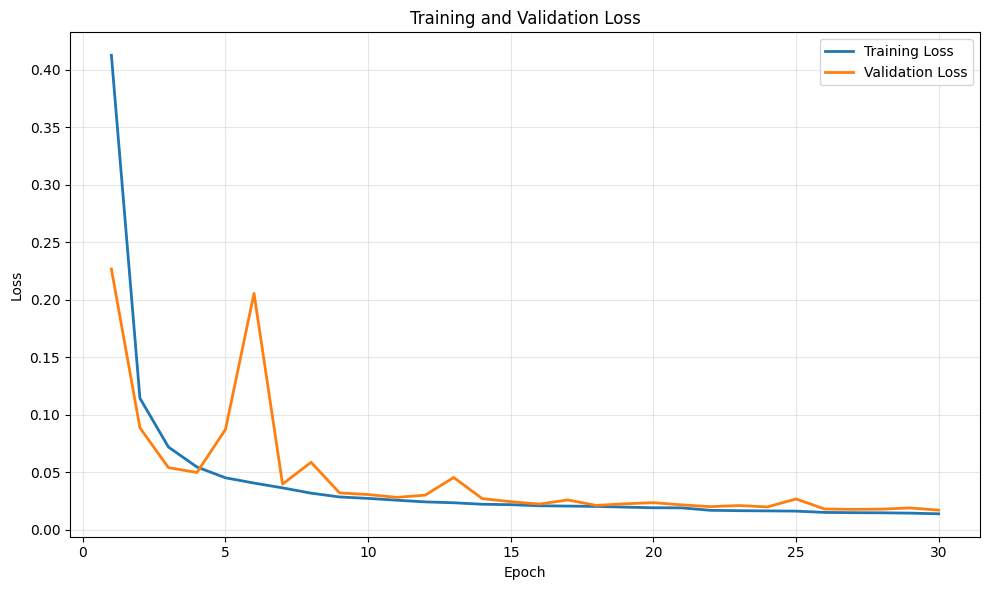

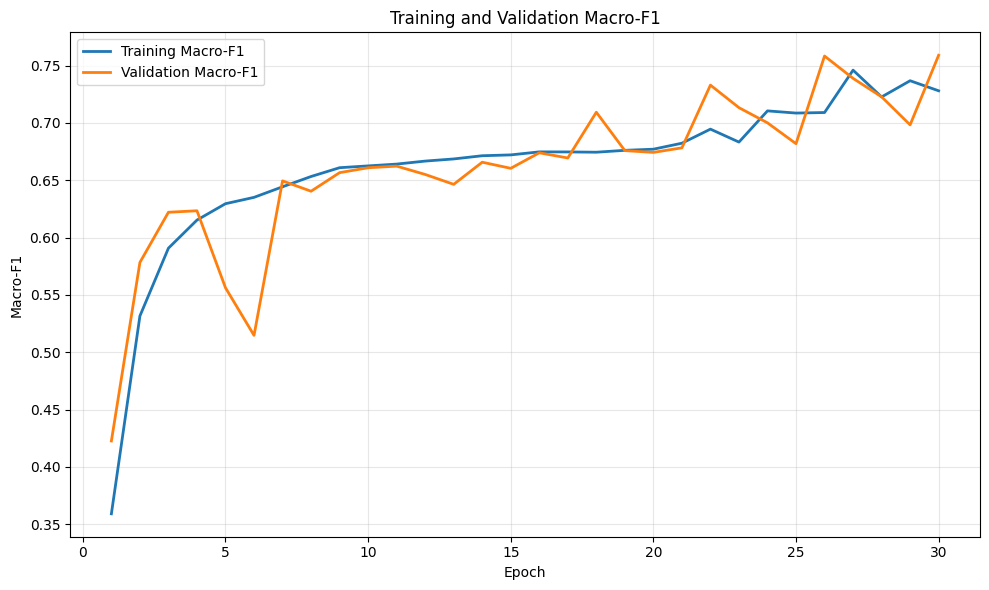

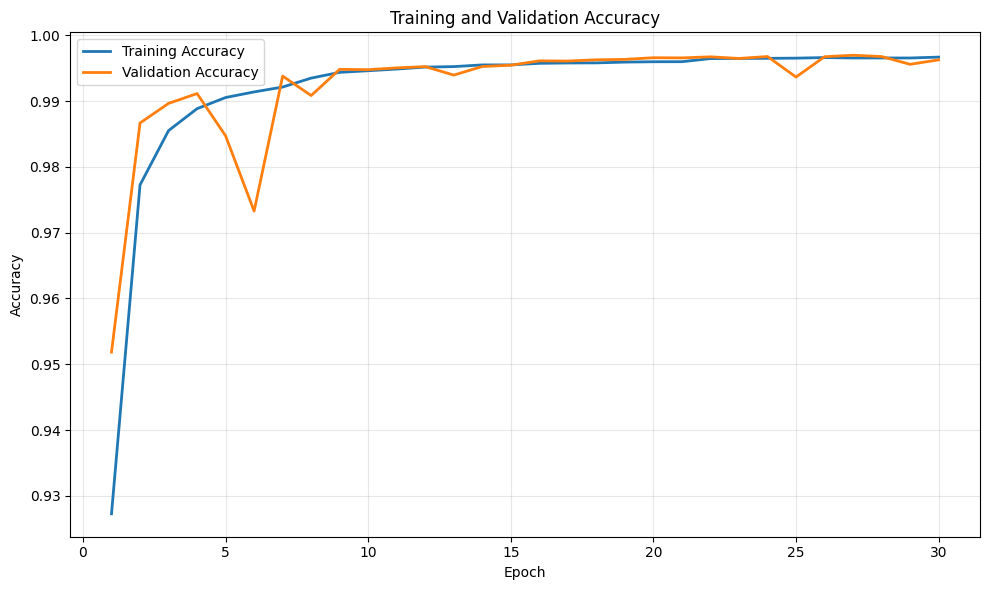

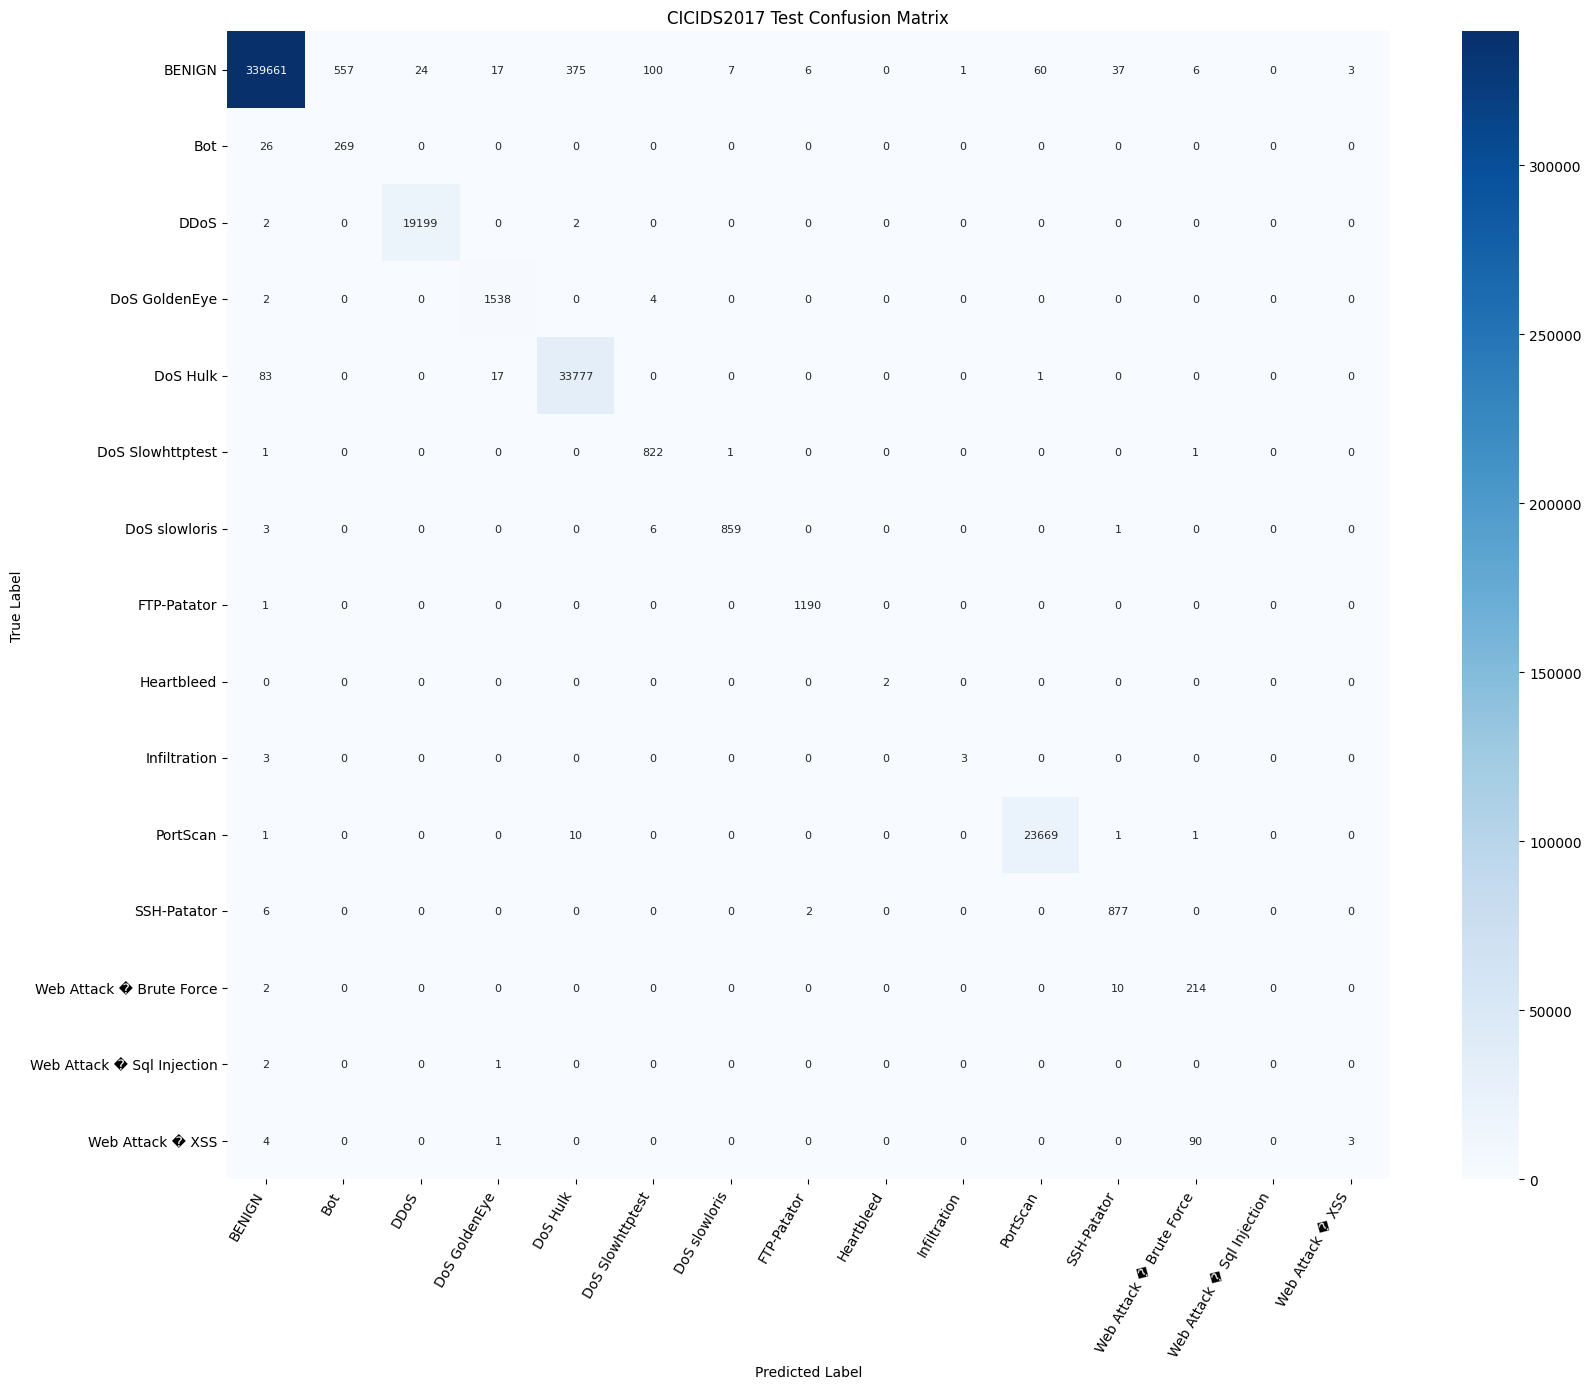

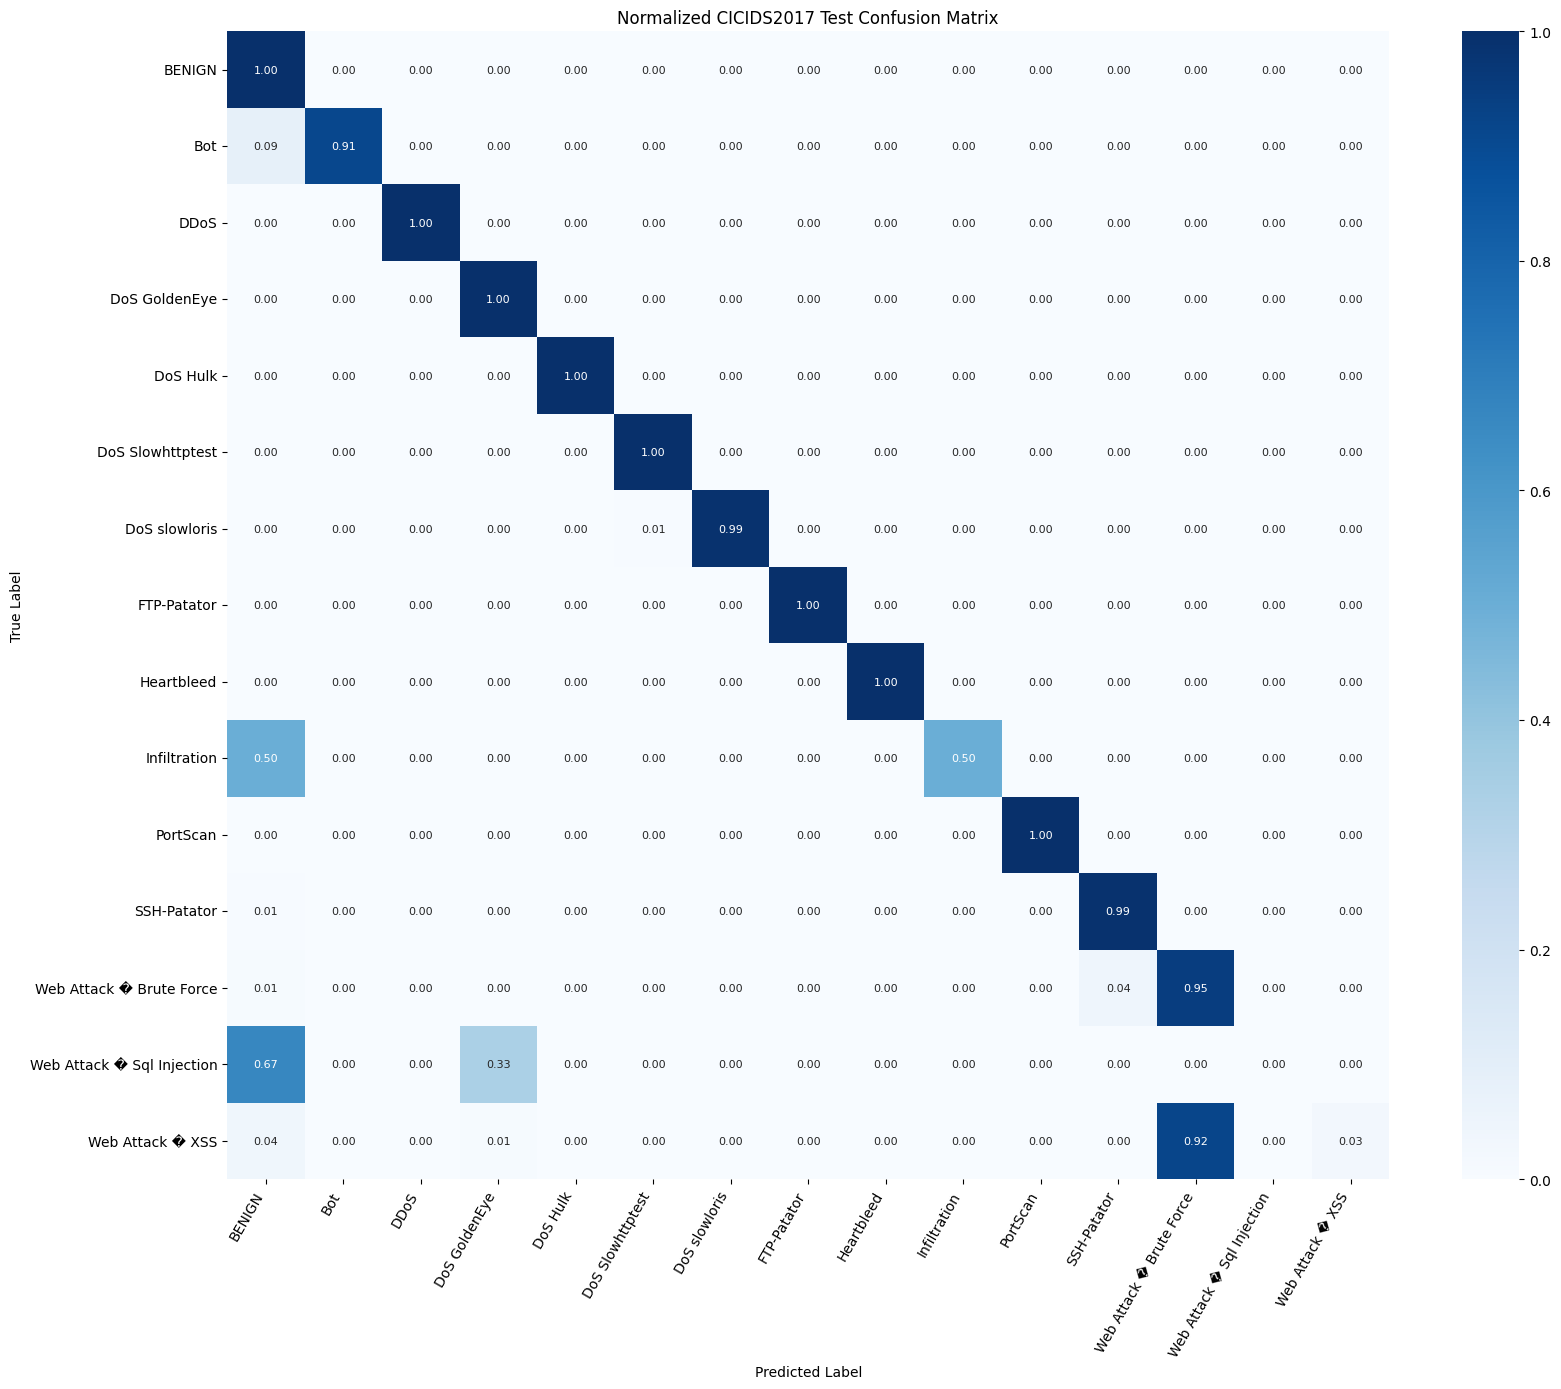

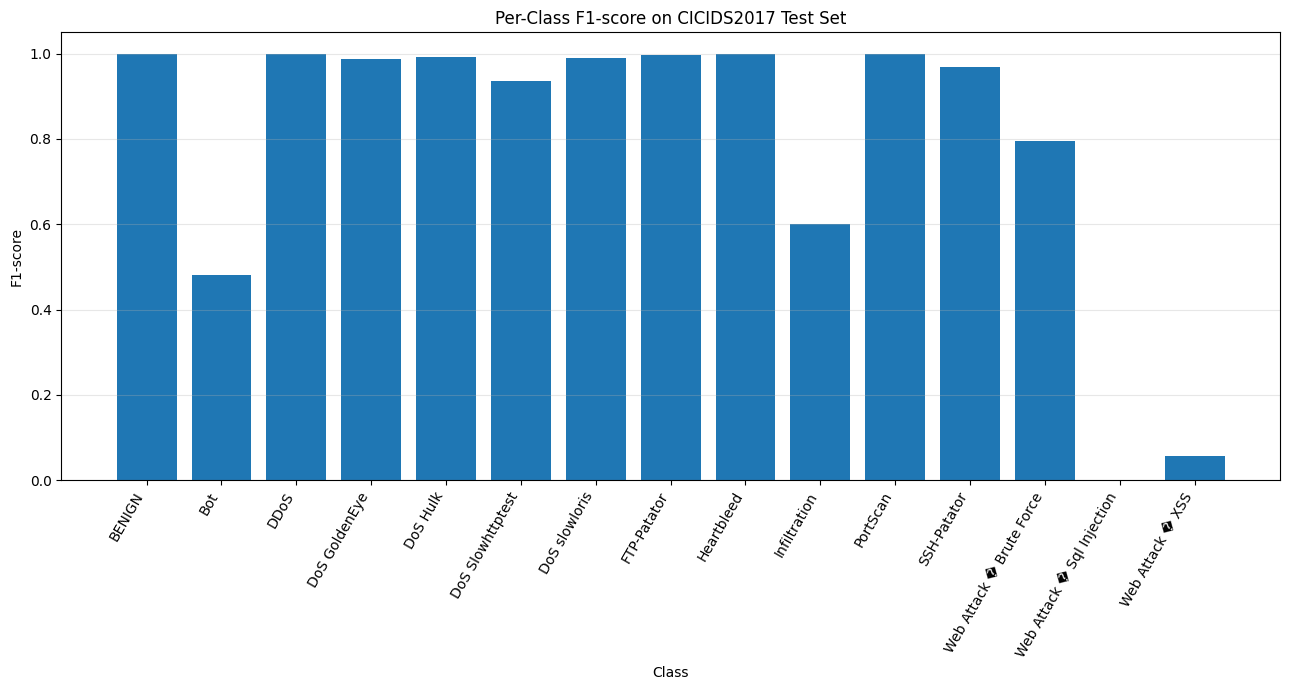


Generating ROC and Precision-Recall curves...


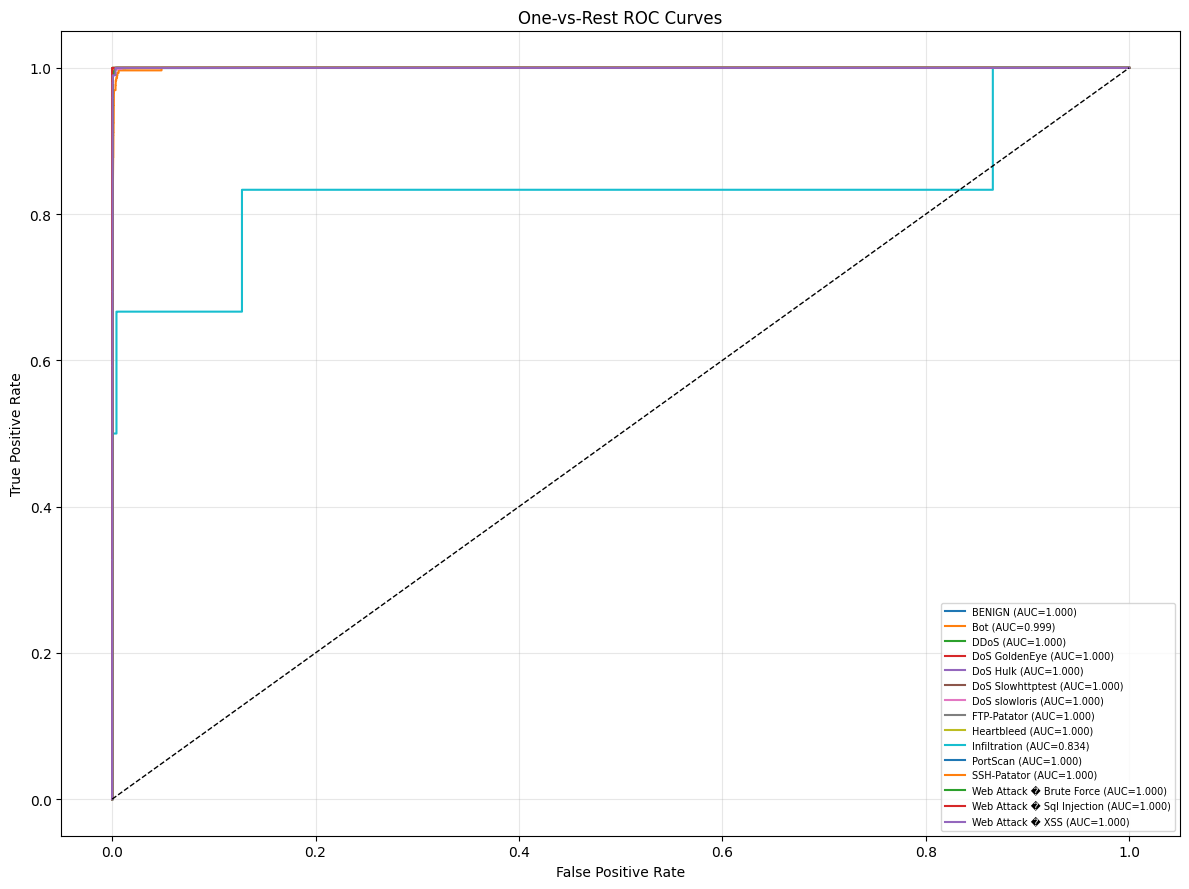

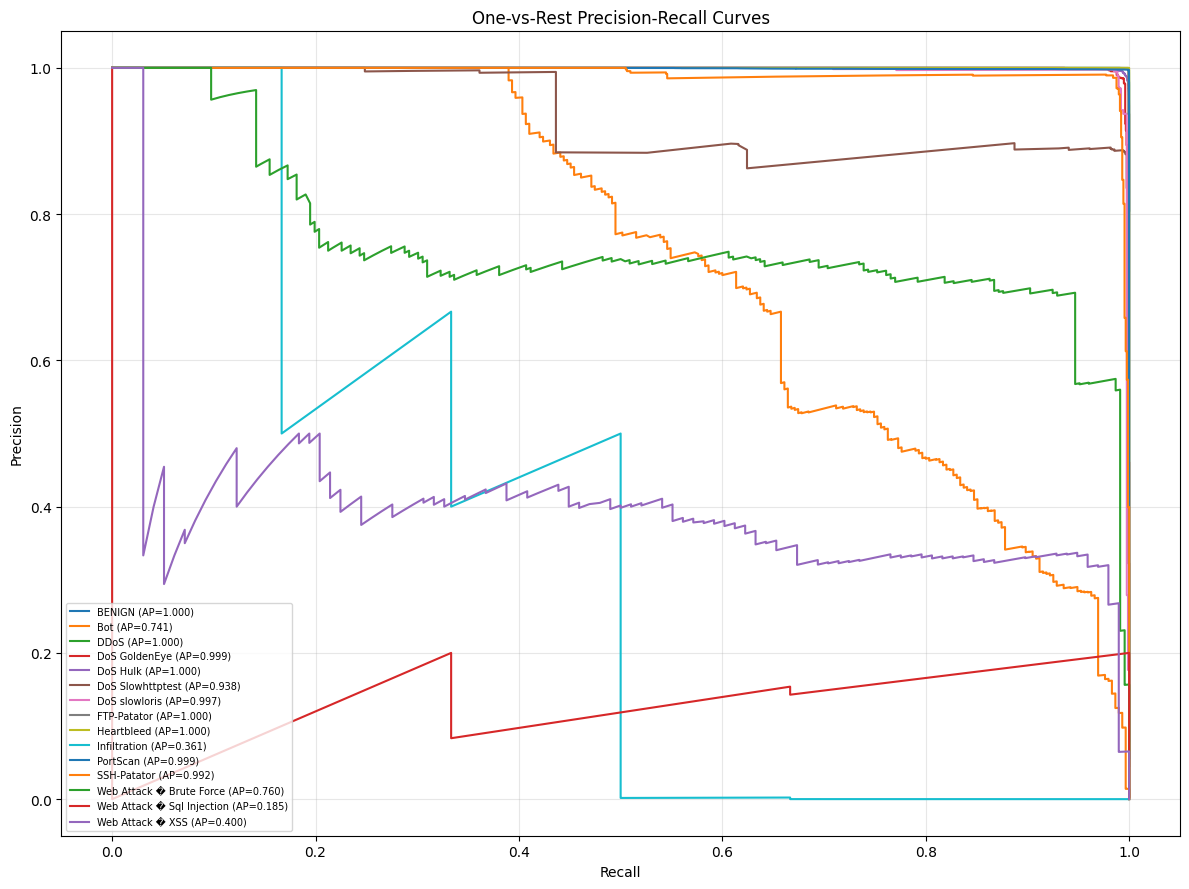


GENERATED RESEARCH FIGURES AND TABLES

 /content/CICIDS2017_Research_Paper_Outputs/03_Training_Results
training_history.csv | 6.05 KB
training_validation_accuracy.png | 160.54 KB
training_validation_loss.png | 157.12 KB
training_validation_macro_f1.png | 188.61 KB

 /content/CICIDS2017_Research_Paper_Outputs/04_Test_Evaluation
average_precision_per_class.csv | 0.49 KB
confusion_matrix.png | 540.28 KB
confusion_matrix_recreated.csv | 0.88 KB
normalized_confusion_matrix.png | 546.45 KB
per_class_f1.png | 292.39 KB
per_class_metrics.csv | 1.21 KB
precision_recall_curves.png | 393.19 KB
roc_auc_per_class.csv | 0.47 KB
roc_curves.png | 291.13 KB

CELL 30 COMPLETED


In [ ]:

# ============================================================
# CELL 30: GENERATE RESEARCH-PAPER FIGURES AND TRAINING TABLES
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)
from sklearn.preprocessing import label_binarize

print("=" * 100)
print("CELL 30: GENERATING RESEARCH-PAPER FIGURES AND TRAINING TABLES")
print("=" * 100)

# ------------------------------------------------------------
# 1. DIRECTORIES
# ------------------------------------------------------------

BASE_DIR = "/content/CICIDS2017_Research_Paper_Outputs"

TRAIN_DIR = os.path.join(BASE_DIR, "03_Training_Results")
EVAL_DIR = os.path.join(BASE_DIR, "04_Test_Evaluation")

os.makedirs(TRAIN_DIR, exist_ok=True)
os.makedirs(EVAL_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. TRAINING HISTORY CSV
# ------------------------------------------------------------

history_df = pd.DataFrame(training_history)

history_df.to_csv(
    os.path.join(TRAIN_DIR, "training_history.csv"),
    index=False
)

print("\nTraining history saved:", history_df.shape)

# ------------------------------------------------------------
# 3. TRAINING AND VALIDATION LOSS
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(TRAIN_DIR, "training_validation_loss.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 4. TRAINING AND VALIDATION MACRO-F1
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_macro_f1"],
    label="Training Macro-F1",
    linewidth=2
)

plt.plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    label="Validation Macro-F1",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("Training and Validation Macro-F1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(TRAIN_DIR, "training_validation_macro_f1.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 5. TRAINING AND VALIDATION ACCURACY
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(TRAIN_DIR, "training_validation_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 6. TEST CONFUSION MATRIX
# ------------------------------------------------------------

class_names_list = [str(x) for x in class_names]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names_list))
)

cm_df = pd.DataFrame(
    cm,
    index=class_names_list,
    columns=class_names_list
)

cm_df.to_csv(
    os.path.join(EVAL_DIR, "confusion_matrix_recreated.csv")
)

plt.figure(figsize=(17, 14))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names_list,
    yticklabels=class_names_list,
    annot=True,
    fmt="d",
    annot_kws={"size": 8}
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CICIDS2017 Test Confusion Matrix")
plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(EVAL_DIR, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 7. NORMALIZED CONFUSION MATRIX
# ------------------------------------------------------------

row_totals = cm.sum(axis=1, keepdims=True)

cm_normalized = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

plt.figure(figsize=(17, 14))

sns.heatmap(
    cm_normalized,
    cmap="Blues",
    xticklabels=class_names_list,
    yticklabels=class_names_list,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    vmin=0,
    vmax=1
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Normalized CICIDS2017 Test Confusion Matrix")
plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(EVAL_DIR, "normalized_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 8. PER-CLASS F1 FIGURE
# ------------------------------------------------------------

report_path = "/content/CICIDS2017_evaluation/classification_report.csv"

report_df = pd.read_csv(report_path)

report_df = report_df[
    report_df["Unnamed: 0"].isin(class_names_list)
].copy()

report_df["class"] = report_df["Unnamed: 0"].astype(str)
report_df = report_df.set_index("class").reindex(class_names_list)

report_df.reset_index().to_csv(
    os.path.join(EVAL_DIR, "per_class_metrics.csv"),
    index=False
)

plt.figure(figsize=(13, 7))

plt.bar(
    report_df.index,
    report_df["f1-score"]
)

plt.xlabel("Class")
plt.ylabel("F1-score")
plt.title("Per-Class F1-score on CICIDS2017 Test Set")
plt.xticks(rotation=60, ha="right")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(EVAL_DIR, "per_class_f1.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 9. ROC AND PRECISION-RECALL CURVES
# ------------------------------------------------------------

print("\nGenerating ROC and Precision-Recall curves...")

y_true_binary = label_binarize(
    y_true,
    classes=np.arange(len(class_names_list))
)

# One-vs-rest ROC
plt.figure(figsize=(12, 9))

roc_rows = []

for i, class_name in enumerate(class_names_list):
    if len(np.unique(y_true_binary[:, i])) < 2:
        continue

    fpr, tpr, _ = roc_curve(
        y_true_binary[:, i],
        probabilities[:, i]
    )

    class_auc = auc(fpr, tpr)

    roc_rows.append({
        "class": class_name,
        "roc_auc": class_auc
    })

    plt.plot(
        fpr,
        tpr,
        linewidth=1.5,
        label=f"{class_name} (AUC={class_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves")
plt.legend(loc="lower right", fontsize=7)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(EVAL_DIR, "roc_curves.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

pd.DataFrame(roc_rows).to_csv(
    os.path.join(EVAL_DIR, "roc_auc_per_class.csv"),
    index=False
)

# One-vs-rest Precision-Recall
plt.figure(figsize=(12, 9))

pr_rows = []

for i, class_name in enumerate(class_names_list):
    if y_true_binary[:, i].sum() == 0:
        continue

    precision, recall, _ = precision_recall_curve(
        y_true_binary[:, i],
        probabilities[:, i]
    )

    average_precision = average_precision_score(
        y_true_binary[:, i],
        probabilities[:, i]
    )

    pr_rows.append({
        "class": class_name,
        "average_precision": average_precision
    })

    plt.plot(
        recall,
        precision,
        linewidth=1.5,
        label=f"{class_name} (AP={average_precision:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("One-vs-Rest Precision-Recall Curves")
plt.legend(loc="best", fontsize=7)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(EVAL_DIR, "precision_recall_curves.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

pd.DataFrame(pr_rows).to_csv(
    os.path.join(EVAL_DIR, "average_precision_per_class.csv"),
    index=False
)

# ------------------------------------------------------------
# 10. FINAL OUTPUT INVENTORY
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("GENERATED RESEARCH FIGURES AND TABLES")
print("=" * 100)

for folder in [TRAIN_DIR, EVAL_DIR]:
    print("\n", folder)

    for filename in sorted(os.listdir(folder)):
        path = os.path.join(folder, filename)

        if os.path.isfile(path):
            print(
                filename,
                "|",
                round(os.path.getsize(path) / 1024, 2),
                "KB"
            )

print("\n" + "=" * 100)
print("CELL 30 COMPLETED")
print("=" * 100)


CELL 31: DATASET ANALYSIS AND PREPROCESSING TABLES

1. CLEANED DATASET CLASS DISTRIBUTION


,Class,Records,Percentage
0,BENIGN,2272361,80.473935
1,DoS Hulk,225849,7.998270
2,PortScan,157877,5.591094
3,DDoS,128021,4.533766
4,DoS GoldenEye,10293,0.364519
5,FTP-Patator,7938,0.281118
6,SSH-Patator,5897,0.208838
7,DoS slowloris,5795,0.205226
8,DoS Slowhttptest,5499,0.194743
9,Bot,1966,0.069624


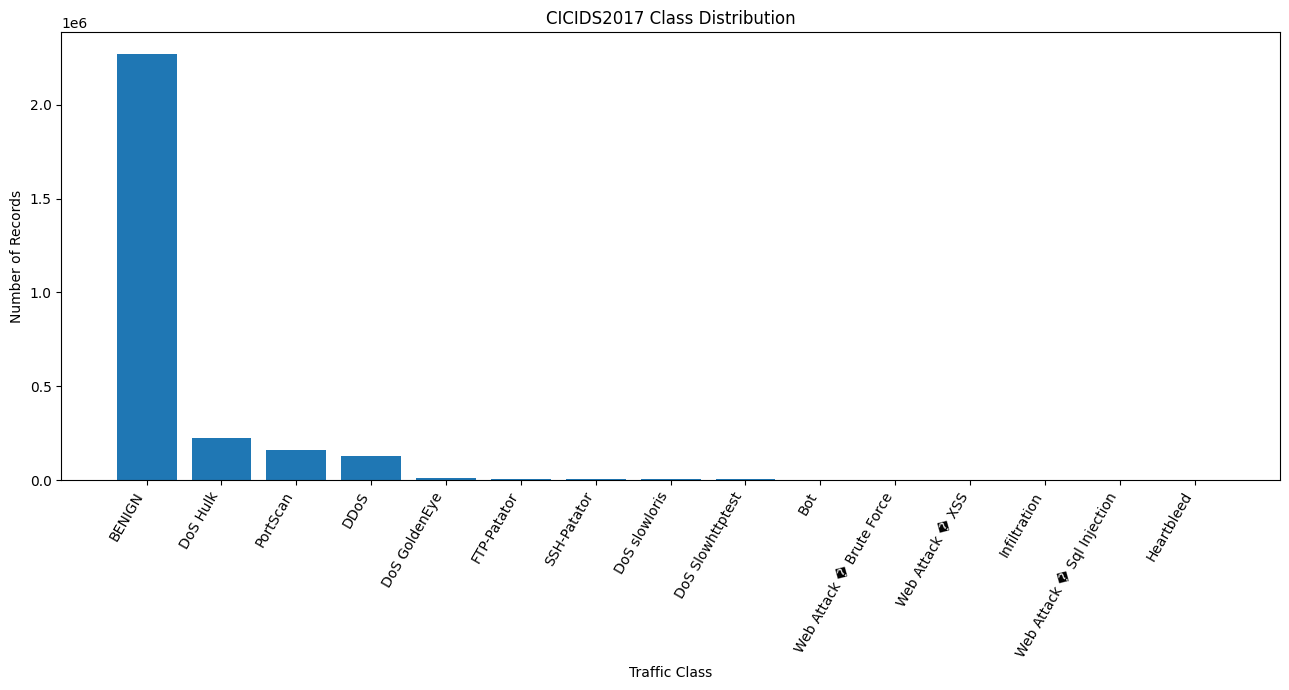


2. DATASET PARTITION SUMMARY


,Partition,Records,Number of Classes,Percentage
0,Train,1976599,15,69.999749
1,Validation,423563,15,15.000161
2,Test,423561,15,15.000090



3. FEATURE CONFIGURATION OBJECT
Type: dict
features : 71 items
log_features : 57 items
non_log_features : 14 items
log_indices : 57 items

4. PROCESSED FEATURE SUMMARY
Training rows: 1976599
Feature count: 71
Processed columns: 73


,Feature,Data Type,Missing Values,Unique Values
0,Destination Port,float32,0,49704
1,Flow Duration,float32,0,594803
2,Total Fwd Packets,float32,0,1223
3,Total Backward Packets,float32,0,1487
4,Total Length of Fwd Packets,float32,0,15407
...,...,...,...,...
66,Idle Std,float32,0,136638
67,Idle Max,float32,0,79682
68,Idle Min,float32,0,120233
69,Init_Win_bytes_forward_missing,float32,0,2



5. PREPROCESSING ARTIFACTS


,Artifact,File,Available,Object Type
0,Imputer,imputer.joblib,True,SimpleImputer
1,Scaler,scaler.joblib,True,StandardScaler
2,Label Encoder,label_encoder.joblib,True,LabelEncoder
3,Feature Config,feature_config.joblib,True,dict



6. GENERATED DATASET OUTPUTS
dataset_class_distribution.csv | 0.58 KB
dataset_class_distribution.png | 294.29 KB
dataset_split_summary.csv | 0.15 KB
feature_summary.csv | 2.29 KB
preprocessing_artifact_summary.csv | 0.21 KB
preprocessing_configuration.json | 4.64 KB

CELL 31 COMPLETED


In [ ]:

# ============================================================
# CELL 31: DATASET ANALYSIS AND PREPROCESSING TABLES
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 100)
print("CELL 31: DATASET ANALYSIS AND PREPROCESSING TABLES")
print("=" * 100)

BASE_DIR = "/content/CICIDS2017_Research_Paper_Outputs"
DATA_DIR = os.path.join(BASE_DIR, "01_Dataset_Analysis")

os.makedirs(DATA_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. DATASET CLASS DISTRIBUTION
# ------------------------------------------------------------

cleaned_path = "/content/CICIDS2017_cleaned.parquet"

if os.path.exists(cleaned_path):
    df = pd.read_parquet(cleaned_path, columns=["Label"])

    class_distribution = (
        df["Label"]
        .value_counts()
        .rename_axis("Class")
        .reset_index(name="Records")
    )

    class_distribution["Percentage"] = (
        class_distribution["Records"] /
        class_distribution["Records"].sum() * 100
    )

    class_distribution.to_csv(
        os.path.join(DATA_DIR, "dataset_class_distribution.csv"),
        index=False
    )

    print("\n1. CLEANED DATASET CLASS DISTRIBUTION")
    display(class_distribution)

    plt.figure(figsize=(13, 7))
    plt.bar(
        class_distribution["Class"],
        class_distribution["Records"]
    )
    plt.xlabel("Traffic Class")
    plt.ylabel("Number of Records")
    plt.title("CICIDS2017 Class Distribution")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.savefig(
        os.path.join(DATA_DIR, "dataset_class_distribution.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    del df

else:
    print("Cleaned dataset not found. Reading processed training data.")

    train_df = pd.read_parquet(
        "/content/CICIDS2017_processed/train_processed.parquet",
        columns=["Label"]
    )

    class_distribution = (
        train_df["Label"]
        .value_counts()
        .rename_axis("Class")
        .reset_index(name="Training Records")
    )

    class_distribution.to_csv(
        os.path.join(DATA_DIR, "training_class_distribution.csv"),
        index=False
    )

    display(class_distribution)
    del train_df

# ------------------------------------------------------------
# 2. PARTITION SUMMARY
# ------------------------------------------------------------

split_paths = {
    "Train": "/content/CICIDS2017_splits/train.parquet",
    "Validation": "/content/CICIDS2017_splits/validation.parquet",
    "Test": "/content/CICIDS2017_splits/test.parquet"
}

split_rows = []

for split_name, path in split_paths.items():
    if not os.path.exists(path):
        raise FileNotFoundError(path)

    split_df = pd.read_parquet(path, columns=["Label"])

    split_rows.append({
        "Partition": split_name,
        "Records": len(split_df),
        "Number of Classes": split_df["Label"].nunique()
    })

    del split_df

split_summary = pd.DataFrame(split_rows)
total_records = split_summary["Records"].sum()

split_summary["Percentage"] = (
    split_summary["Records"] / total_records * 100
)

split_summary.to_csv(
    os.path.join(DATA_DIR, "dataset_split_summary.csv"),
    index=False
)

print("\n2. DATASET PARTITION SUMMARY")
display(split_summary)

# ------------------------------------------------------------
# 3. FEATURE SUMMARY
# ------------------------------------------------------------

feature_config_path = (
    "/content/CICIDS2017_preprocessing/feature_config.joblib"
)

feature_config = joblib.load(feature_config_path)

print("\n3. FEATURE CONFIGURATION OBJECT")
print("Type:", type(feature_config).__name__)

if isinstance(feature_config, dict):
    for key, value in feature_config.items():
        if isinstance(value, (list, tuple, np.ndarray)):
            print(key, ":", len(value), "items")
        else:
            print(key, ":", value)

    with open(
        os.path.join(DATA_DIR, "preprocessing_configuration.json"),
        "w"
    ) as f:
        json.dump(
            feature_config,
            f,
            indent=4,
            default=lambda x: (
                x.tolist() if isinstance(x, np.ndarray) else str(x)
            )
        )

# ------------------------------------------------------------
# 4. PROCESSED FEATURE TABLE
# ------------------------------------------------------------

processed_path = (
    "/content/CICIDS2017_processed/train_processed.parquet"
)

processed_df = pd.read_parquet(processed_path)

target_columns = ["Label", "target"]

feature_columns = [
    col for col in processed_df.columns
    if col not in target_columns
]

feature_summary = pd.DataFrame({
    "Feature": feature_columns,
    "Data Type": [
        str(processed_df[col].dtype)
        for col in feature_columns
    ],
    "Missing Values": [
        int(processed_df[col].isna().sum())
        for col in feature_columns
    ],
    "Unique Values": [
        int(processed_df[col].nunique())
        for col in feature_columns
    ]
})

feature_summary.to_csv(
    os.path.join(DATA_DIR, "feature_summary.csv"),
    index=False
)

print("\n4. PROCESSED FEATURE SUMMARY")
print("Training rows:", len(processed_df))
print("Feature count:", len(feature_columns))
print("Processed columns:", len(processed_df.columns))
display(feature_summary)

del processed_df

# ------------------------------------------------------------
# 5. PREPROCESSING ARTIFACT SUMMARY
# ------------------------------------------------------------

artifact_paths = {
    "Imputer": "/content/CICIDS2017_preprocessing/imputer.joblib",
    "Scaler": "/content/CICIDS2017_preprocessing/scaler.joblib",
    "Label Encoder": "/content/CICIDS2017_preprocessing/label_encoder.joblib",
    "Feature Config": feature_config_path
}

artifact_summary = []

for artifact_name, path in artifact_paths.items():
    artifact = joblib.load(path)

    artifact_summary.append({
        "Artifact": artifact_name,
        "File": os.path.basename(path),
        "Available": os.path.exists(path),
        "Object Type": type(artifact).__name__
    })

artifact_df = pd.DataFrame(artifact_summary)

artifact_df.to_csv(
    os.path.join(DATA_DIR, "preprocessing_artifact_summary.csv"),
    index=False
)

print("\n5. PREPROCESSING ARTIFACTS")
display(artifact_df)

# ------------------------------------------------------------
# 6. FINAL INVENTORY
# ------------------------------------------------------------

print("\n6. GENERATED DATASET OUTPUTS")

for filename in sorted(os.listdir(DATA_DIR)):
    path = os.path.join(DATA_DIR, filename)

    if os.path.isfile(path):
        print(
            filename,
            "|",
            round(os.path.getsize(path) / 1024, 2),
            "KB"
        )

print("\n" + "=" * 100)
print("CELL 31 COMPLETED")
print("=" * 100)


CELL 32: MODEL ARCHITECTURE AND GRAPH STATISTICS

1. MODEL PARAMETERS


,Model,Total Parameters,Trainable Parameters,Number of Classes,Input Features,Branch Embedding Dimension
0,CNN-Transformer-GNN with Attention Fusion,110672,110672,15,71,64



2. BRANCH ARCHITECTURE


,Component,Configuration,Output Dimension
0,CNN Branch,Conv1D 1->32->64; kernel size 3; BatchNorm; Re...,64
1,Transformer Branch,Feature projection 1->64; 2 Transformer encode...,64
2,GNN Branch,Feature projection 1->64; 2 graph convolution ...,64
3,Attention Fusion,Linear 64->32; Tanh; Linear 32->1; Softmax acr...,64
4,MLP Classifier,Linear 64->128; ReLU; Dropout 0.2; Linear 128-...,15



3. GRAPH FILE CONTENTS
['adjacency', 'adjacency_with_self_loops', 'normalized_adjacency', 'correlation', 'features', 'threshold']
adjacency | Shape: (71, 71) | Type: float32
adjacency_with_self_loops | Shape: (71, 71) | Type: float32
normalized_adjacency | Shape: (71, 71) | Type: float32
correlation | Shape: (71, 71) | Type: float32
features | Shape: (71,) | Type: <U31
threshold | Shape: () | Type: float64

4. GRAPH SUMMARY


,Number of Nodes,Undirected Edges,Directed Adjacency Entries,Self Loops,Isolated Nodes,Average Degree,Maximum Degree,Minimum Degree,Correlation Threshold
0,71,1358,2716,0,2,38.253521,56,0,0.3



5. TOP 15 FEATURE NODES BY DEGREE


,Feature,Degree
23,Fwd IAT Max,56
21,Fwd IAT Mean,56
20,Fwd IAT Total,56
32,Fwd Header Length,55
2,Total Fwd Packets,55
53,Subflow Fwd Packets,55
22,Fwd IAT Std,54
25,Bwd IAT Total,53
28,Bwd IAT Max,53
27,Bwd IAT Std,53


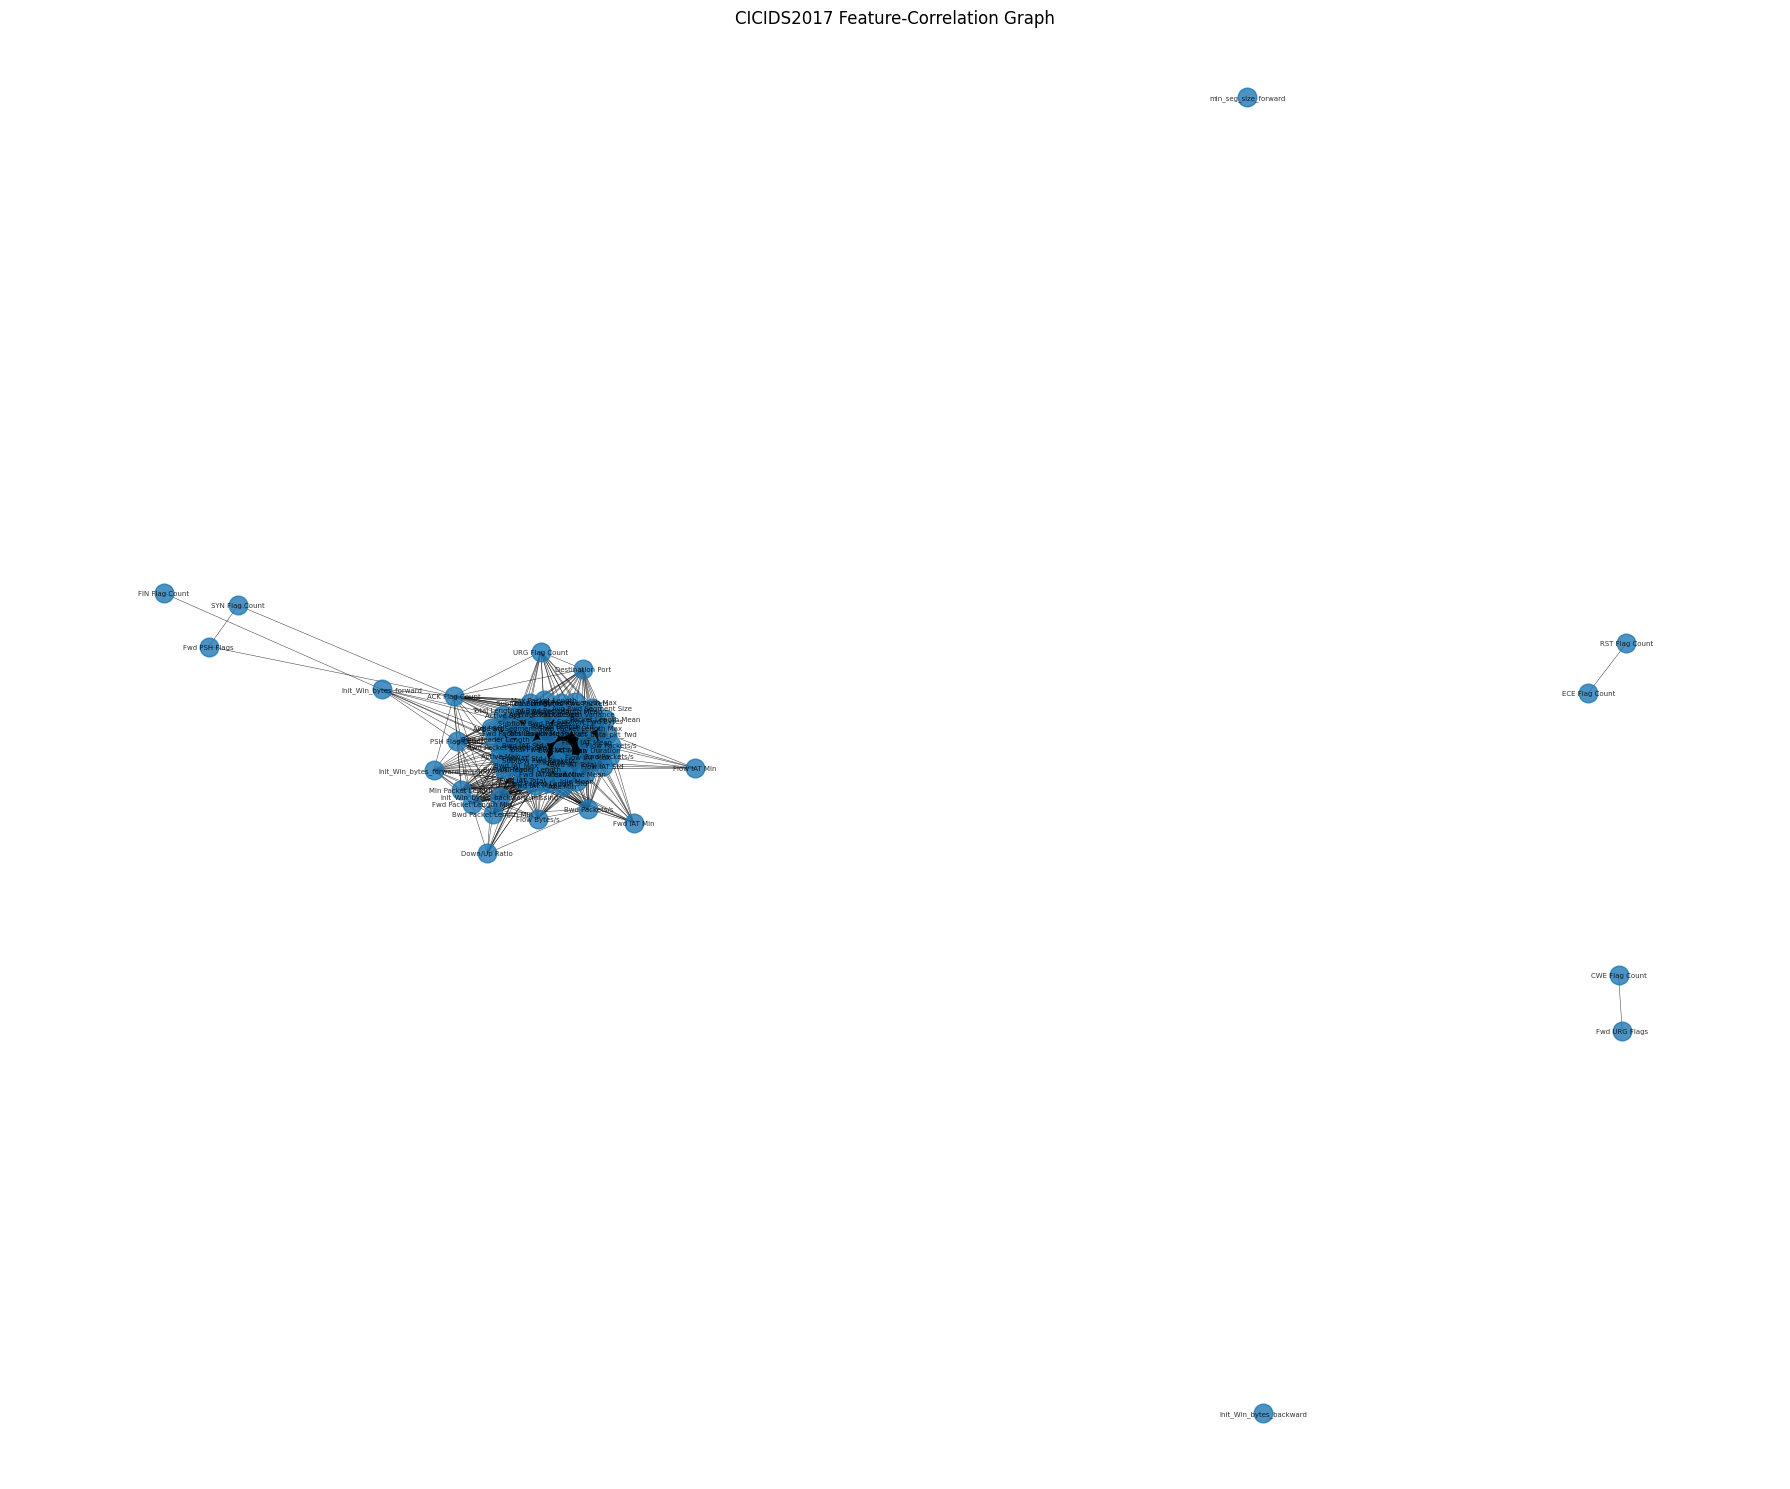

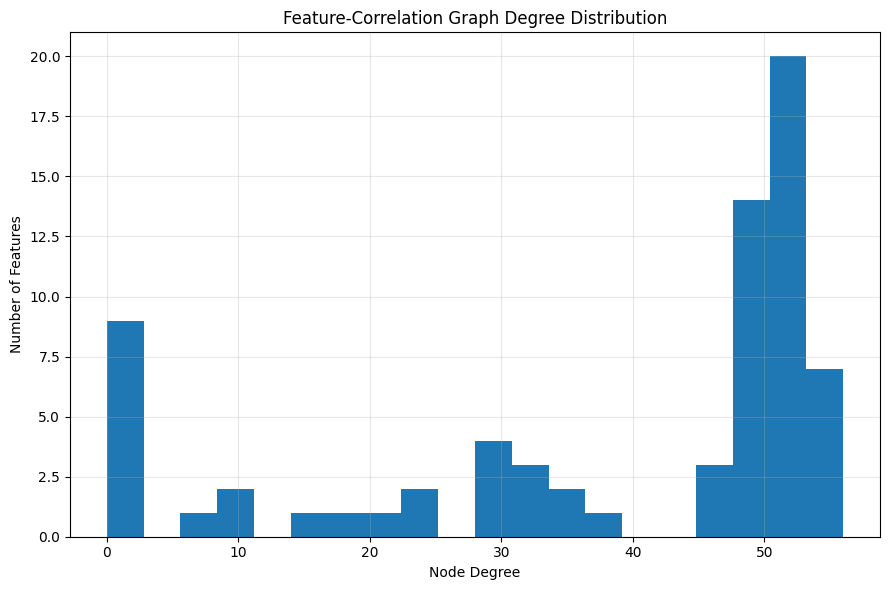


10. GENERATED MODEL OUTPUTS
branch_architecture_summary.csv | 0.48 KB
feature_correlation_graph.png | 769.08 KB
feature_graph_node_degrees.csv | 1.39 KB
graph_degree_distribution.png | 86.87 KB
graph_statistics.csv | 0.19 KB
model_architecture_description.txt | 1.45 KB
model_parameter_summary.csv | 0.17 KB
model_summary.txt | 2.32 KB

CELL 32 COMPLETED


In [ ]:

# ============================================================
# CELL 32: MODEL ARCHITECTURE AND GRAPH STATISTICS
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import networkx as nx

print("=" * 100)
print("CELL 32: MODEL ARCHITECTURE AND GRAPH STATISTICS")
print("=" * 100)

BASE_DIR = "/content/CICIDS2017_Research_Paper_Outputs"
MODEL_DIR = os.path.join(BASE_DIR, "02_Model_Architecture")

os.makedirs(MODEL_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. MODEL PARAMETER SUMMARY
# ------------------------------------------------------------

total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

parameter_summary = pd.DataFrame([
    {
        "Model": "CNN-Transformer-GNN with Attention Fusion",
        "Total Parameters": total_parameters,
        "Trainable Parameters": trainable_parameters,
        "Number of Classes": len(class_names),
        "Input Features": 71,
        "Branch Embedding Dimension": 64
    }
])

parameter_summary.to_csv(
    os.path.join(MODEL_DIR, "model_parameter_summary.csv"),
    index=False
)

print("\n1. MODEL PARAMETERS")
display(parameter_summary)

# ------------------------------------------------------------
# 2. BRANCH ARCHITECTURE SUMMARY
# ------------------------------------------------------------

branch_summary = pd.DataFrame([
    {
        "Component": "CNN Branch",
        "Configuration": "Conv1D 1->32->64; kernel size 3; BatchNorm; ReLU; Adaptive Average Pooling",
        "Output Dimension": 64
    },
    {
        "Component": "Transformer Branch",
        "Configuration": "Feature projection 1->64; 2 Transformer encoder layers; 4 attention heads; FFN 128; dropout 0.1",
        "Output Dimension": 64
    },
    {
        "Component": "GNN Branch",
        "Configuration": "Feature projection 1->64; 2 graph convolution layers; LayerNorm",
        "Output Dimension": 64
    },
    {
        "Component": "Attention Fusion",
        "Configuration": "Linear 64->32; Tanh; Linear 32->1; Softmax across 3 branches",
        "Output Dimension": 64
    },
    {
        "Component": "MLP Classifier",
        "Configuration": "Linear 64->128; ReLU; Dropout 0.2; Linear 128->64; ReLU; Linear 64->15",
        "Output Dimension": 15
    }
])

branch_summary.to_csv(
    os.path.join(MODEL_DIR, "branch_architecture_summary.csv"),
    index=False
)

print("\n2. BRANCH ARCHITECTURE")
display(branch_summary)

# ------------------------------------------------------------
# 3. GRAPH FILE AUDIT
# ------------------------------------------------------------

graph_path = "/content/CICIDS2017_gnn_graph.npz"

if not os.path.exists(graph_path):
    raise FileNotFoundError(
        "CICIDS2017_gnn_graph.npz not found."
    )

graph_data = np.load(graph_path, allow_pickle=True)

print("\n3. GRAPH FILE CONTENTS")
print(graph_data.files)

for key in graph_data.files:
    value = graph_data[key]
    print(key, "| Shape:", value.shape, "| Type:", value.dtype)

# ------------------------------------------------------------
# 4. GRAPH STATISTICS
# ------------------------------------------------------------

adjacency = graph_data["adjacency"]
normalized_adjacency = graph_data["normalized_adjacency"]
feature_names = graph_data["features"].astype(str)

num_nodes = adjacency.shape[0]
num_directed_edges = int(np.count_nonzero(adjacency))
num_undirected_edges = int(
    np.count_nonzero(np.triu(adjacency, k=1))
)

degrees = np.sum(adjacency > 0, axis=1)
isolated_nodes = int(np.sum(degrees == 0))

graph_summary = pd.DataFrame([{
    "Number of Nodes": num_nodes,
    "Undirected Edges": num_undirected_edges,
    "Directed Adjacency Entries": num_directed_edges,
    "Self Loops": int(np.sum(np.diag(adjacency) > 0)),
    "Isolated Nodes": isolated_nodes,
    "Average Degree": float(degrees.mean()),
    "Maximum Degree": int(degrees.max()),
    "Minimum Degree": int(degrees.min()),
    "Correlation Threshold": float(graph_data["threshold"])
}])

graph_summary.to_csv(
    os.path.join(MODEL_DIR, "graph_statistics.csv"),
    index=False
)

print("\n4. GRAPH SUMMARY")
display(graph_summary)

# ------------------------------------------------------------
# 5. NODE DEGREE TABLE
# ------------------------------------------------------------

node_degree_df = pd.DataFrame({
    "Feature": feature_names,
    "Degree": degrees
}).sort_values("Degree", ascending=False)

node_degree_df.to_csv(
    os.path.join(MODEL_DIR, "feature_graph_node_degrees.csv"),
    index=False
)

print("\n5. TOP 15 FEATURE NODES BY DEGREE")
display(node_degree_df.head(15))

# ------------------------------------------------------------
# 6. GRAPH VISUALIZATION
# ------------------------------------------------------------

G = nx.from_numpy_array((adjacency > 0).astype(int))

mapping = {
    i: str(feature_names[i])
    for i in range(len(feature_names))
}

G = nx.relabel_nodes(G, mapping)

plt.figure(figsize=(18, 15))

pos = nx.spring_layout(
    G,
    seed=42,
    k=0.35,
    iterations=100
)

nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_size=180,
    font_size=5,
    width=0.35,
    alpha=0.8
)

plt.title("CICIDS2017 Feature-Correlation Graph")
plt.axis("off")
plt.tight_layout()

plt.savefig(
    os.path.join(MODEL_DIR, "feature_correlation_graph.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 7. GRAPH DEGREE DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.hist(
    degrees,
    bins=20
)

plt.xlabel("Node Degree")
plt.ylabel("Number of Features")
plt.title("Feature-Correlation Graph Degree Distribution")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(MODEL_DIR, "graph_degree_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 8. ARCHITECTURE DESCRIPTION
# ------------------------------------------------------------

architecture_text = """
MODEL: CNN-TRANSFORMER-GNN WITH ATTENTION FUSION

Input:
- 71 preprocessed numerical traffic features.

CNN Branch:
- Conv1D: 1 to 32 channels, kernel size 3.
- Batch Normalization and ReLU.
- Conv1D: 32 to 64 channels, kernel size 3.
- Batch Normalization and ReLU.
- Adaptive average pooling.
- Linear projection to 64 dimensions.

Transformer Branch:
- Feature projection: 1 to 64.
- Learned positional embeddings.
- Two Transformer encoder layers.
- Four attention heads.
- Feed-forward dimension: 128.
- Dropout: 0.1.
- Layer normalization and mean pooling.

GNN Branch:
- Feature nodes represented by scalar inputs.
- Input projection: 1 to 64.
- Two graph-convolution-like layers.
- Feature-correlation adjacency matrix.
- Layer normalization and mean pooling.

Attention Fusion:
- Each branch produces a 64-dimensional representation.
- Attention network: 64 to 32 to 1.
- Softmax across the three branches.
- Weighted sum of branch representations.

Classifier:
- Linear: 64 to 128.
- ReLU and dropout 0.2.
- Linear: 128 to 64.
- ReLU.
- Linear: 64 to 15 classes.

Total parameters: {}
Trainable parameters: {}

IMPORTANT DATASET LIMITATION:
The CICIDS2017 MachineLearningCSV files do not provide the
timestamps and network topology identifiers required to
interpret the Transformer as a true temporal traffic model
or the GNN as a physical network-topology model.

The Transformer operates on ordered feature tokens.
The GNN operates on a feature-correlation graph.
""".format(total_parameters, trainable_parameters)

with open(
    os.path.join(MODEL_DIR, "model_architecture_description.txt"),
    "w"
) as f:
    f.write(architecture_text)

# ------------------------------------------------------------
# 9. MODEL SUMMARY TEXT
# ------------------------------------------------------------

with open(
    os.path.join(MODEL_DIR, "model_summary.txt"),
    "w"
) as f:
    f.write(str(model))

# ------------------------------------------------------------
# 10. FINAL OUTPUT INVENTORY
# ------------------------------------------------------------

print("\n10. GENERATED MODEL OUTPUTS")

for filename in sorted(os.listdir(MODEL_DIR)):
    path = os.path.join(MODEL_DIR, filename)

    if os.path.isfile(path):
        print(
            filename,
            "|",
            round(os.path.getsize(path) / 1024, 2),
            "KB"
        )

print("\n" + "=" * 100)
print("CELL 32 COMPLETED")
print("=" * 100)


In [ ]:

# ============================================================
# CELL 33: MODEL COMPLEXITY, INFERENCE LATENCY AND THROUGHPUT
# ============================================================

import os
import io
import time
import numpy as np
import pandas as pd
import torch

print("=" * 100)
print("CELL 33: MODEL COMPLEXITY AND INFERENCE BENCHMARK")
print("=" * 100)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

BASE_DIR = "/content/CICIDS2017_Research_Paper_Outputs"
OUTPUT_DIR = os.path.join(BASE_DIR, "05_Efficiency_Analysis")

os.makedirs(OUTPUT_DIR, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.eval()

graph_data = np.load(
    "/content/CICIDS2017_gnn_graph.npz",
    allow_pickle=True
)

adjacency = torch.tensor(
    graph_data["normalized_adjacency"],
    dtype=torch.float32,
    device=device
)

X_benchmark = torch.tensor(
    np.asarray(X_test),
    dtype=torch.float32
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Benchmark samples:", len(X_benchmark))
print("Input features:", X_benchmark.shape[1])

# ------------------------------------------------------------
# 2. MODEL COMPLEXITY
# ------------------------------------------------------------

total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

parameter_memory_mb = (
    sum(p.numel() * p.element_size() for p in model.parameters())
    / (1024 ** 2)
)

buffer_memory_mb = (
    sum(b.numel() * b.element_size() for b in model.buffers())
    / (1024 ** 2)
)

# Measure serialized state dictionary size in memory
checkpoint_buffer = io.BytesIO()

torch.save(
    model.state_dict(),
    checkpoint_buffer
)

serialized_model_size_mb = (
    checkpoint_buffer.tell() / (1024 ** 2)
)

complexity_summary = pd.DataFrame([{
    "Total Parameters": total_parameters,
    "Trainable Parameters": trainable_parameters,
    "Parameter Memory MB": parameter_memory_mb,
    "Buffer Memory MB": buffer_memory_mb,
    "Serialized State Dict MB": serialized_model_size_mb,
    "Input Features": X_benchmark.shape[1],
    "Output Classes": len(class_names)
}])

complexity_summary.to_csv(
    os.path.join(OUTPUT_DIR, "model_complexity.csv"),
    index=False
)

print("\n1. MODEL COMPLEXITY")
display(complexity_summary)

del checkpoint_buffer

# ------------------------------------------------------------
# 3. LATENCY AND THROUGHPUT BENCHMARK
# ------------------------------------------------------------

def synchronize_device():
    if device.type == "cuda":
        torch.cuda.synchronize()


def benchmark_batch(batch_size, warmup=20, repetitions=100):

    sample_count = min(batch_size, len(X_benchmark))

    x_cpu = X_benchmark[:sample_count]

    # Measure host-to-device transfer separately
    transfer_times = []

    for _ in range(repetitions):
        start = time.perf_counter()

        x_gpu = x_cpu.to(device, non_blocking=False)

        synchronize_device()

        transfer_times.append(
            (time.perf_counter() - start) * 1000
        )

    x_gpu = x_cpu.to(device)

    # Warmup
    with torch.inference_mode():
        for _ in range(warmup):
            logits, weights = model(x_gpu, adjacency)

    synchronize_device()

    # GPU model execution latency
    inference_times = []

    with torch.inference_mode():
        for _ in range(repetitions):
            synchronize_device()
            start = time.perf_counter()

            logits, weights = model(x_gpu, adjacency)

            synchronize_device()

            inference_times.append(
                (time.perf_counter() - start) * 1000
            )

    # End-to-end batch latency: transfer + inference
    end_to_end_times = []

    with torch.inference_mode():
        for _ in range(repetitions):
            synchronize_device()
            start = time.perf_counter()

            x_gpu = x_cpu.to(device)
            logits, weights = model(x_gpu, adjacency)

            synchronize_device()

            end_to_end_times.append(
                (time.perf_counter() - start) * 1000
            )

    median_latency = float(np.median(inference_times))
    median_end_to_end = float(np.median(end_to_end_times))

    return {
        "Batch Size": sample_count,
        "GPU Inference Median ms": median_latency,
        "GPU Inference Mean ms": float(np.mean(inference_times)),
        "GPU Inference P95 ms": float(np.percentile(inference_times, 95)),
        "End-to-End Median ms": median_end_to_end,
        "Transfer Median ms": float(np.median(transfer_times)),
        "Throughput Samples/sec": (
            sample_count / (median_latency / 1000)
        ),
        "End-to-End Throughput Samples/sec": (
            sample_count / (median_end_to_end / 1000)
        )
    }


batch_sizes = [1, 32, 128, 512, 1024]

benchmark_results = []

print("\n2. RUNNING INFERENCE BENCHMARKS")

for batch_size in batch_sizes:

    result = benchmark_batch(
        batch_size=batch_size,
        warmup=20,
        repetitions=100
    )

    benchmark_results.append(result)

    print(
        f"Batch {result['Batch Size']:4d} | "
        f"GPU median {result['GPU Inference Median ms']:.4f} ms | "
        f"Throughput {result['Throughput Samples/sec']:.2f} samples/sec"
    )

latency_df = pd.DataFrame(benchmark_results)

latency_df.to_csv(
    os.path.join(OUTPUT_DIR, "inference_latency_throughput.csv"),
    index=False
)

print("\n3. COMPLETE LATENCY AND THROUGHPUT TABLE")
display(latency_df)

# ------------------------------------------------------------
# 4. SINGLE-SAMPLE LATENCY SUMMARY
# ------------------------------------------------------------

single_sample = latency_df[
    latency_df["Batch Size"] == 1
].iloc[0]

single_latency_summary = pd.DataFrame([{
    "Single Sample GPU Latency ms":
        single_sample["GPU Inference Median ms"],
    "Single Sample End-to-End Latency ms":
        single_sample["End-to-End Median ms"],
    "Single Sample Throughput":
        single_sample["Throughput Samples/sec"]
}])

single_latency_summary.to_csv(
    os.path.join(OUTPUT_DIR, "single_sample_latency.csv"),
    index=False
)

print("\n4. SINGLE-SAMPLE LATENCY")
display(single_latency_summary)

# ------------------------------------------------------------
# 5. HARDWARE AND SOFTWARE CONFIGURATION
# ------------------------------------------------------------

hardware_info = {
    "PyTorch Version": torch.__version__,
    "CUDA Available": torch.cuda.is_available(),
    "Device": str(device),
    "GPU Name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "CPU"
    ),
    "GPU Memory GB": (
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3), 3
        )
        if torch.cuda.is_available()
        else None
    ),
    "Benchmark Dataset": "CICIDS2017 Test Set",
    "Benchmark Samples": len(X_benchmark),
    "Model Parameters": total_parameters,
    "Precision": "FP32 model parameters; benchmark execution mode"
}

hardware_df = pd.DataFrame(
    list(hardware_info.items()),
    columns=["Property", "Value"]
)

hardware_df.to_csv(
    os.path.join(OUTPUT_DIR, "hardware_configuration.csv"),
    index=False
)

print("\n5. HARDWARE CONFIGURATION")
display(hardware_df)

# ------------------------------------------------------------
# 6. FINAL INVENTORY
# ------------------------------------------------------------

print("\n6. GENERATED EFFICIENCY OUTPUTS")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    path = os.path.join(OUTPUT_DIR, filename)

    if os.path.isfile(path):
        print(
            filename,
            "|",
            round(os.path.getsize(path) / 1024, 2),
            "KB"
        )

print("\n" + "=" * 100)
print("CELL 33 COMPLETED")
print("=" * 100)


CELL 33: MODEL COMPLEXITY AND INFERENCE BENCHMARK
Device: cuda
GPU: Tesla T4
Benchmark samples: 423561
Input features: 71

1. MODEL COMPLEXITY


,Total Parameters,Trainable Parameters,Parameter Memory MB,Buffer Memory MB,Serialized State Dict MB,Input Features,Output Classes
0,110672,110672,0.42218,0.000748,0.444555,71,15



2. RUNNING INFERENCE BENCHMARKS
Batch    1 | GPU median 2.0218 ms | Throughput 494.61 samples/sec
Batch   32 | GPU median 2.2018 ms | Throughput 14533.30 samples/sec
Batch  128 | GPU median 3.0725 ms | Throughput 41660.53 samples/sec
Batch  512 | GPU median 10.7868 ms | Throughput 47465.35 samples/sec
Batch 1024 | GPU median 21.0822 ms | Throughput 48571.87 samples/sec

3. COMPLETE LATENCY AND THROUGHPUT TABLE


,Batch Size,GPU Inference Median ms,GPU Inference Mean ms,GPU Inference P95 ms,End-to-End Median ms,Transfer Median ms,Throughput Samples/sec,End-to-End Throughput Samples/sec
0,1,2.021815,2.199479,3.286692,2.043718,0.038152,494.605095,489.304297
1,32,2.201841,2.259679,2.629252,2.171529,0.064027,14533.296118,14736.160561
2,128,3.072452,3.150713,3.837077,3.075146,0.078623,41660.530153,41624.046724
3,512,10.786815,10.794771,11.037680,10.942445,0.156390,47465.354695,46790.274019
4,1024,21.082160,21.164524,21.526929,21.293621,0.321785,48571.874243,48089.519392



4. SINGLE-SAMPLE LATENCY


,Single Sample GPU Latency ms,Single Sample End-to-End Latency ms,Single Sample Throughput
0,2.021815,2.043718,494.605095



5. HARDWARE CONFIGURATION


,Property,Value
0,PyTorch Version,2.14.1+cu130
1,CUDA Available,True
2,Device,cuda
3,GPU Name,Tesla T4
4,GPU Memory GB,14.563
5,Benchmark Dataset,CICIDS2017 Test Set
6,Benchmark Samples,423561
7,Model Parameters,110672
8,Precision,FP32 model parameters; benchmark execution mode



6. GENERATED EFFICIENCY OUTPUTS
hardware_configuration.csv | 0.25 KB
inference_latency_throughput.csv | 0.83 KB
model_complexity.csv | 0.2 KB
single_sample_latency.csv | 0.14 KB

CELL 33 COMPLETED
